# Mixed-length training (lengths 0, 2, 3, 4, 5) — `mixed_02345_all_pairs`

**Question.** Models are trained FROM SCRATCH on instructions with 0, 2, 3, 4 or 5 operations but **never** on a
single operation. Can they execute the individual operations A, B, C at test time?

**Task.** 6x6 grids of digits 0-9; `A` = shift right by one with wrap, `B` = rotate 90° clockwise, `C` = mirror
left-right. Words run **left to right** (`AB` = B(A(X))). The EMPTY word has zero operations (target = input).

**Training support of this notebook (361 words):** EMPTY; length 2: **AA, AB, AC, BA, BB, BC, CA, CB, CC**; all 27 length-3, 81 length-4 and
243 length-5 words (repeats allowed). Length 1 is never trained or used for validation.
The sibling experiment differs **only** in its length-two support.

**Sampling.** Each length (0/2/3/4/5) gets exactly 20% of the 1,280,000 training examples (5000 steps x batch 256,
seed 42); words are balanced within a length; operations occupy a uniformly random order-preserving subset of
**five operation slots** (others PAD). Pairs now receive only 20% of the budget, unlike the original length-two-only
experiments, so old/new differences are not attributable to any single factor.

**Checkpoint selection** uses 300 validation grids x one word at each of the 5 trained lengths (1,500 records), by the
length-macro final-answer cell CE (AR: teacher-forced digit CE). **Test**: the selected checkpoint on all **364 words**
(lengths 0-5, incl. EMPTY and the never-trained singles) x 1000 held-out grids = 364,000 records/model; AR decoding is
free-running. Lengths 3-5 are *seen strings on new grids*, not unseen-combination generalization.

After evaluation this notebook runs the post-hoc diagnostics (288-transformation matching, explicit error rules with
denominators, fitted rules/maps on a FIT/DIAG split, composition, controls). One seed: descriptive only.

**Run:** GPU runtime -> *Run all*. Authentication as in notebooks 01-03 (`GITHUB_TOKEN` Colab secret or hidden prompt).
Results persist on Drive; rerun *Run all* to resume (completed stages are verified and skipped).


In [3]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc


In [4]:
# --- CONFIGURATION ------------------------------------------------------------------------------------
EXPERIMENT = "mixed_02345_all_pairs"   # fixed for this notebook
MODE = os.environ.get("DECOMP_MODE", "full")   # "full" = benchmark | "smoke" = tiny integration run (NOT results)
SEED = 42
MODELS = os.environ.get("DECOMP_MODELS", "transformer_ar,looped_transformer_ar,transformer_encoder,"
                        "looped_transformer_encoder,vit,looped_vit,trm,rescnn_film,unet_film").split(",")
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE
    else "/content/decompositionality_results" if IN_COLAB else str(REPO_DIR / "results"))
MIXED_ROOT = f"{RESULTS_ROOT}/mixed_length_02345"   # NEW subtree; legacy results are never touched
RESUME = True
OPTIMIZER_STEPS = None          # None = mode default (full: 5000)
EFFECTIVE_BATCH = None          # None = mode default (full: 256)
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
DTYPE = "auto"                  # bf16 if supported, else fp16 + GradScaler; "fp32" disables AMP
MICROBATCH = None               # None = probe with dummy data (effective batch never reduced)
ACTIVATION_CHECKPOINTING = False
N_SLOTS = 5                     # five operation slots (fixed for these experiments; legacy models use 3)
EVAL_CHUNK_GRIDS = 100          # test evaluation is saved in restartable chunks of this many base grids
ANALYSIS_CHUNK_SIZE = 2000      # records per vectorized matching chunk in the diagnostics
USE_ANALYSIS_CACHE = True
INCLUDE_SIBLING_IN_DIAGNOSTICS = True   # add the other mixed experiment (read-only) for paired comparisons if present
RUN_PROFILE = True
DOWNLOAD_ARCHIVE = False
# -----------------------------------------------------------------------------------------------------------

if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

from decompositionality.config import make_experiment_config
_over = dict(seed=SEED, device=DEVICE, dtype=DTYPE, microbatch_size=MICROBATCH,
             activation_checkpointing=ACTIVATION_CHECKPOINTING)
if OPTIMIZER_STEPS: _over["optimizer_steps"] = OPTIMIZER_STEPS
if EFFECTIVE_BATCH: _over["effective_batch_size"] = EFFECTIVE_BATCH
cfg = make_experiment_config(EXPERIMENT, MODE, MIXED_ROOT, MODELS, **_over)
cfg.resume = RESUME
assert cfg.n_slots == N_SLOTS == 5
if MODE == "smoke":
    print("*** SMOKE MODE: full architectures, a few updates, tiny eval sets. NOT research results. ***")
print(f"experiment={cfg.experiment} mode={cfg.mode} steps={cfg.train.optimizer_steps} "
      f"batch={cfg.train.effective_batch_size} seed={cfg.train.seed} slots={cfg.n_slots}")
print("output directory:", cfg.experiment_dir.resolve())


Mounted at /content/drive
experiment=mixed_02345_all_pairs mode=full steps=5000 batch=256 seed=42 slots=5
output directory: /content/drive/MyDrive/decompositionality_results/mixed_length_02345/mixed_02345_all_pairs


In [5]:
import json, torch
from decompositionality.utils import environment_info
ENV_INFO = environment_info(REPO_DIR)
print(json.dumps(ENV_INFO, indent=1))


{
 "python": "3.13.16",
 "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "torch": "2.14.1+cu130",
 "numpy": "2.4.6",
 "cuda_available": true,
 "repo_commit": "d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc",
 "pandas": "2.2.3",
 "matplotlib": "3.10.0",
 "gpu": "NVIDIA A100-SXM4-40GB",
 "cuda": "13.0",
 "bf16_supported": true,
 "gpu_total_memory_gb": 39.49
}


word counts: {'mixed_02345_distinct_pairs': 358, 'mixed_02345_all_pairs': 361, 'test_words': 364}
{0: 1, 2: 9, 3: 27, 4: 81, 5: 243} | length-2 words: ['AA', 'AB', 'AC', 'BA', 'BB', 'BC', 'CA', 'CB', 'CC']
Manifests /content/drive/MyDrive/decompositionality_results/mixed_length_02345/mixed_02345_all_pairs/manifests (hash bdf24c327a65; identical to legacy manifests) | validation 1500 records (300 grids x 5 lengths) | fixed validation subset 160 | test 364,000 (1000 grids x 364 words)
length shares in the first 20 logical batches: {0: 0.2, 2: 0.2, 3: 0.2, 4: 0.2, 5: 0.2}
fraction of examples with a real operation in each slot: [0.555, 0.554, 0.568, 0.555, 0.569]
validation records per length: {0: 300, 2: 300, 3: 300, 4: 300, 5: 300}
test records: 364000 | words: 364
catalog: {'size': 288, 'z_id': 287, 'z_word': 'AAABAAABBB', 'max_word_length': 10, 'digest': '26fb0029adf0dbda'}


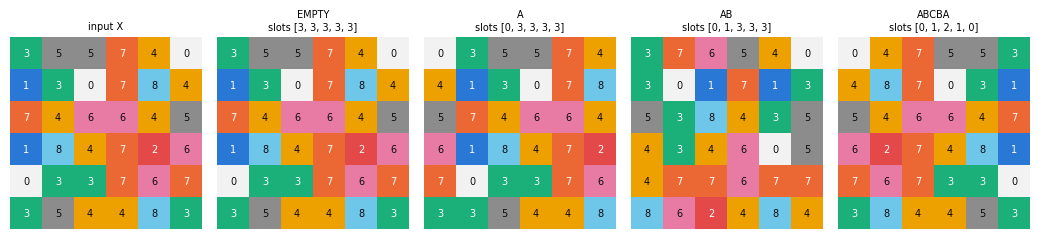

In [6]:
# --- Verify supports, length balance, slot placement and manifests -------------------------------------
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from decompositionality import mixed as M
from decompositionality.mixed_pipeline import prepare_mixed
from decompositionality.diagnosis.group import Catalog, check_catalog
from decompositionality.plotstyle import draw_grid
print("word counts:", M.check_supports())
sup = M.support(EXPERIMENT)
print({L: len(w) for L, w in sup.items()}, "| length-2 words:", sup[2])
ctx = prepare_mixed(cfg, repo_dir=str(REPO_DIR),
                    legacy_manifest=f"{RESULTS_ROOT}/distinct_pairs/manifests/manifest.json", log=print)
_s = M.MixedTrainStream(cfg.train.seed, EXPERIMENT, 256, ctx.manifests.heldout_bytes)
_b = [_s.batch(i) for i in range(20)]          # stateless: inspecting batches does not consume anything
_len = np.concatenate([b["length"] for b in _b]); _ops = np.concatenate([b["ops"] for b in _b])
print("length shares in the first 20 logical batches:", {int(L): round(float((_len == L).mean()), 4) for L in M.LENGTHS})
print("fraction of examples with a real operation in each slot:", ((_ops != 3).mean(0)).round(3).tolist())
assert not (_len == 1).any() and (_ops[_len == 0] == 3).all() and (_ops[_len == 5] != 3).all()
print("validation records per length:", pd.Series(ctx.val_set["length"]).value_counts().sort_index().to_dict())
print("test records:", len(ctx.test_set["x"]), "| words:", len(set(ctx.test_set["string"])))
print("catalog:", check_catalog(Catalog()))
x0 = ctx.test_set["x"][0].reshape(6, 6)
show = ["EMPTY", "A", "AB", "ABCBA"]
fig, axes = plt.subplots(1, len(show) + 1, figsize=(2.1 * (len(show) + 1), 2.6))
draw_grid(axes[0], x0, "input X")
for ax, s in zip(axes[1:], show):
    w = "" if s == "EMPTY" else s
    draw_grid(ax, M.apply_word_batch(x0[None], [w])[0], f"{s}\nslots {M.canonical_slots(w)}")
plt.tight_layout(); plt.show()


In [7]:
# --- Parameter counts with FIVE operation slots, and a time estimate ---------------------------------
from decompositionality.mixed_reports import resource_table
from decompositionality.training import profile_model
rt = resource_table(cfg.experiment_dir, cfg.experiment_dir / "tables")
display(rt[["model", "display_name", "n_slots", "unique_learned_params", "shared_core_params", "untied_equivalent_params",
            "block_applications_per_forward", "input_tokens", "decoded_output_steps"]])
if RUN_PROFILE and torch.cuda.is_available():
    prof = pd.DataFrame([profile_model(m, cfg.train, n_steps=2, n_slots=N_SLOTS) for m in cfg.models])
    display(prof)
    print(f"Estimated TRAINING time for {len(cfg.models)} models: {prof.est_train_minutes.sum():.0f} min, plus evaluation of "
          "364,000 records/model (AR free-running decoding is the slowest). Rerun to resume if the session ends.")


,model,display_name,n_slots,unique_learned_params,shared_core_params,untied_equivalent_params,block_applications_per_forward,input_tokens,decoded_output_steps
0,transformer_ar,Transformer AR,5,10702099,NaN,NaN,6,81 (teacher forcing); prompt 45,36
1,looped_transformer_ar,Looped Transformer AR (tied),5,1829779,1774464.0,10702099.0,6,81 (teacher forcing); prompt 45,36
2,transformer_encoder,Transformer encoder,5,10664074,NaN,NaN,6,41 (5 op slots + 36 cells),1
3,looped_transformer_encoder,Looped Transformer encoder (tied),5,1791754,1774464.0,10664074.0,6,41 (5 op slots + 36 cells),1
4,vit,ViT (2x2 patches),5,10685224,NaN,NaN,6,14 (5 op slots + 9 patches),1
5,looped_vit,Looped ViT (tied baseline),5,1812904,1774464.0,10685224.0,6,14 (5 op slots + 9 patches),1
6,trm,TRM-adapted,5,9939840,9912320.0,NaN,24,41 (5 op slots + 36 cells),1
7,rescnn_film,ResCNN-FiLM,5,10039594,NaN,NaN,6,"6x6 grid, 12 channels",1
8,unet_film,U-Net-FiLM,5,10334410,NaN,NaN,6,"6x6 grid, 12 channels (one 3x3 level)",1


,model_id,sec_per_step,microbatch,est_train_minutes,peak_gpu_gb
0,transformer_ar,0.030842,256,2.570182,1.962038
1,looped_transformer_ar,0.029520,256,2.460033,1.845063
2,transformer_encoder,0.018124,256,1.510292,1.083368
3,looped_transformer_encoder,0.016252,256,1.354337,0.964559
4,vit,0.017889,256,1.490752,0.480126
5,looped_vit,0.014463,256,1.205285,0.362110
6,trm,0.077204,256,6.433705,3.491194
7,rescnn_film,0.028337,256,2.361377,0.620994
8,unet_film,0.029419,256,2.451569,0.458229


Estimated TRAINING time for 9 models: 22 min, plus evaluation of 364,000 records/model (AR free-running decoding is the slowest). Rerun to resume if the session ends.


In [8]:
# --- Train all selected models sequentially (fresh initialization; resumable; checkpoints every 250 steps) ---
from decompositionality.training import train_model
from decompositionality.utils import free_memory
failures = {}
for mid in cfg.models:
    print(f"\n=== training {mid} ===")
    try:
        train_model(mid, cfg, ctx.manifests, ctx.val_set, ctx.subset_set, repo_dir=str(REPO_DIR))
    except Exception as exc:
        import traceback; traceback.print_exc(); failures[mid] = repr(exc)
    finally:
        free_memory()
if failures:
    raise RuntimeError(f"training failed for: {failures}")



=== training transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,702,099 params | device NVIDIA A100-SXM4-40GB | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.5701 (best) | subset(160) exact 0.169 cell 0.358
  step 500/5000 loss 1.1997 lr 2.98e-04 | 24.37 steps/s, 6237 ex/s | ETA 3.1 min
  [val @ 500] cell CE 1.2305 (best) | subset(160) exact 0.194 cell 0.396
  [val @ 750] cell CE 1.0559 (best) | subset(160) exact 0.200 cell 0.433
  step 950/5000 loss 0.7906 lr 2.86e-04 | 22.91 steps/s, 5865 ex/s | ETA 2.9 min
  [val @ 1000] cell CE 0.7660 (best) | subset(160) exact 0.200 cell 0.518
  [val @ 1250] cell CE 0.3804 (best) | subset(160) exact 0.281 cell 0.744
  step 1400/5000 loss 0.1266 lr 2.63e-04 | 22.75 steps/s, 5823 ex/s | ETA 2.6 min
  [val @ 1500] cell CE 0.1241 (best) | subset(160) exact 0.494 cell 0.931
  [val @ 1750] cell CE 0.0199 (best) | subset(160) exact 0.881 cell 0.994
  step 1875/5000 loss 0.0075 lr 2.29e-04 | 22.82 steps/s, 58

In [9]:
# --- Evaluate each SELECTED checkpoint on all 364 words x test grids (chunked, restartable) ---------------
from decompositionality.mixed_pipeline import evaluate_mixed_model
failures = {}
for mid in cfg.models:
    try:
        evaluate_mixed_model(mid, ctx, chunk_grids=EVAL_CHUNK_GRIDS)
    except Exception as exc:
        import traceback; traceback.print_exc(); failures[mid] = repr(exc)
    finally:
        free_memory()
if failures:
    raise RuntimeError(f"evaluation failed for: {failures}")


  [transformer_ar] test chunk 1/10 (36,400 records) | elapsed 0.4 min
  [transformer_ar] test chunk 2/10 (36,400 records) | elapsed 0.9 min
  [transformer_ar] test chunk 3/10 (36,400 records) | elapsed 1.3 min
  [transformer_ar] test chunk 4/10 (36,400 records) | elapsed 1.7 min
  [transformer_ar] test chunk 5/10 (36,400 records) | elapsed 2.2 min
  [transformer_ar] test chunk 6/10 (36,400 records) | elapsed 2.6 min
  [transformer_ar] test chunk 7/10 (36,400 records) | elapsed 3.1 min
  [transformer_ar] test chunk 8/10 (36,400 records) | elapsed 3.5 min
  [transformer_ar] test chunk 9/10 (36,400 records) | elapsed 3.9 min
  [transformer_ar] test chunk 10/10 (36,400 records) | elapsed 4.4 min
[transformer_ar] selected step 4750 | singles A/B/C exact 988/869/0 of 1000 each | EMPTY 1.0000 | seen pairs 1.0000 | eval 4.4 min
  [looped_transformer_ar] test chunk 1/10 (36,400 records) | elapsed 0.4 min
  [looped_transformer_ar] test chunk 2/10 (36,400 records) | elapsed 0.9 min
  [looped_tran

# mixed_02345_all_pairs: singles (never trained) vs seen support

Integer exact successes / records on the held-out test grids. Lengths 3-5 are SEEN strings on NEW grids (not unseen-combination generalization). Overall micro = record-weighted over 364 words (dominated by length 5); length-macro = lengths 0..5 equally weighted. One seed; no error bars.

seen_support_fit = INADEQUATE if any seen category (pairs, len3, len4, len5) is below 0.9: single-operation failure of such a model is NOT a clean decomposition failure.

| model | selected_step | A | B | C | singles_macro_exact | EMPTY | seen_pairs | unseen_pairs | len3 | len4 | len5 | overall_micro | overall_length_macro | seen_support_fit |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Transformer AR | 4750 | 988/1000 | 869/1000 | 0/1000 | 0.6190 | 1000/1000 | 9000/9000 | N/A | 26999/27000 | 80995/81000 | 242934/243000 | 0.9967 | 0.9364 | adequate |
| Looped Transformer AR (tied) | 5000 | 879/1000 | 994/1000 | 183/10

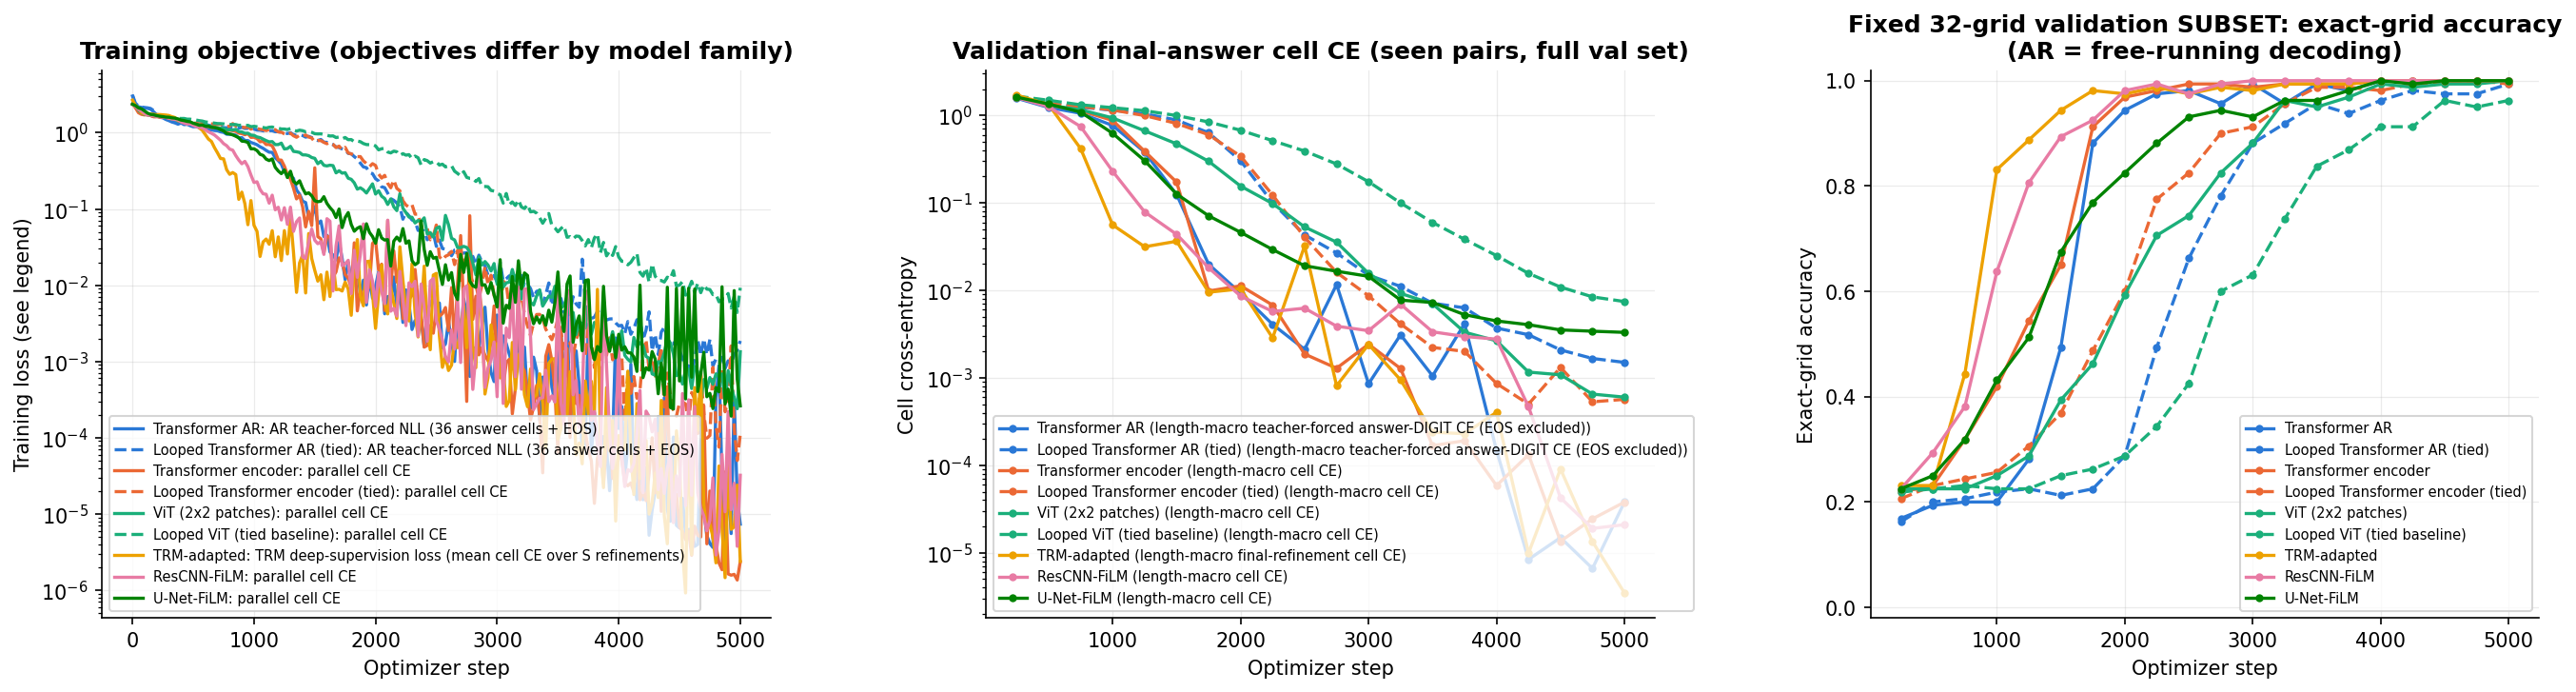

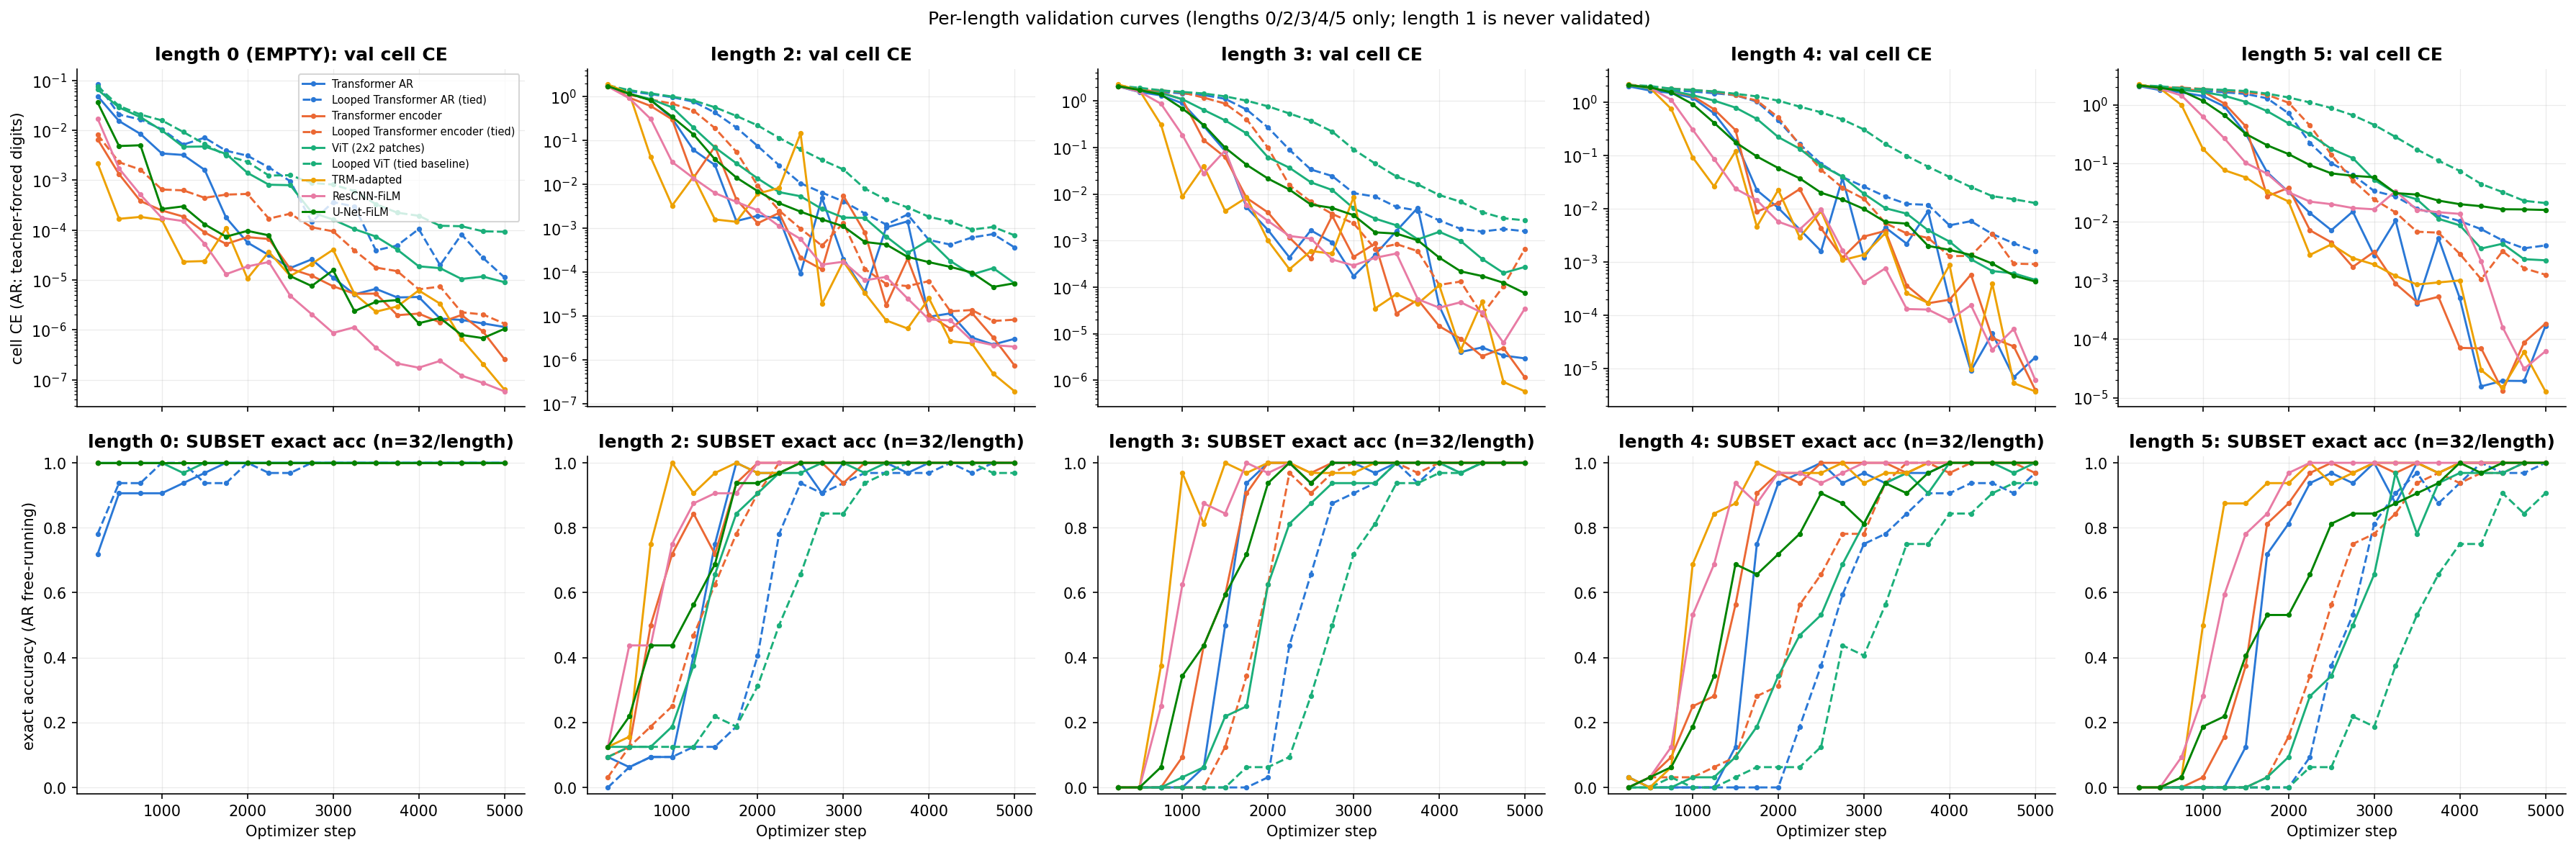

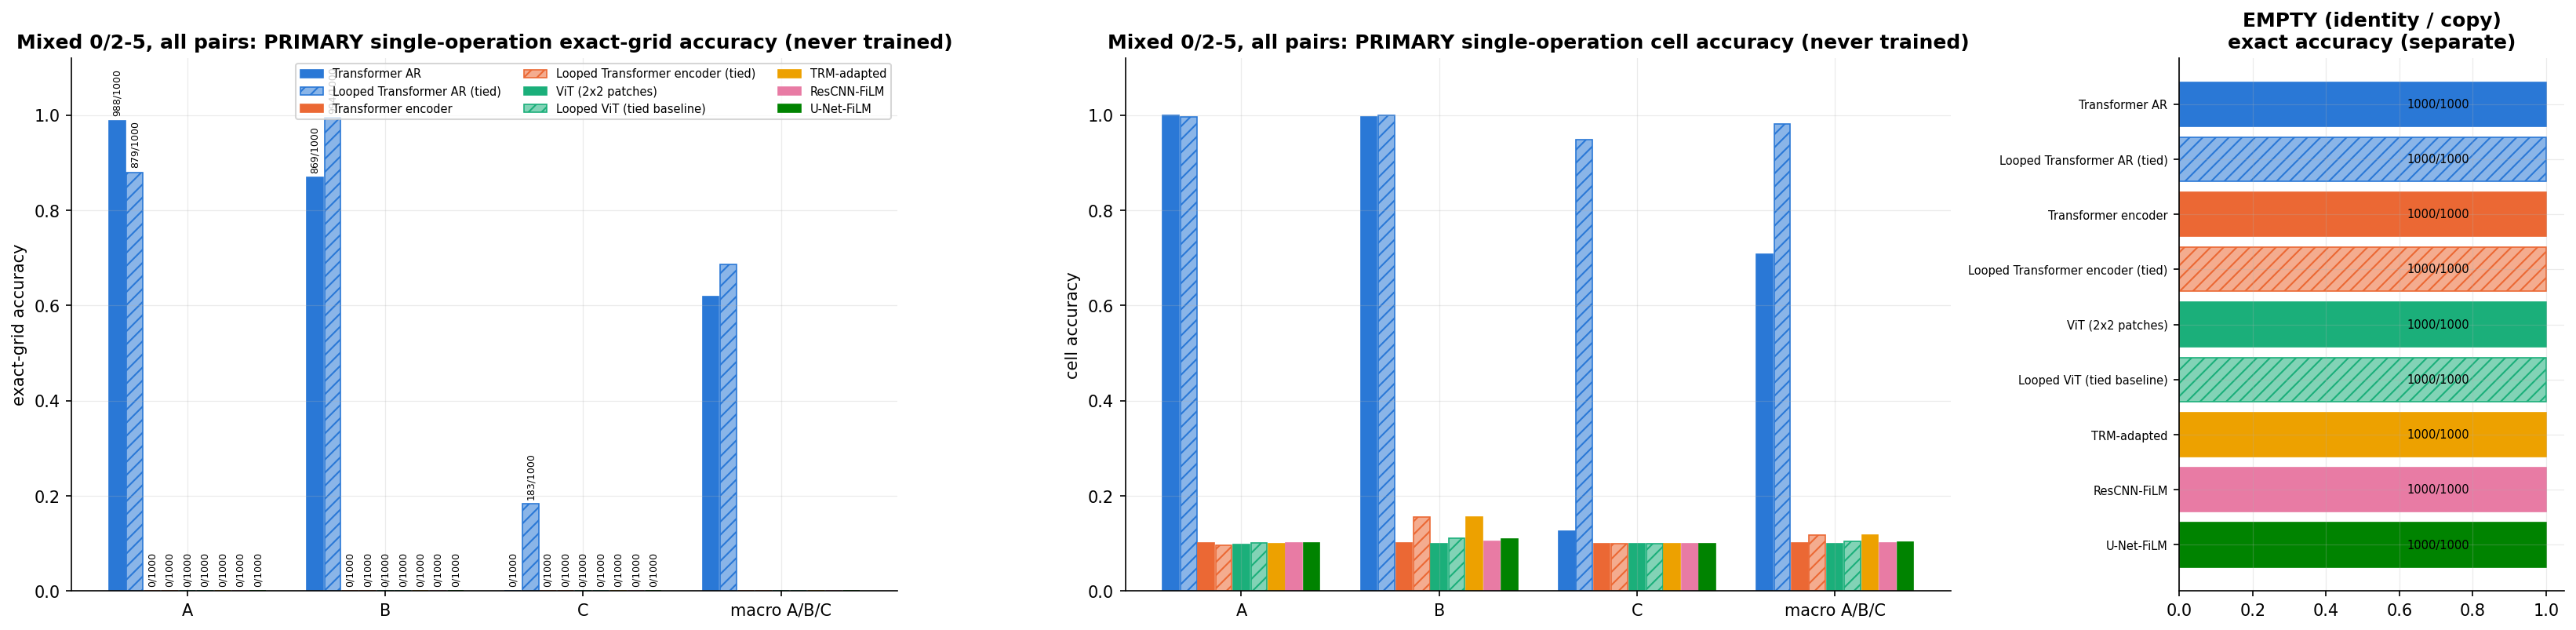

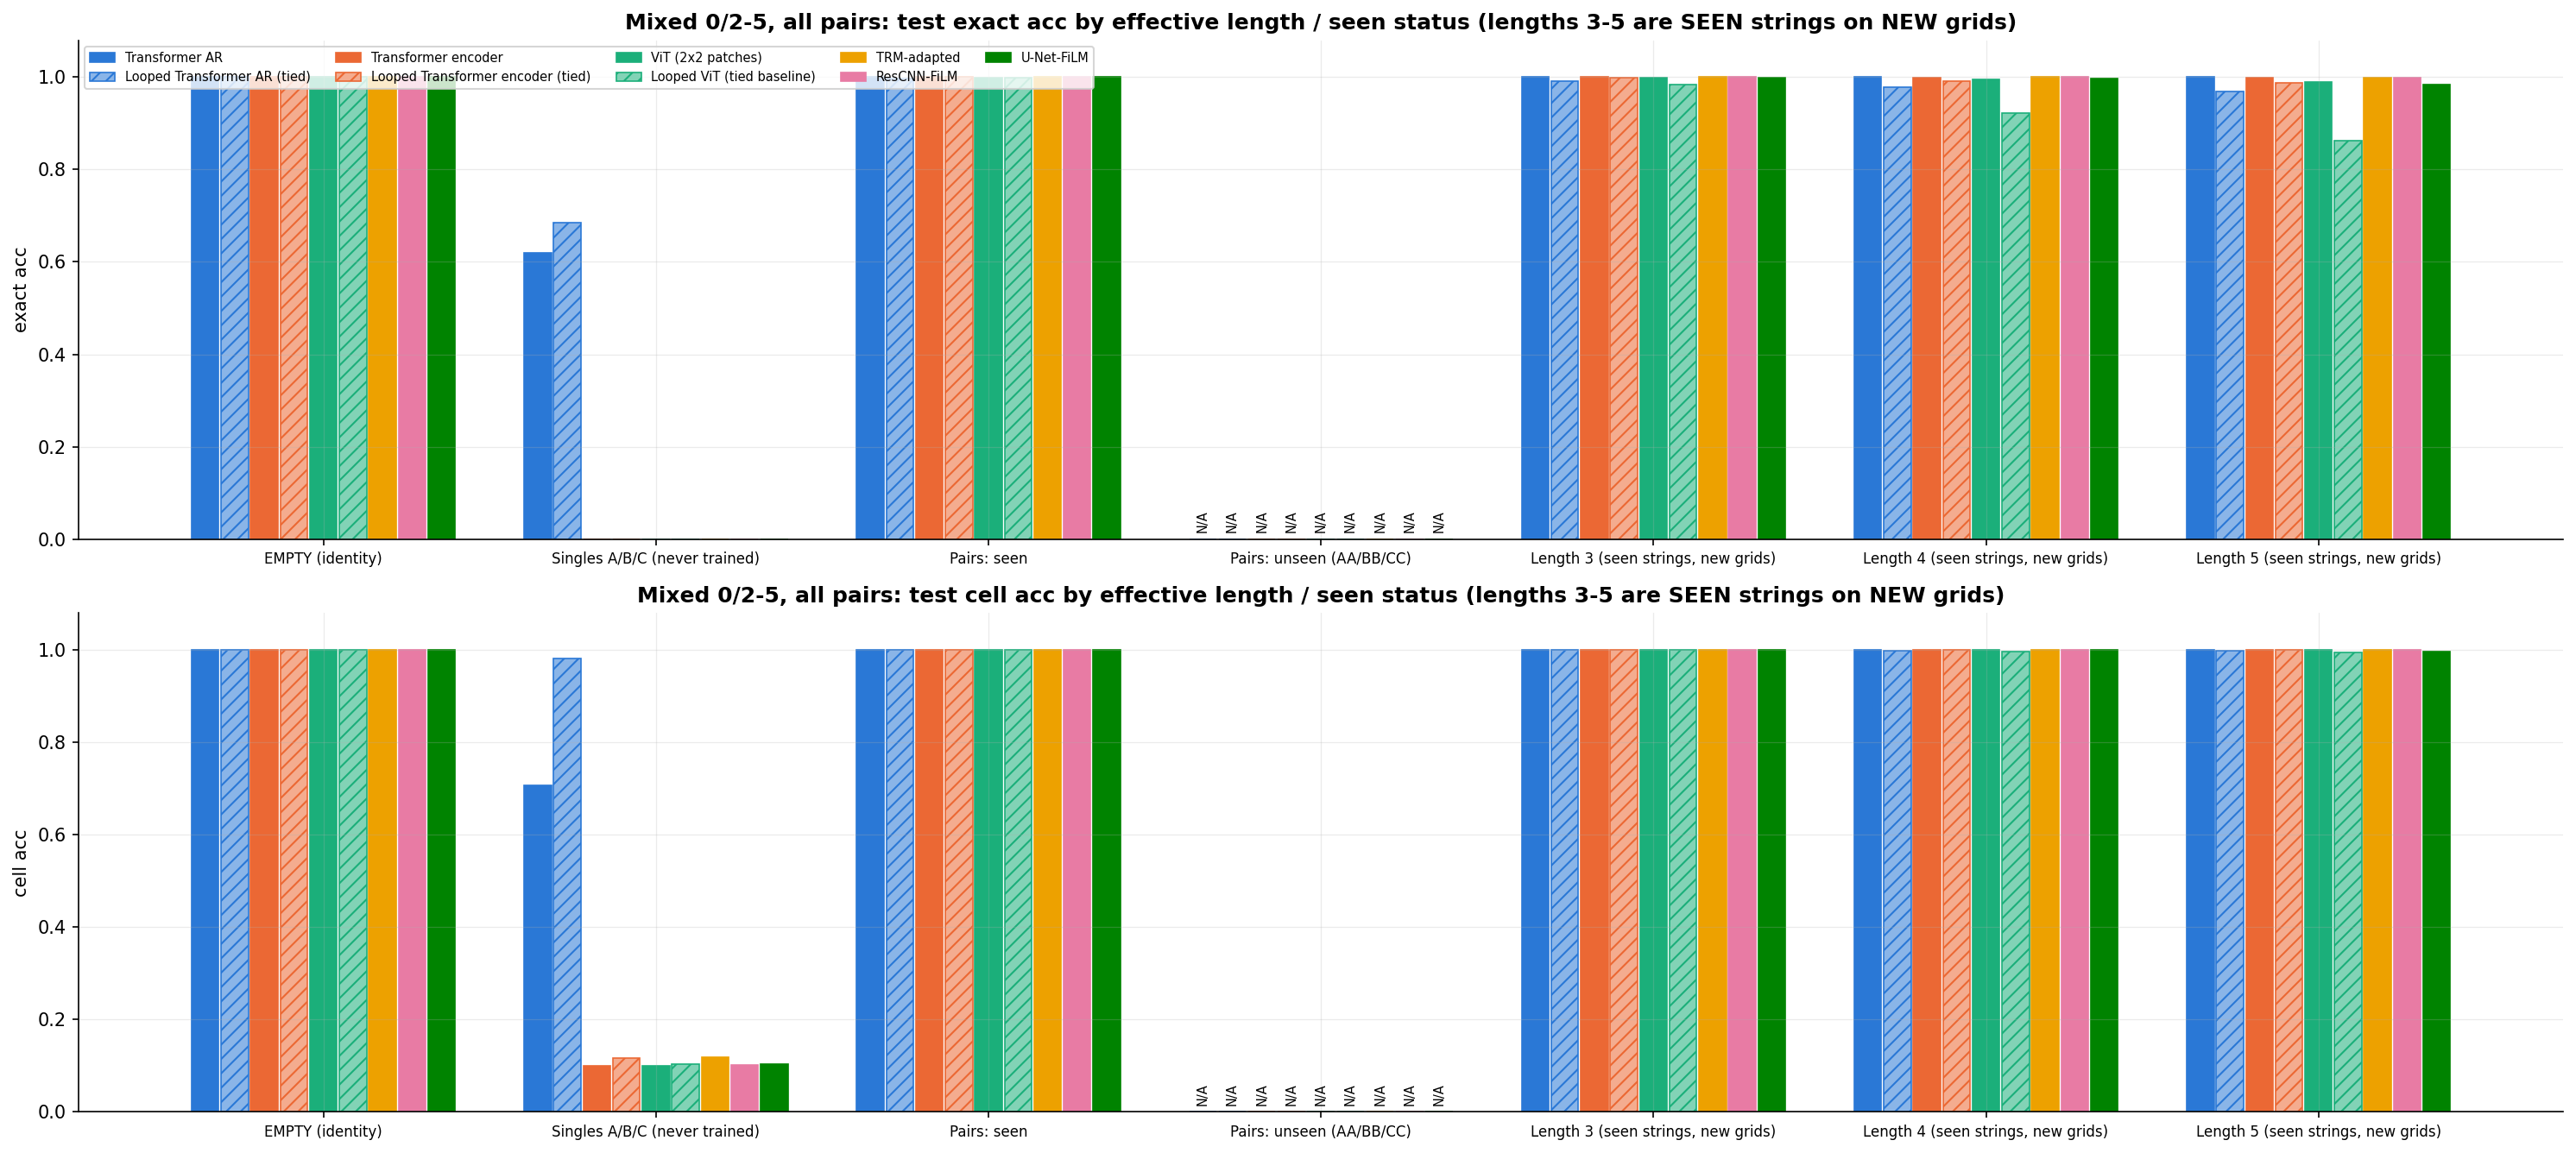

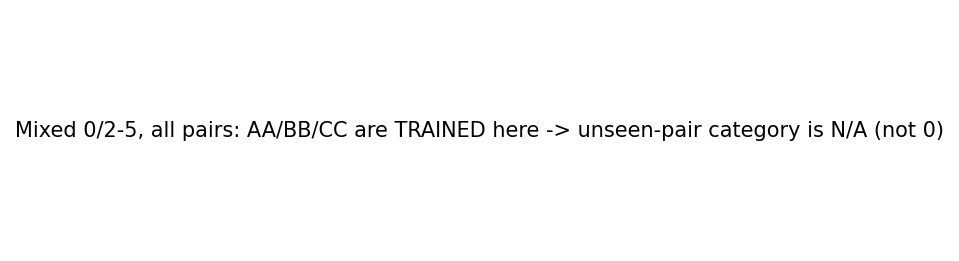

In [10]:
# --- Training/evaluation figures and tables (saved before the diagnostics run) ------------------------------
from decompositionality.mixed_reports import build_mixed_reports
rep = build_mixed_reports(cfg.experiment_dir, EXPERIMENT)
FIGS = cfg.experiment_dir / "figures"
for name in ["a_training_curves", "a2_validation_by_length", "b1_singles_primary_and_empty",
             "b2_accuracy_by_length_and_seen_status", "b3_unseen_pairs_AA_BB_CC"]:
    p = FIGS / f"{name}.png"
    if p.exists():
        display(Image(filename=str(p)))


## Diagnostics
Behavioural, post-hoc and non-causal. Hypothesis tables report eligible records, unique matched records, conditional and unconditional rates. DIAG measures use a disjoint half of the base grids.

In [11]:
# --- Post-hoc diagnostics on the SAVED predictions of this experiment (+ sibling, read-only, if present) ---
from decompositionality.diagnosis.runner import DiagnosticsConfig, run_diagnostics
from decompositionality.mixed import MIXED_EXPERIMENTS
dirs = {EXPERIMENT: str(cfg.experiment_dir)}
sibling = [e for e in MIXED_EXPERIMENTS if e != EXPERIMENT][0]
sib_dir = cfg.experiment_dir.parent / sibling
if INCLUDE_SIBLING_IN_DIAGNOSTICS and (sib_dir / "eval").exists():
    dirs[sibling] = str(sib_dir)
    print("including sibling experiment (read-only) for paired comparisons:", sib_dir)
else:
    print("sibling experiment not available -> paired comparison will be N/A (this notebook does not need it)")
dcfg = DiagnosticsConfig(experiment_dirs=dirs, output_dir=str(cfg.experiment_dir / "diagnostics"), models=cfg.models,
                         chunk_size=ANALYSIS_CHUNK_SIZE, use_cache=USE_ANALYSIS_CACHE, spec="mixed",
                         example_strings=["EMPTY", "A", "B", "C", "AA", "BB", "CC", "ABC"])
R = run_diagnostics(dcfg)
DFIG = pathlib.Path(R["output_dir"]) / "figures"
def show(prefix):
    for p in sorted(DFIG.glob(prefix + "*.png")):
        display(Image(filename=str(p)))


including sibling experiment (read-only) for paired comparisons: /content/drive/MyDrive/decompositionality_results/mixed_length_02345/mixed_02345_distinct_pairs
Artifact inventory:
                experiment                      model                           status
     mixed_02345_all_pairs             transformer_ar predictions available (original)
     mixed_02345_all_pairs      looped_transformer_ar predictions available (original)
     mixed_02345_all_pairs        transformer_encoder predictions available (original)
     mixed_02345_all_pairs looped_transformer_encoder predictions available (original)
     mixed_02345_all_pairs                        vit predictions available (original)
     mixed_02345_all_pairs                 looped_vit predictions available (original)
     mixed_02345_all_pairs                        trm predictions available (original)
     mixed_02345_all_pairs                rescnn_film predictions available (original)
     mixed_02345_all_pairs          

,experiment,model,n_records,n_strings,empty_word_records,missing_strings,duplicate_keys,invalid_records,target_oracle_mismatches,input_manifest_mismatches,decoding,attribution_blocked
0,mixed_02345_all_pairs,transformer_ar,364000,364,1000,,0,0,0,0,AR free-running greedy decoding (eval_summary ...,False
1,mixed_02345_all_pairs,looped_transformer_ar,364000,364,1000,,0,0,0,0,AR free-running greedy decoding (eval_summary ...,False
2,mixed_02345_all_pairs,transformer_encoder,364000,364,1000,,0,0,0,0,parallel prediction (parallel argmax); not aut...,False
3,mixed_02345_all_pairs,looped_transformer_encoder,364000,364,1000,,0,0,0,0,parallel prediction (parallel argmax); not aut...,False
4,mixed_02345_all_pairs,vit,364000,364,1000,,0,0,0,0,parallel prediction (parallel argmax); not aut...,False
5,mixed_02345_all_pairs,looped_vit,364000,364,1000,,0,0,0,0,parallel prediction (parallel argmax); not aut...,False
6,mixed_02345_all_pairs,trm,364000,364,1000,,0,0,0,0,parallel prediction (parallel argmax of final ...,False
7,mixed_02345_all_pairs,rescnn_film,364000,364,1000,,0,0,0,0,parallel prediction (parallel argmax); not aut...,False
8,mixed_02345_all_pairs,unet_film,364000,364,1000,,0,0,0,0,parallel prediction (parallel argmax); not aut...,False
9,mixed_02345_distinct_pairs,transformer_ar,364000,364,1000,,0,0,0,0,AR free-running greedy decoding (eval_summary ...,False


,experiment,model,string,exact_correct,n,exact_acc,cell_acc,any_exact_group_match_count,dominant_wrong_unique_word,dominant_wrong_unique_share,dominant_is_original_pair,stable_rule_selected_word,stable_rule_diag_exact_fidelity,argmax_map_diag_cell_fidelity
1,mixed_02345_all_pairs,transformer_ar,A,988,1000,0.988,0.999667,988,,0.000,False,A,0.982,0.999500
2,mixed_02345_all_pairs,transformer_ar,B,869,1000,0.869,0.996222,869,,0.000,False,B,0.878,0.996444
3,mixed_02345_all_pairs,transformer_ar,C,0,1000,0.000,0.126222,352,I,0.352,True,I,0.356,0.980000
365,mixed_02345_all_pairs,looped_transformer_ar,A,879,1000,0.879,0.995389,879,,0.000,False,A,0.872,0.995389
366,mixed_02345_all_pairs,looped_transformer_ar,B,994,1000,0.994,0.999611,994,,0.000,False,B,0.996,0.999778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6190,mixed_02345_distinct_pairs,unet_film,B,0,1000,0.000,0.098389,112,BC,0.112,True,BC,0.116,0.935722
6191,mixed_02345_distinct_pairs,unet_film,C,0,1000,0.000,0.099139,983,I,0.983,False,I,0.976,0.999333
6192,mixed_02345_distinct_pairs,unet_film,AA,0,1000,0.000,0.435722,0,,0.000,False,AAAA,0.000,0.725278
6196,mixed_02345_distinct_pairs,unet_film,BB,0,1000,0.000,0.102056,171,BBA,0.171,False,BBA,0.164,0.901889


,experiment,model,population,hypothesis_type,population_records,population_wrong_records,population_any_legal_match_records,applicable_records,eligible_records,matched_unique_records,conditional_rate (matched/eligible),unconditional_coverage (matched/population),truth_equivalent_strings
0,mixed_02345_all_pairs,transformer_ar,OOD: singles + unseen pairs,identity,3000,1143,2209,3000,3000,352,0.117333,0.117333,0
1,mixed_02345_all_pairs,transformer_ar,OOD: singles + unseen pairs,first_op,3000,1143,2209,3000,0,0,NaN,0.000000,3
2,mixed_02345_all_pairs,transformer_ar,OOD: singles + unseen pairs,last_op,3000,1143,2209,3000,0,0,NaN,0.000000,3
3,mixed_02345_all_pairs,transformer_ar,OOD: singles + unseen pairs,first_and_last,3000,1143,2209,3000,3000,352,0.117333,0.117333,0
4,mixed_02345_all_pairs,transformer_ar,OOD: singles + unseen pairs,first_two,3000,1143,2209,0,0,0,NaN,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1435,mixed_02345_distinct_pairs,unet_film,OOD: singles + unseen pairs,reverse,6000,5994,1272,3000,0,0,NaN,0.000000,3
1436,mixed_02345_distinct_pairs,unet_film,OOD: singles + unseen pairs,collapse_adjacent,6000,5994,1272,3000,3000,0,0.000000,0.000000,0
1437,mixed_02345_distinct_pairs,unet_film,OOD: singles + unseen pairs,dedupe_global,6000,5994,1272,3000,3000,0,0.000000,0.000000,0
1438,mixed_02345_distinct_pairs,unet_film,OOD: singles + unseen pairs,duplicate_single,6000,5994,1272,3000,3000,983,0.327667,0.163833,0


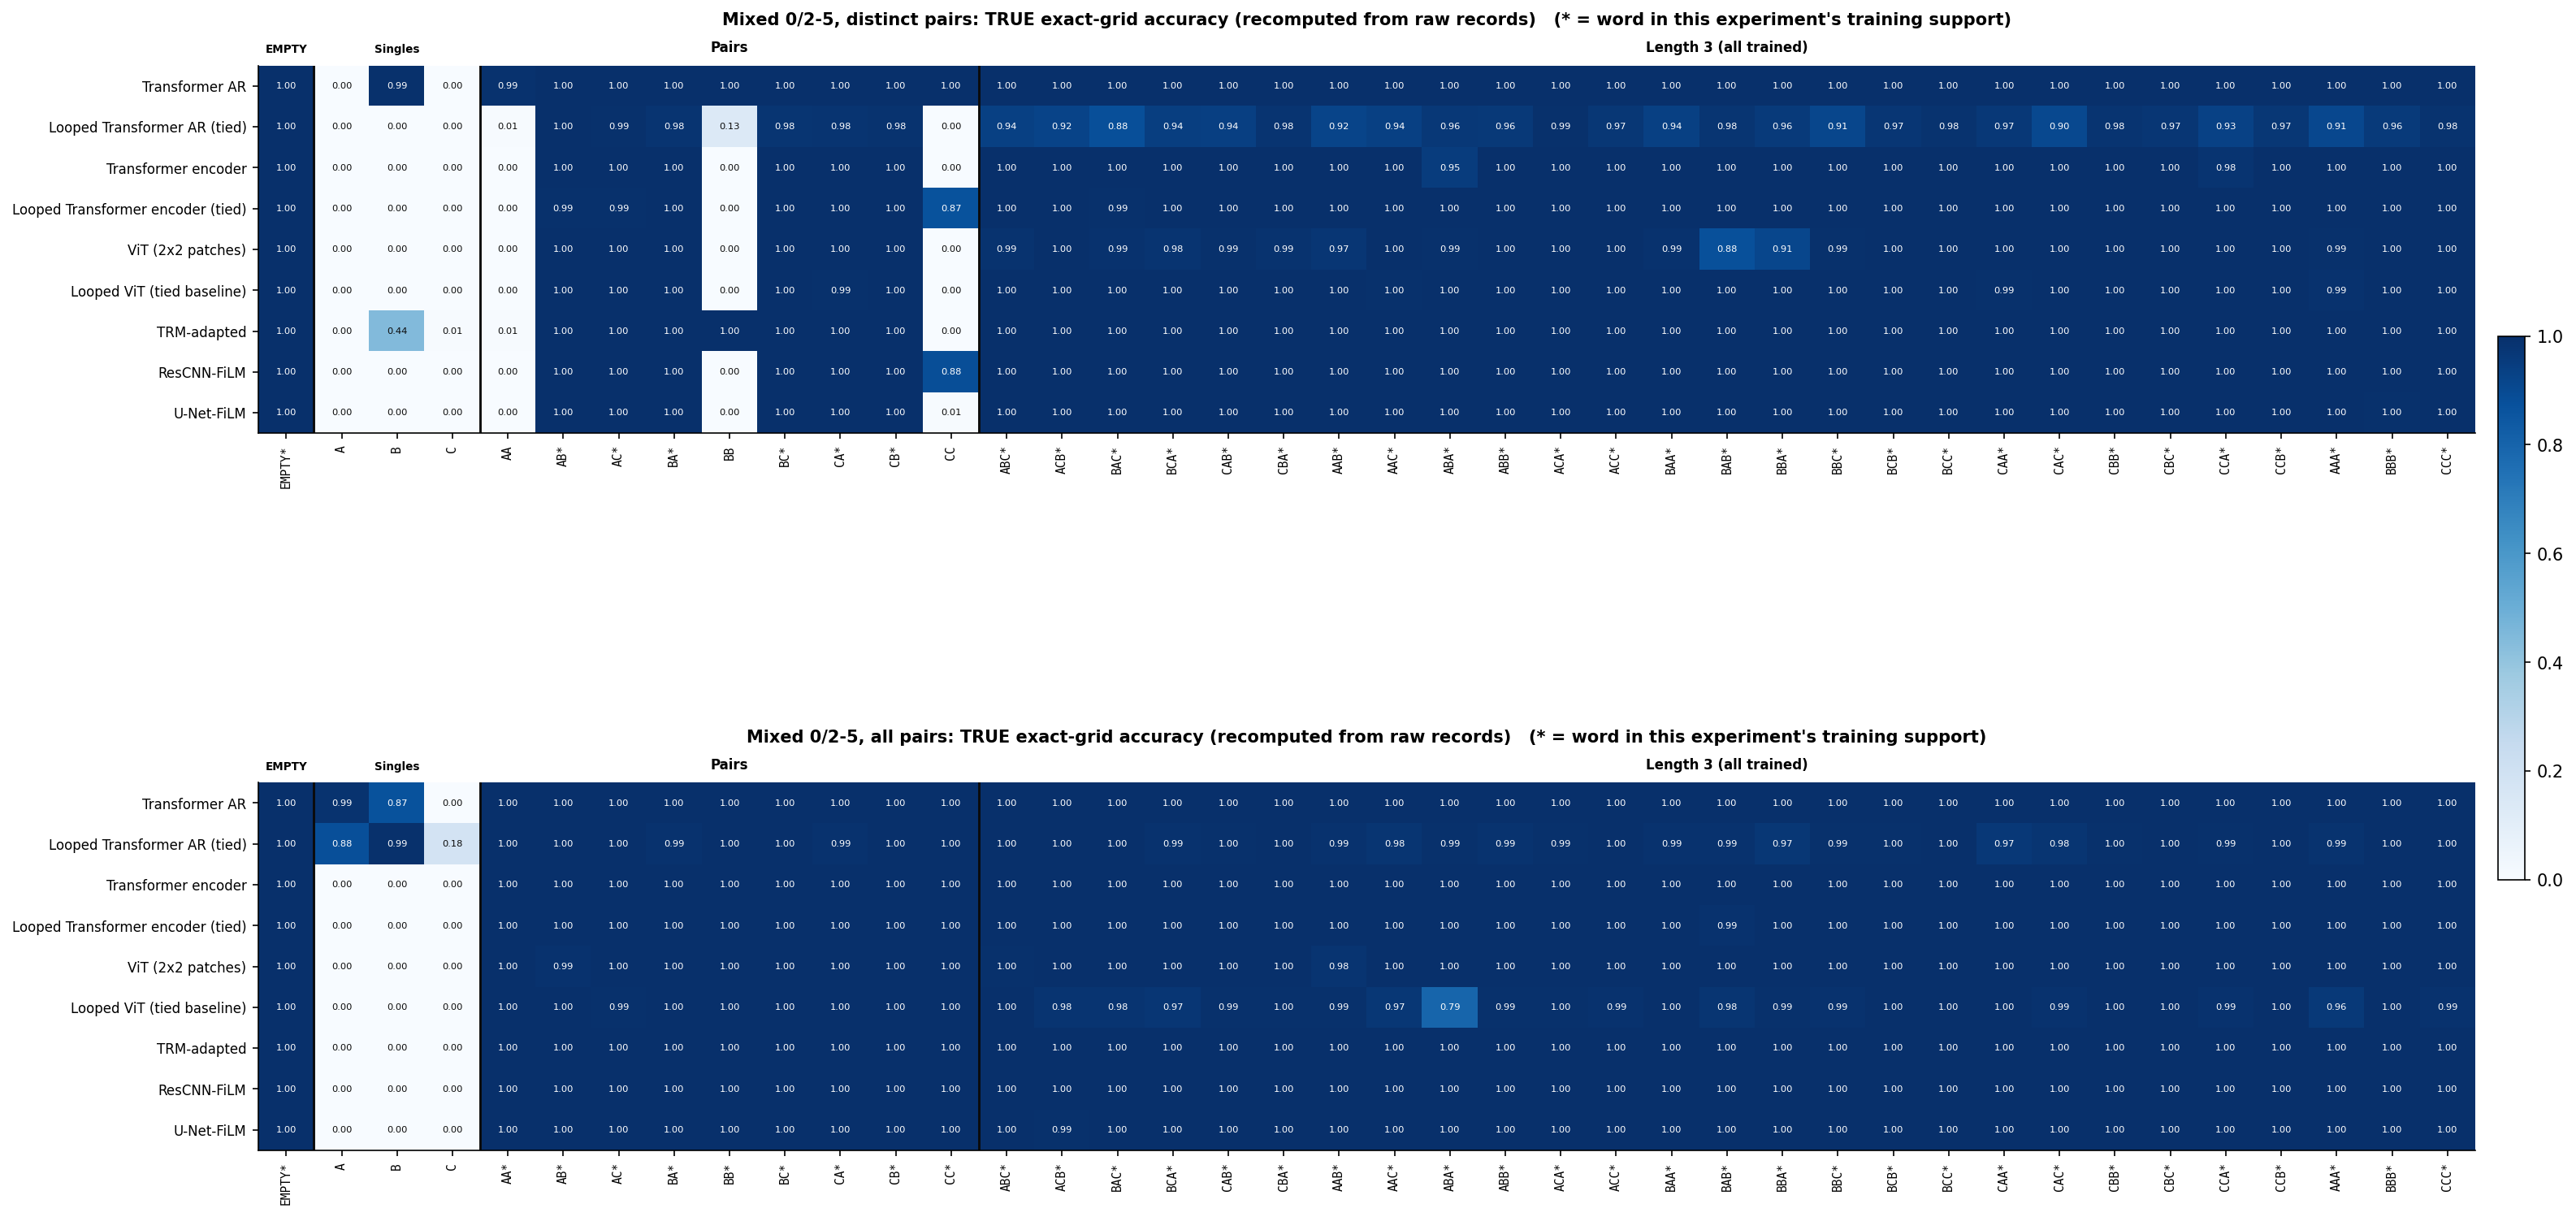

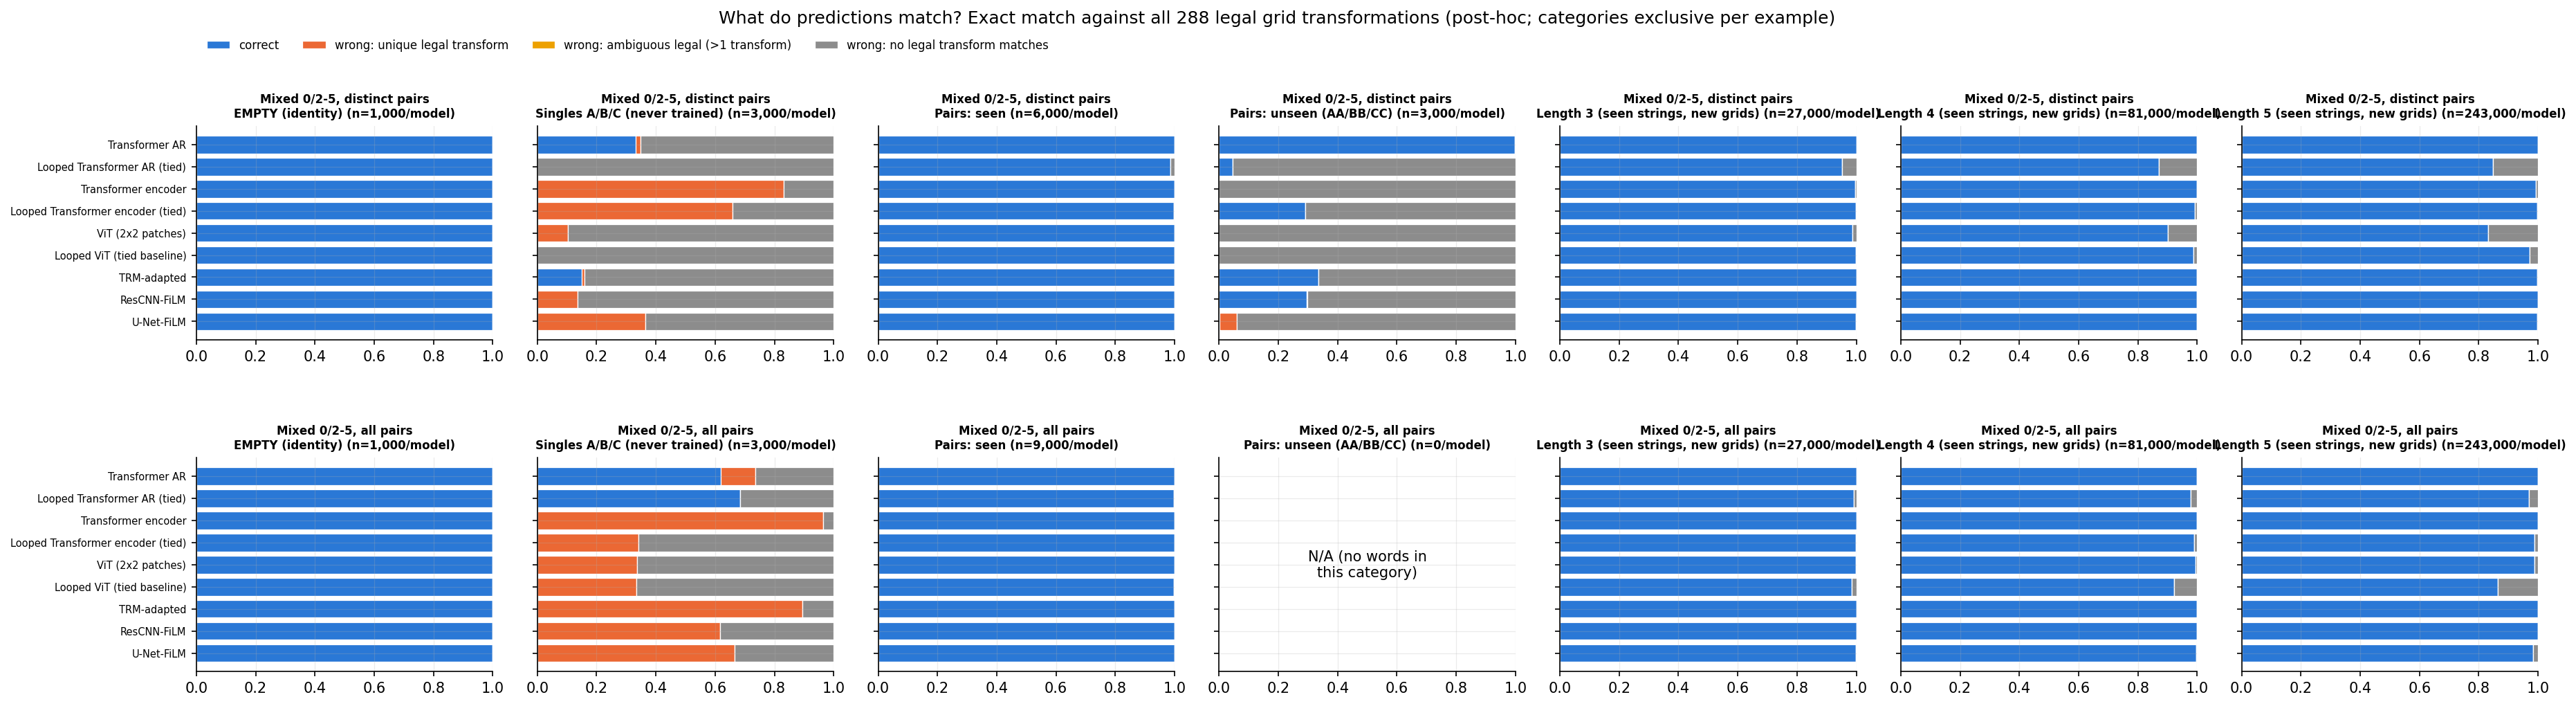

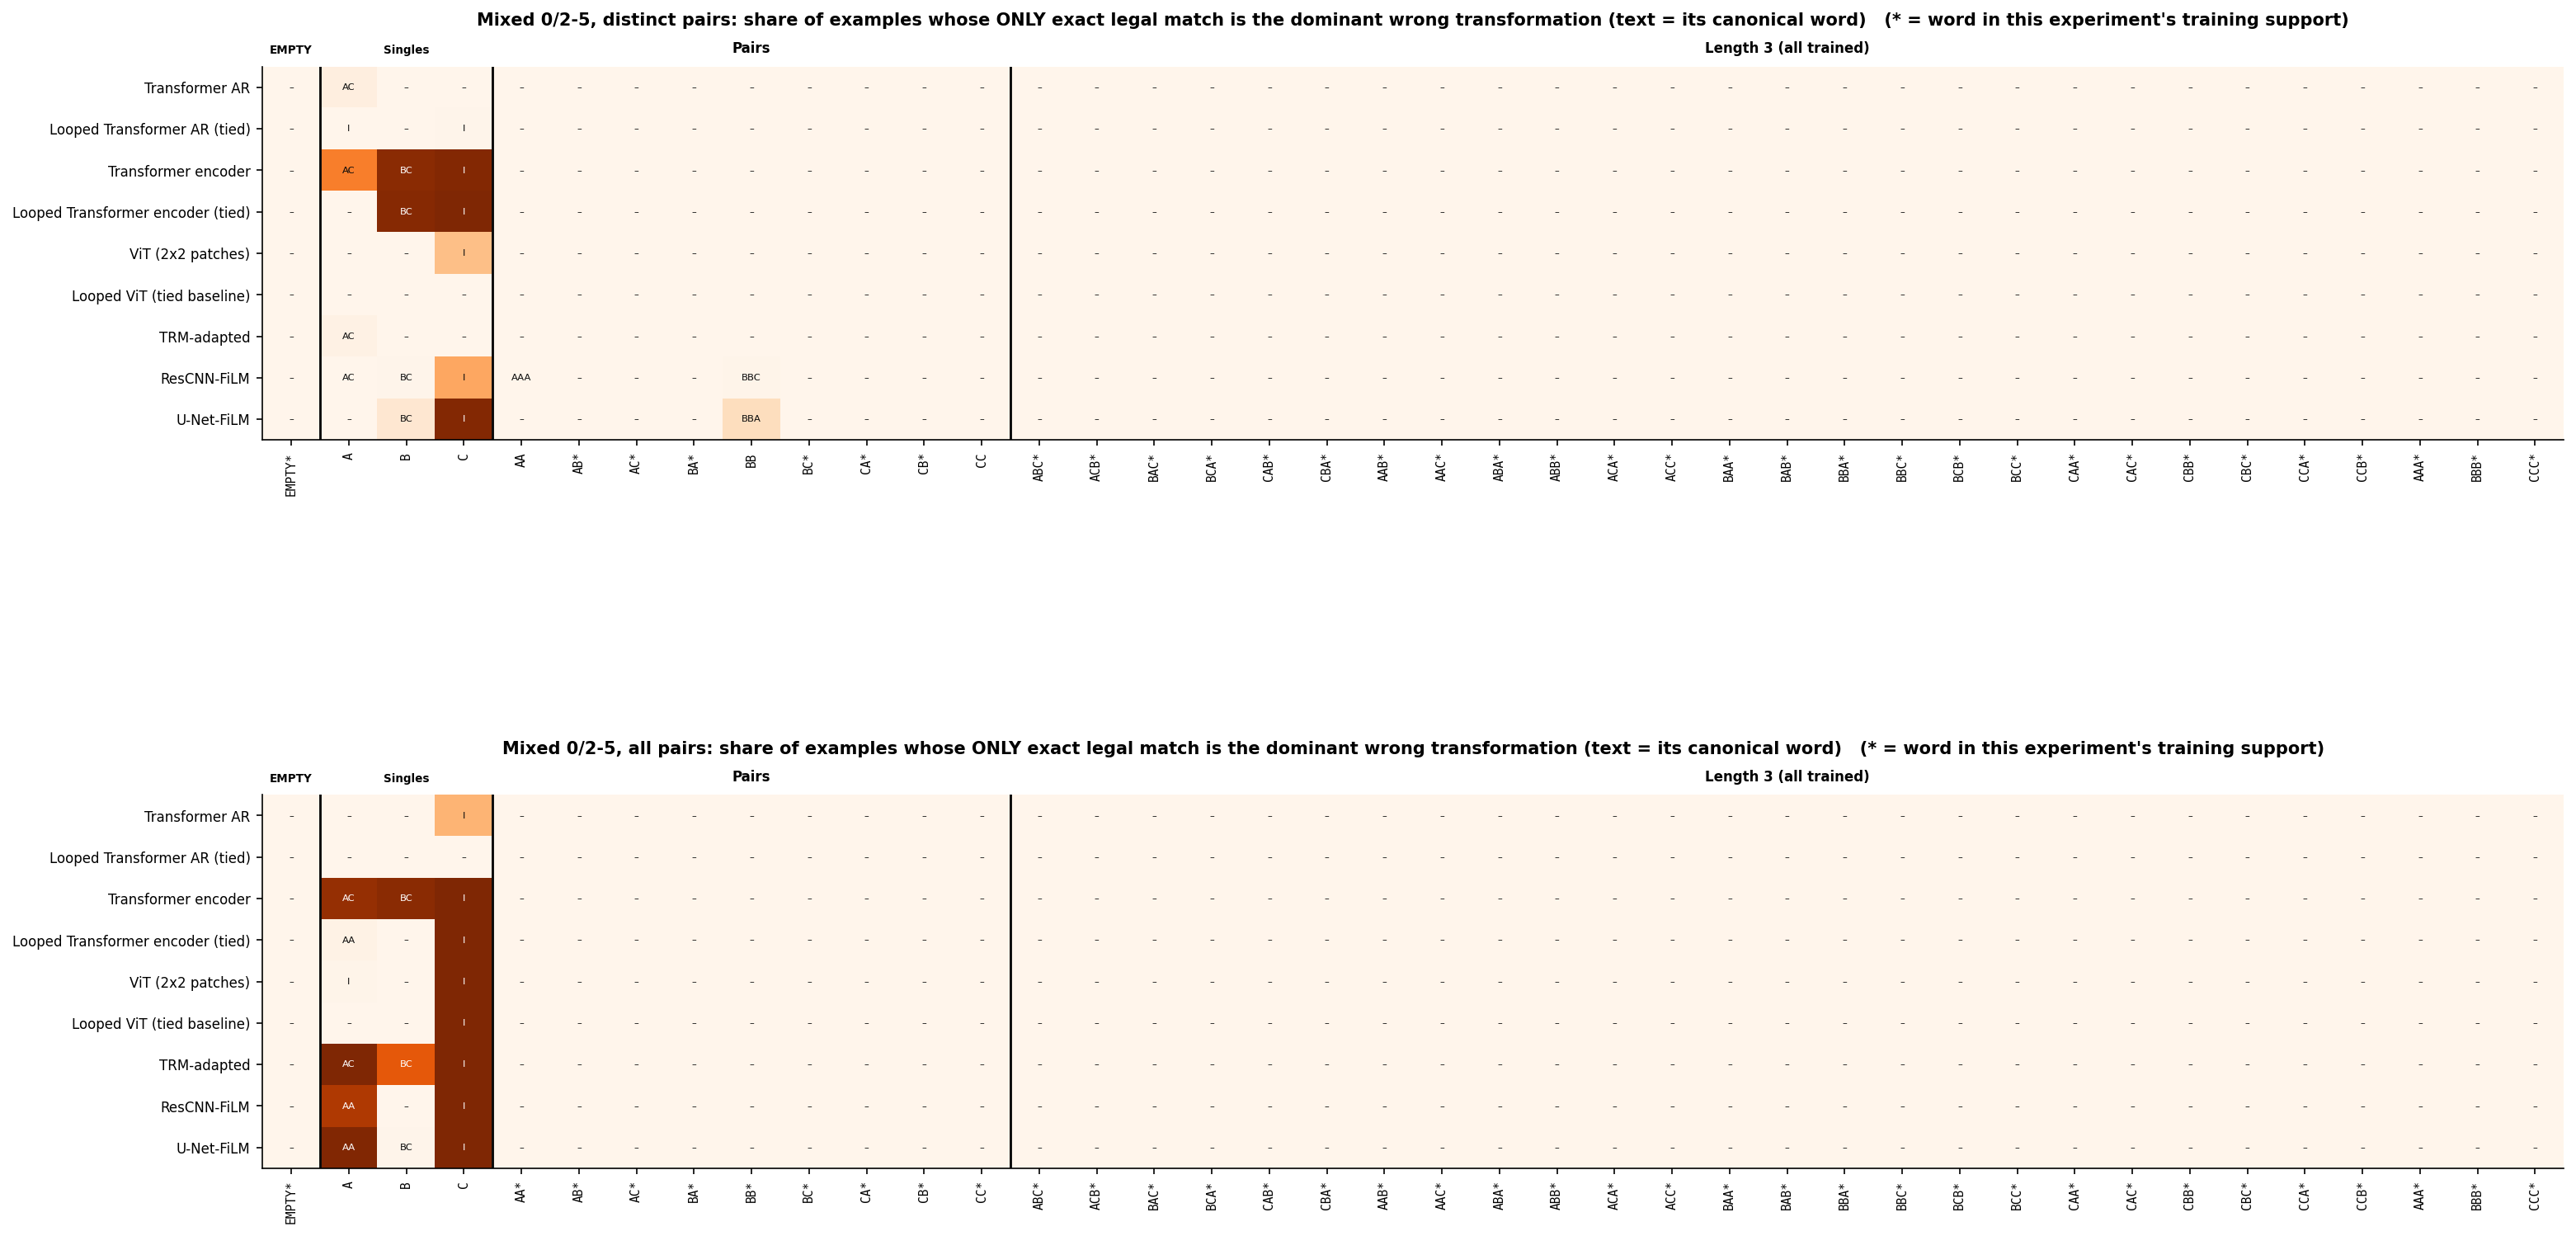

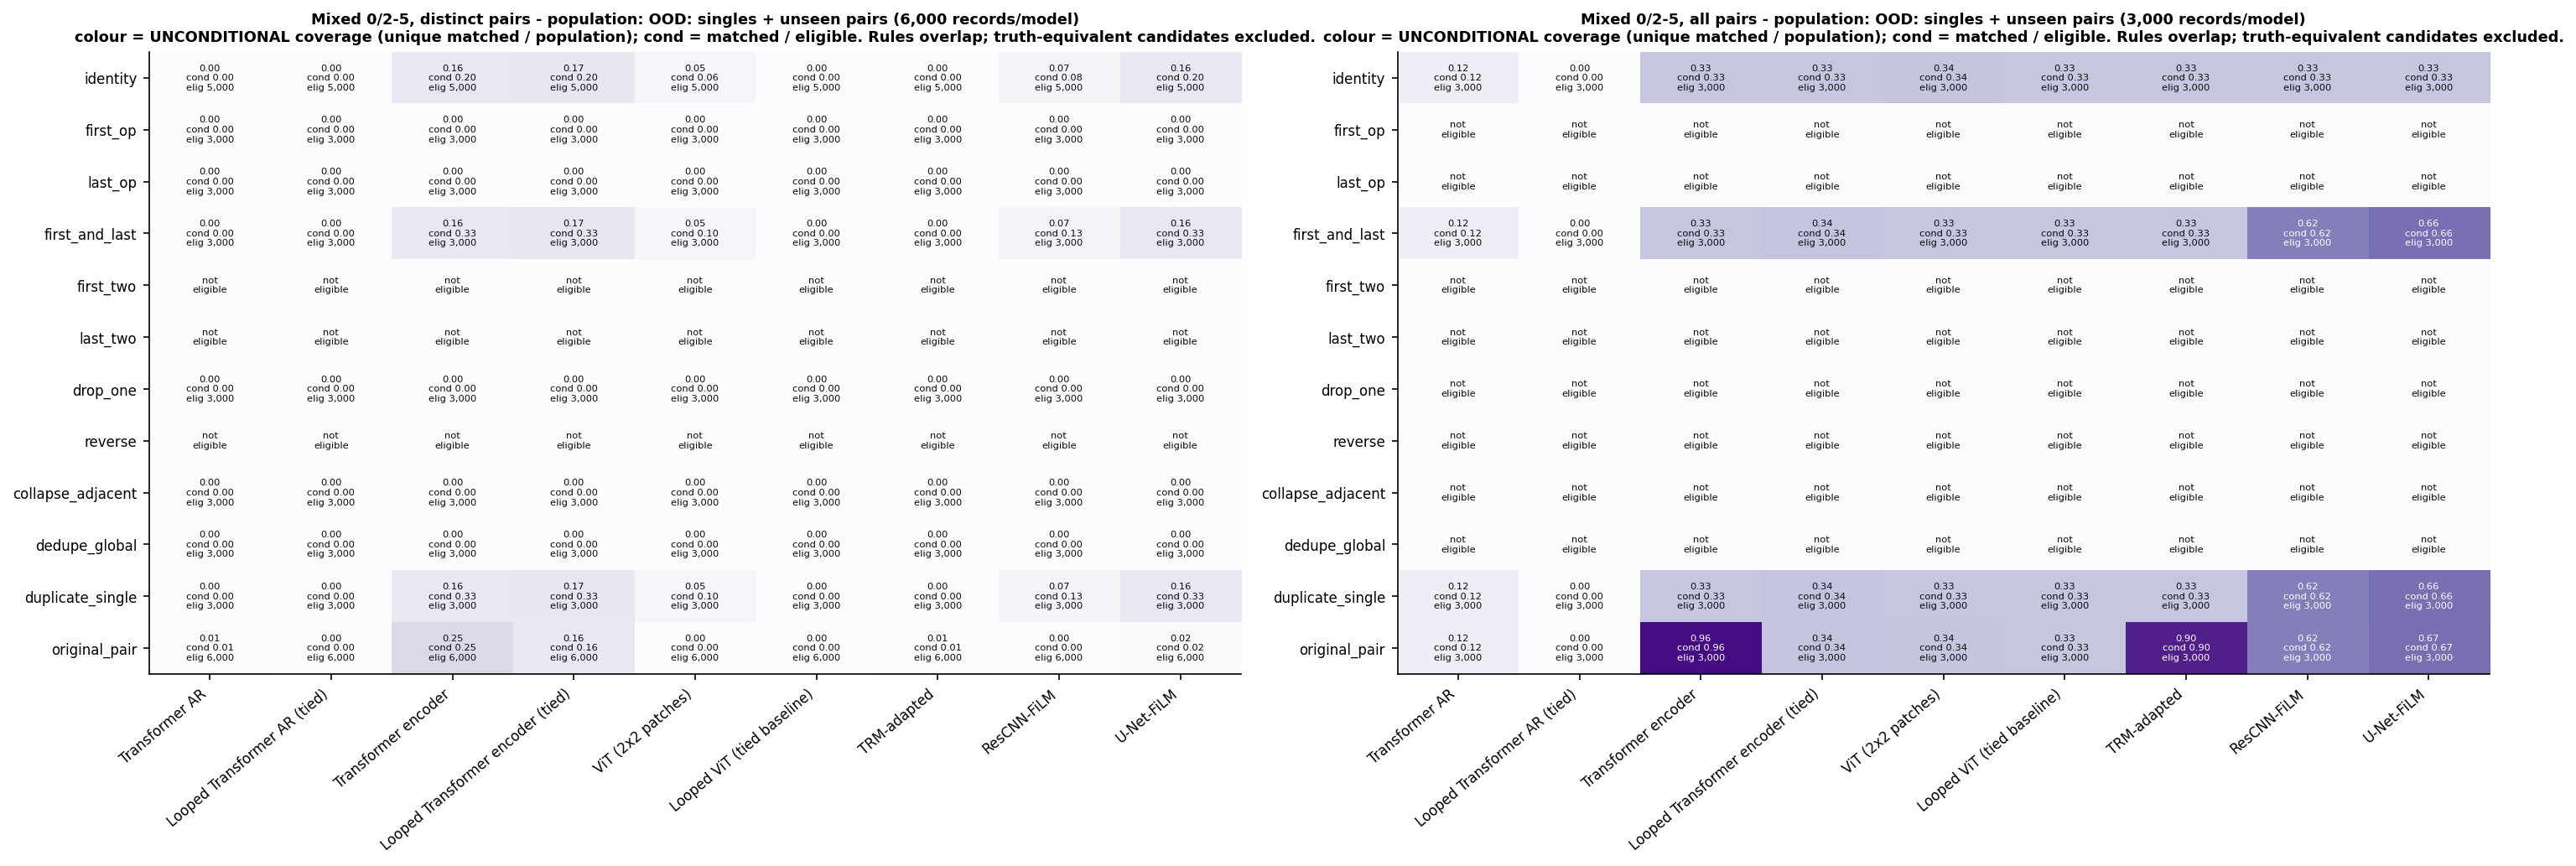

In [12]:
# Audit, then the out-of-support words (singles and unseen pairs) first
display(R["audit"][["experiment", "model", "n_records", "n_strings", "empty_word_records", "missing_strings",
                    "duplicate_keys", "invalid_records", "target_oracle_mismatches", "input_manifest_mismatches",
                    "decoding", "attribution_blocked"]])
ood = R["per_string"][R["per_string"].group.isin(["singles", "pairs_unseen"])]
display(ood[["experiment", "model", "string", "exact_correct", "n", "exact_acc", "cell_acc", "any_exact_group_match_count",
             "dominant_wrong_unique_word", "dominant_wrong_unique_share", "dominant_is_original_pair",
             "stable_rule_selected_word", "stable_rule_diag_exact_fidelity", "argmax_map_diag_cell_fidelity"]])
hs = R["hypothesis_summary"]
display(hs[hs.population == "OOD: singles + unseen pairs"])
show("01_true"); show("03_explanation"); show("04_dominant"); show("05_hypothesis")


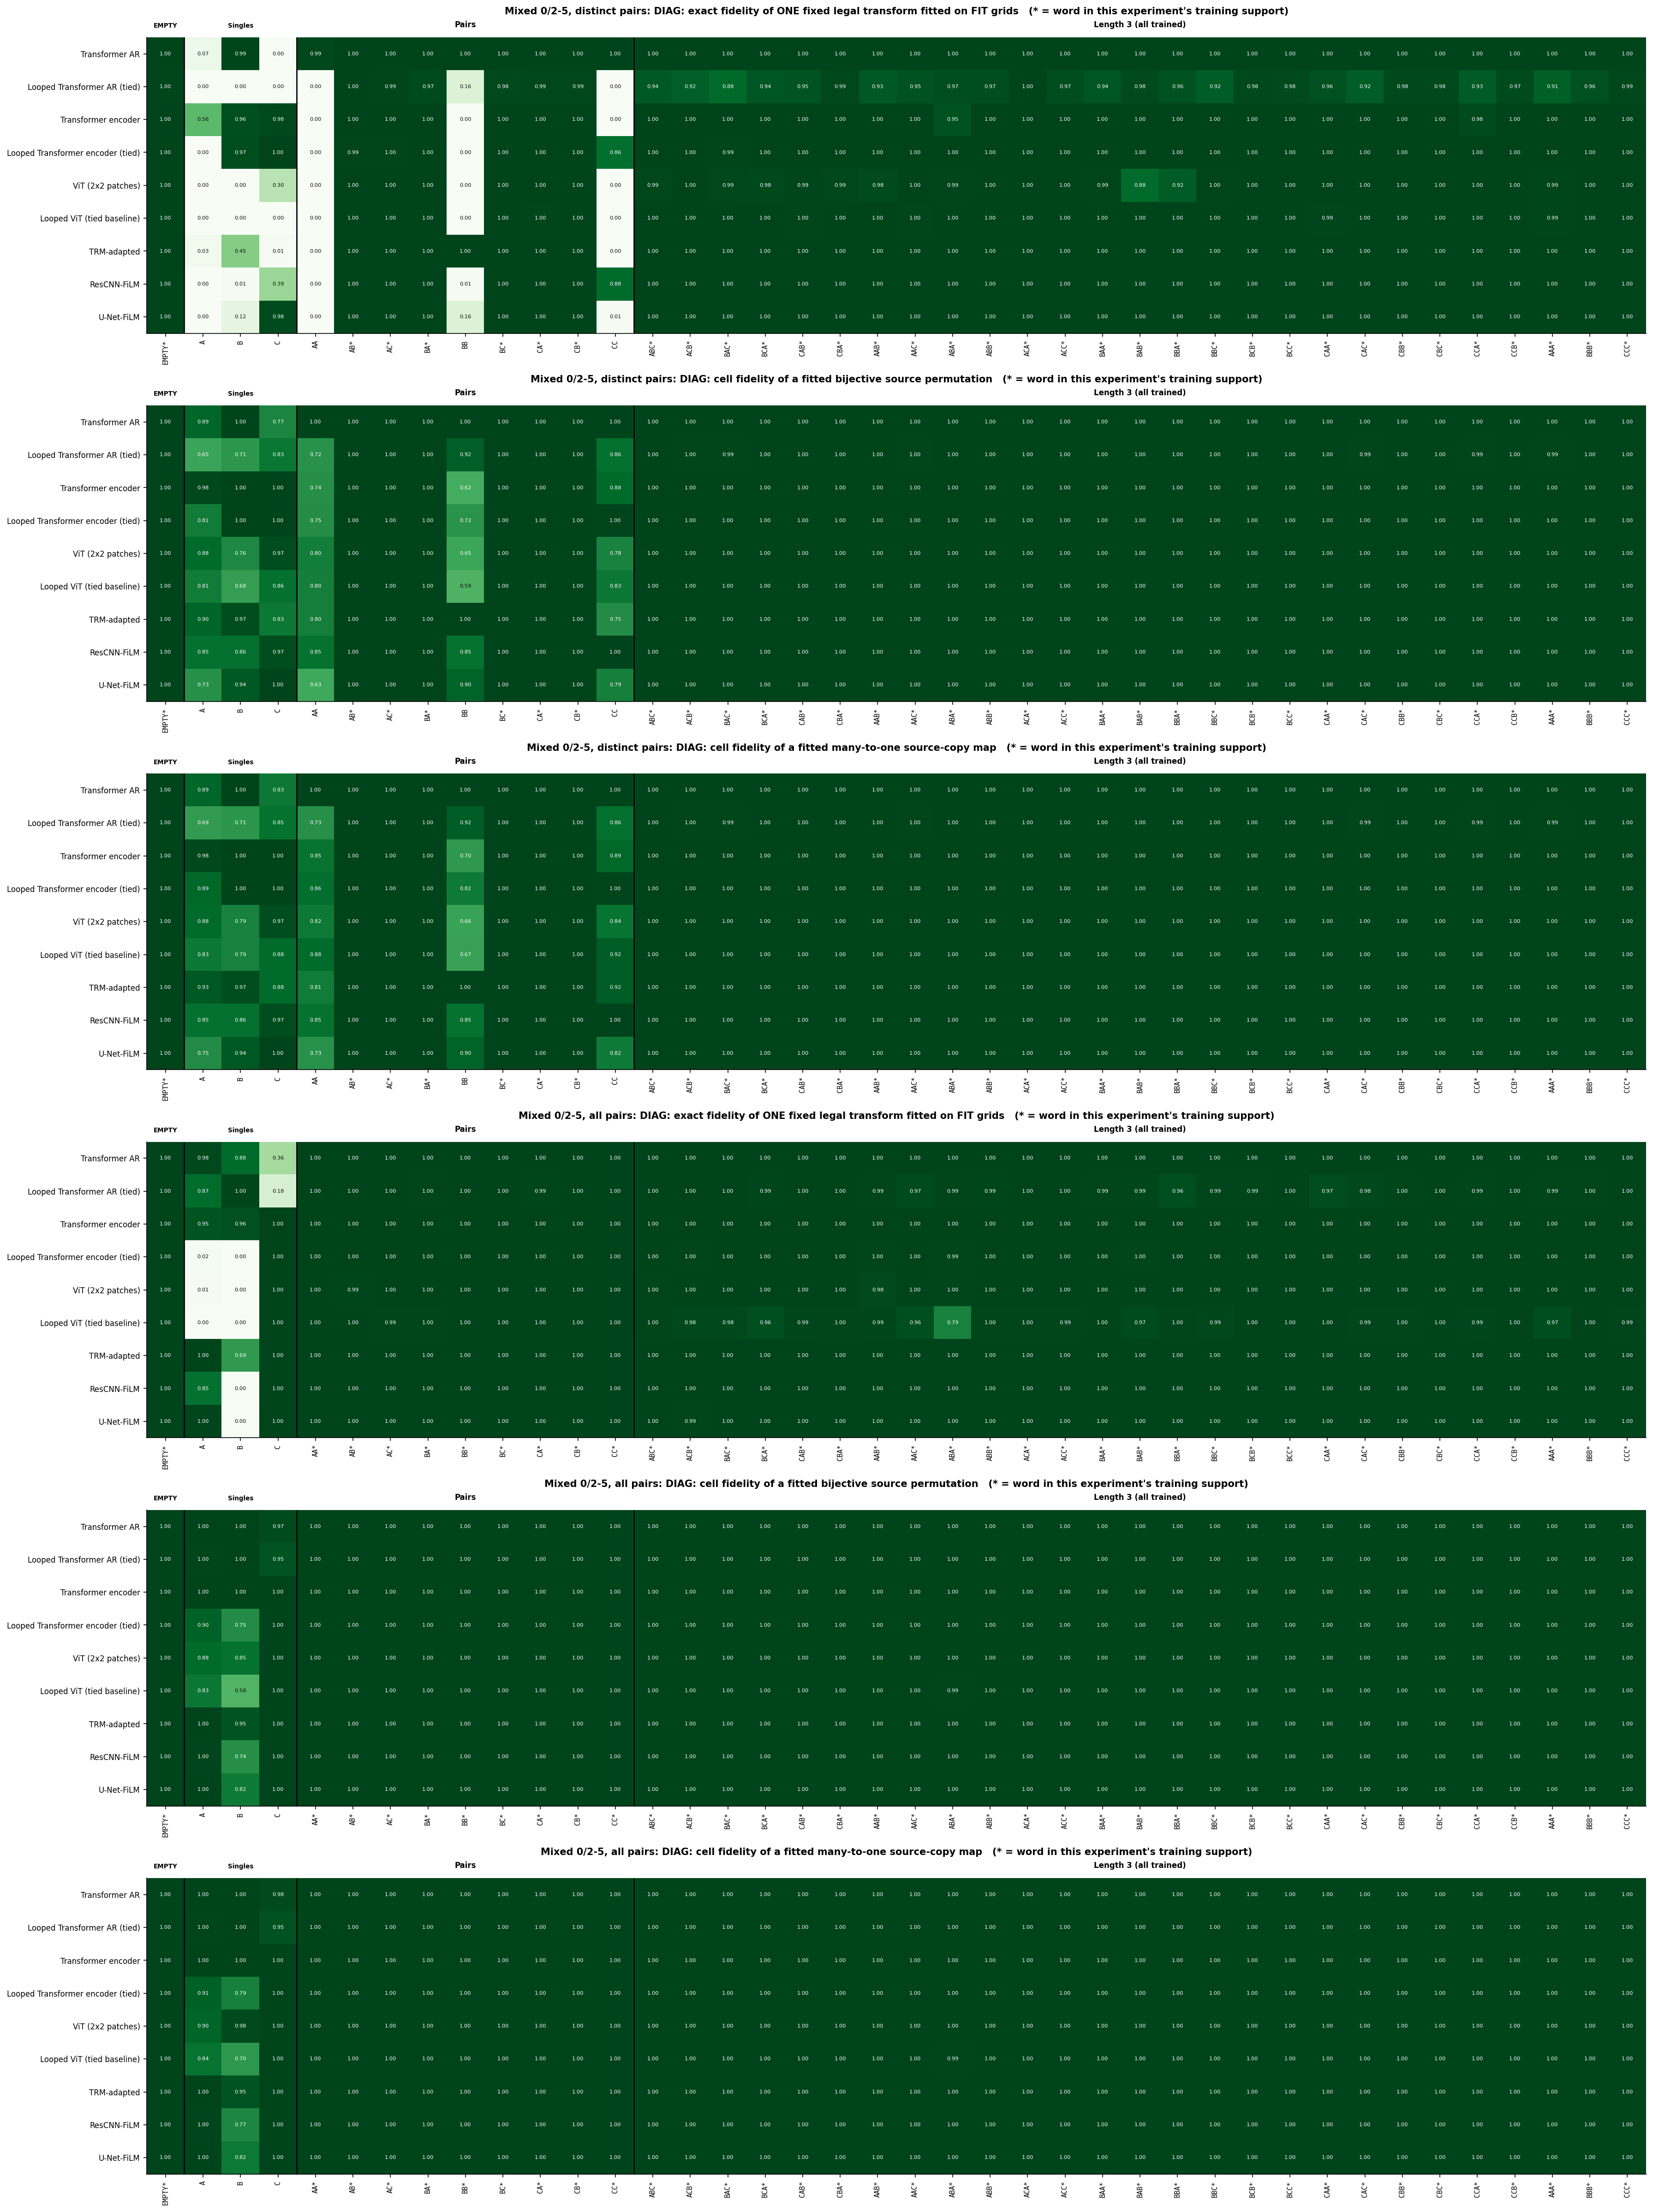

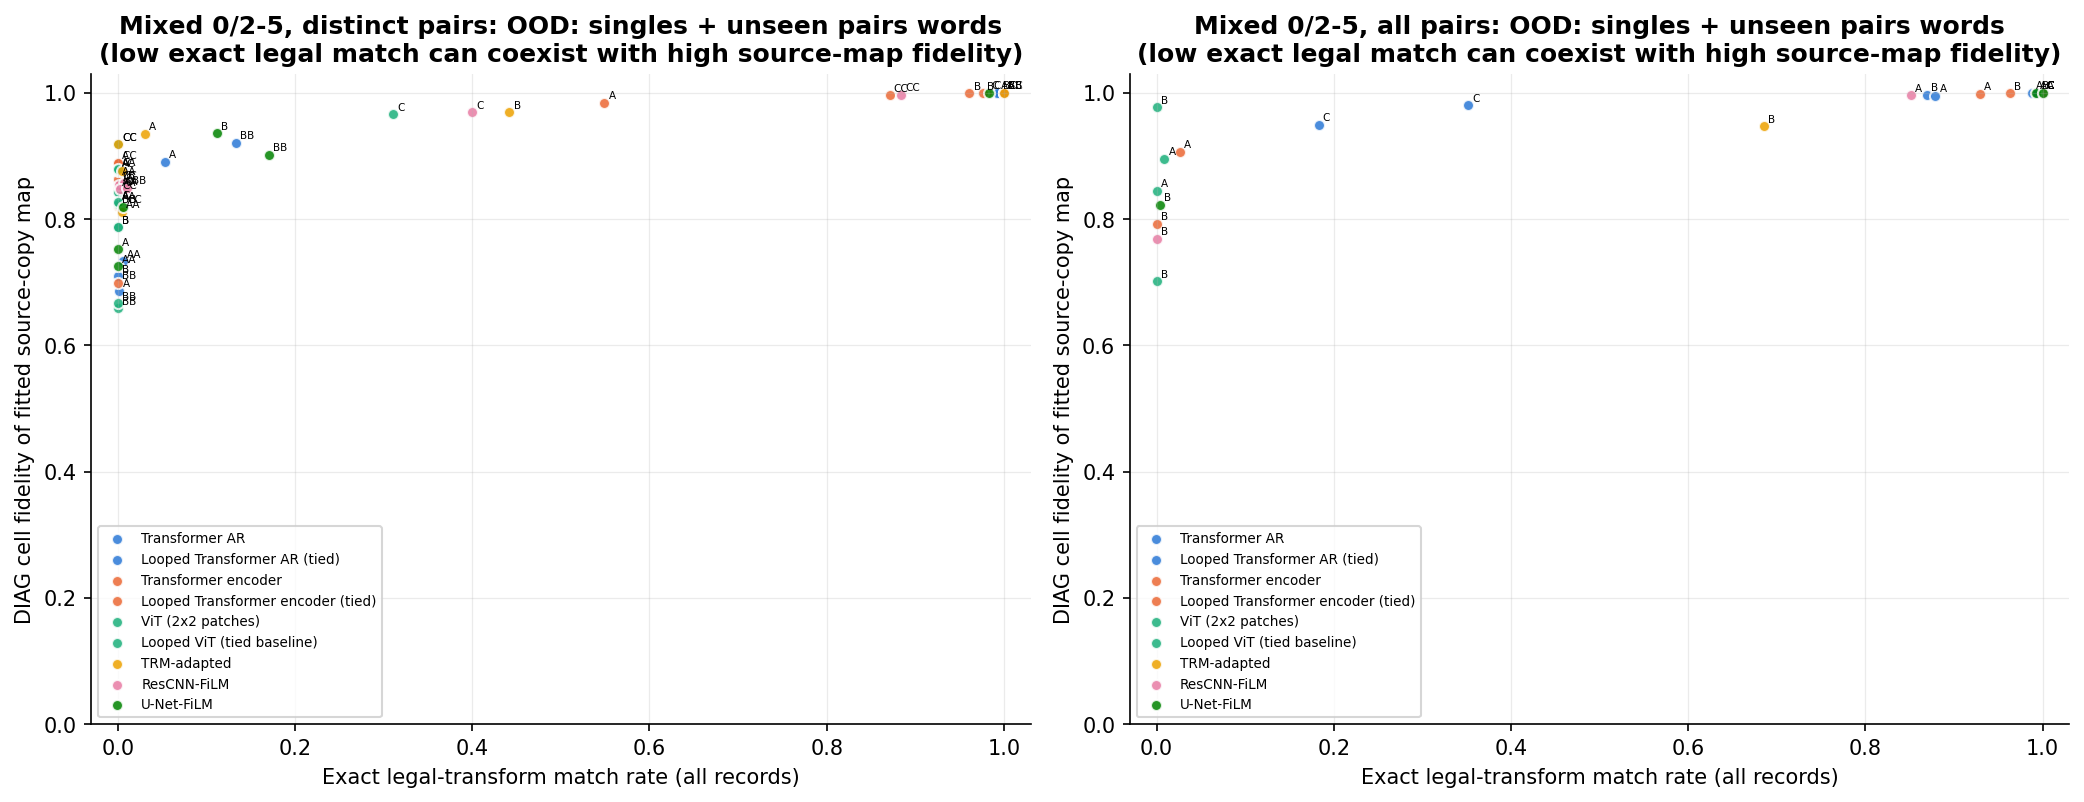

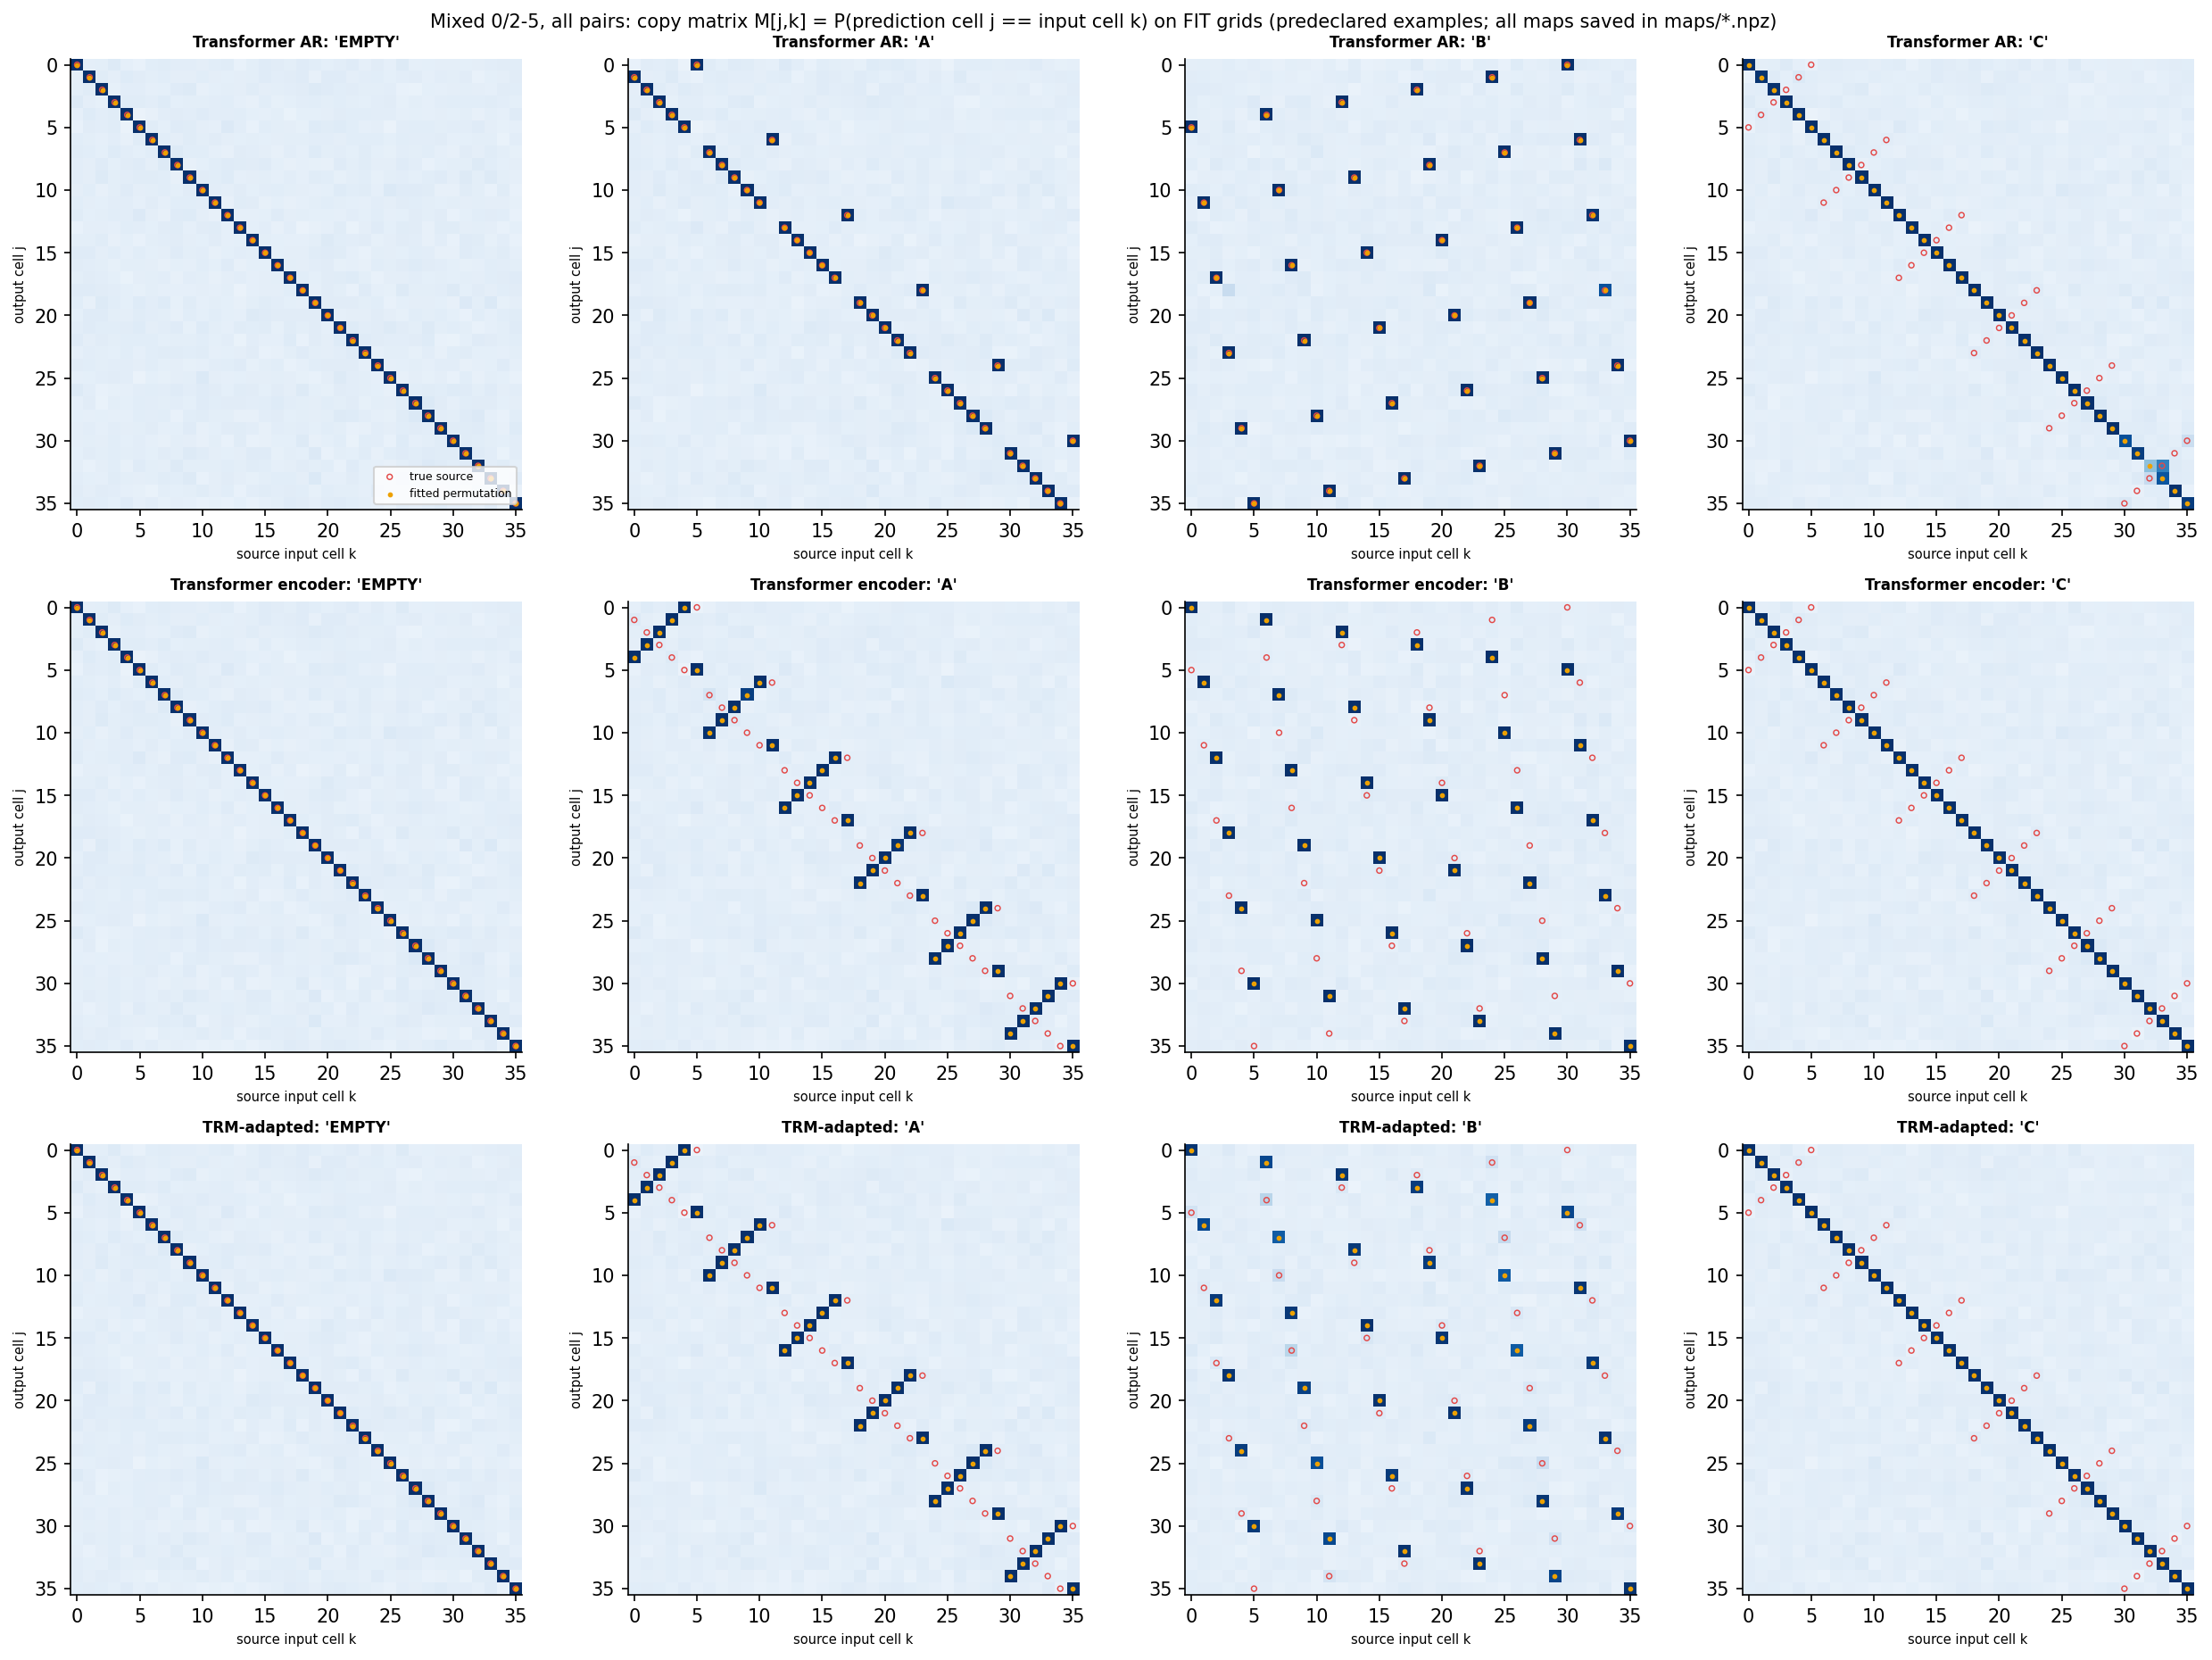

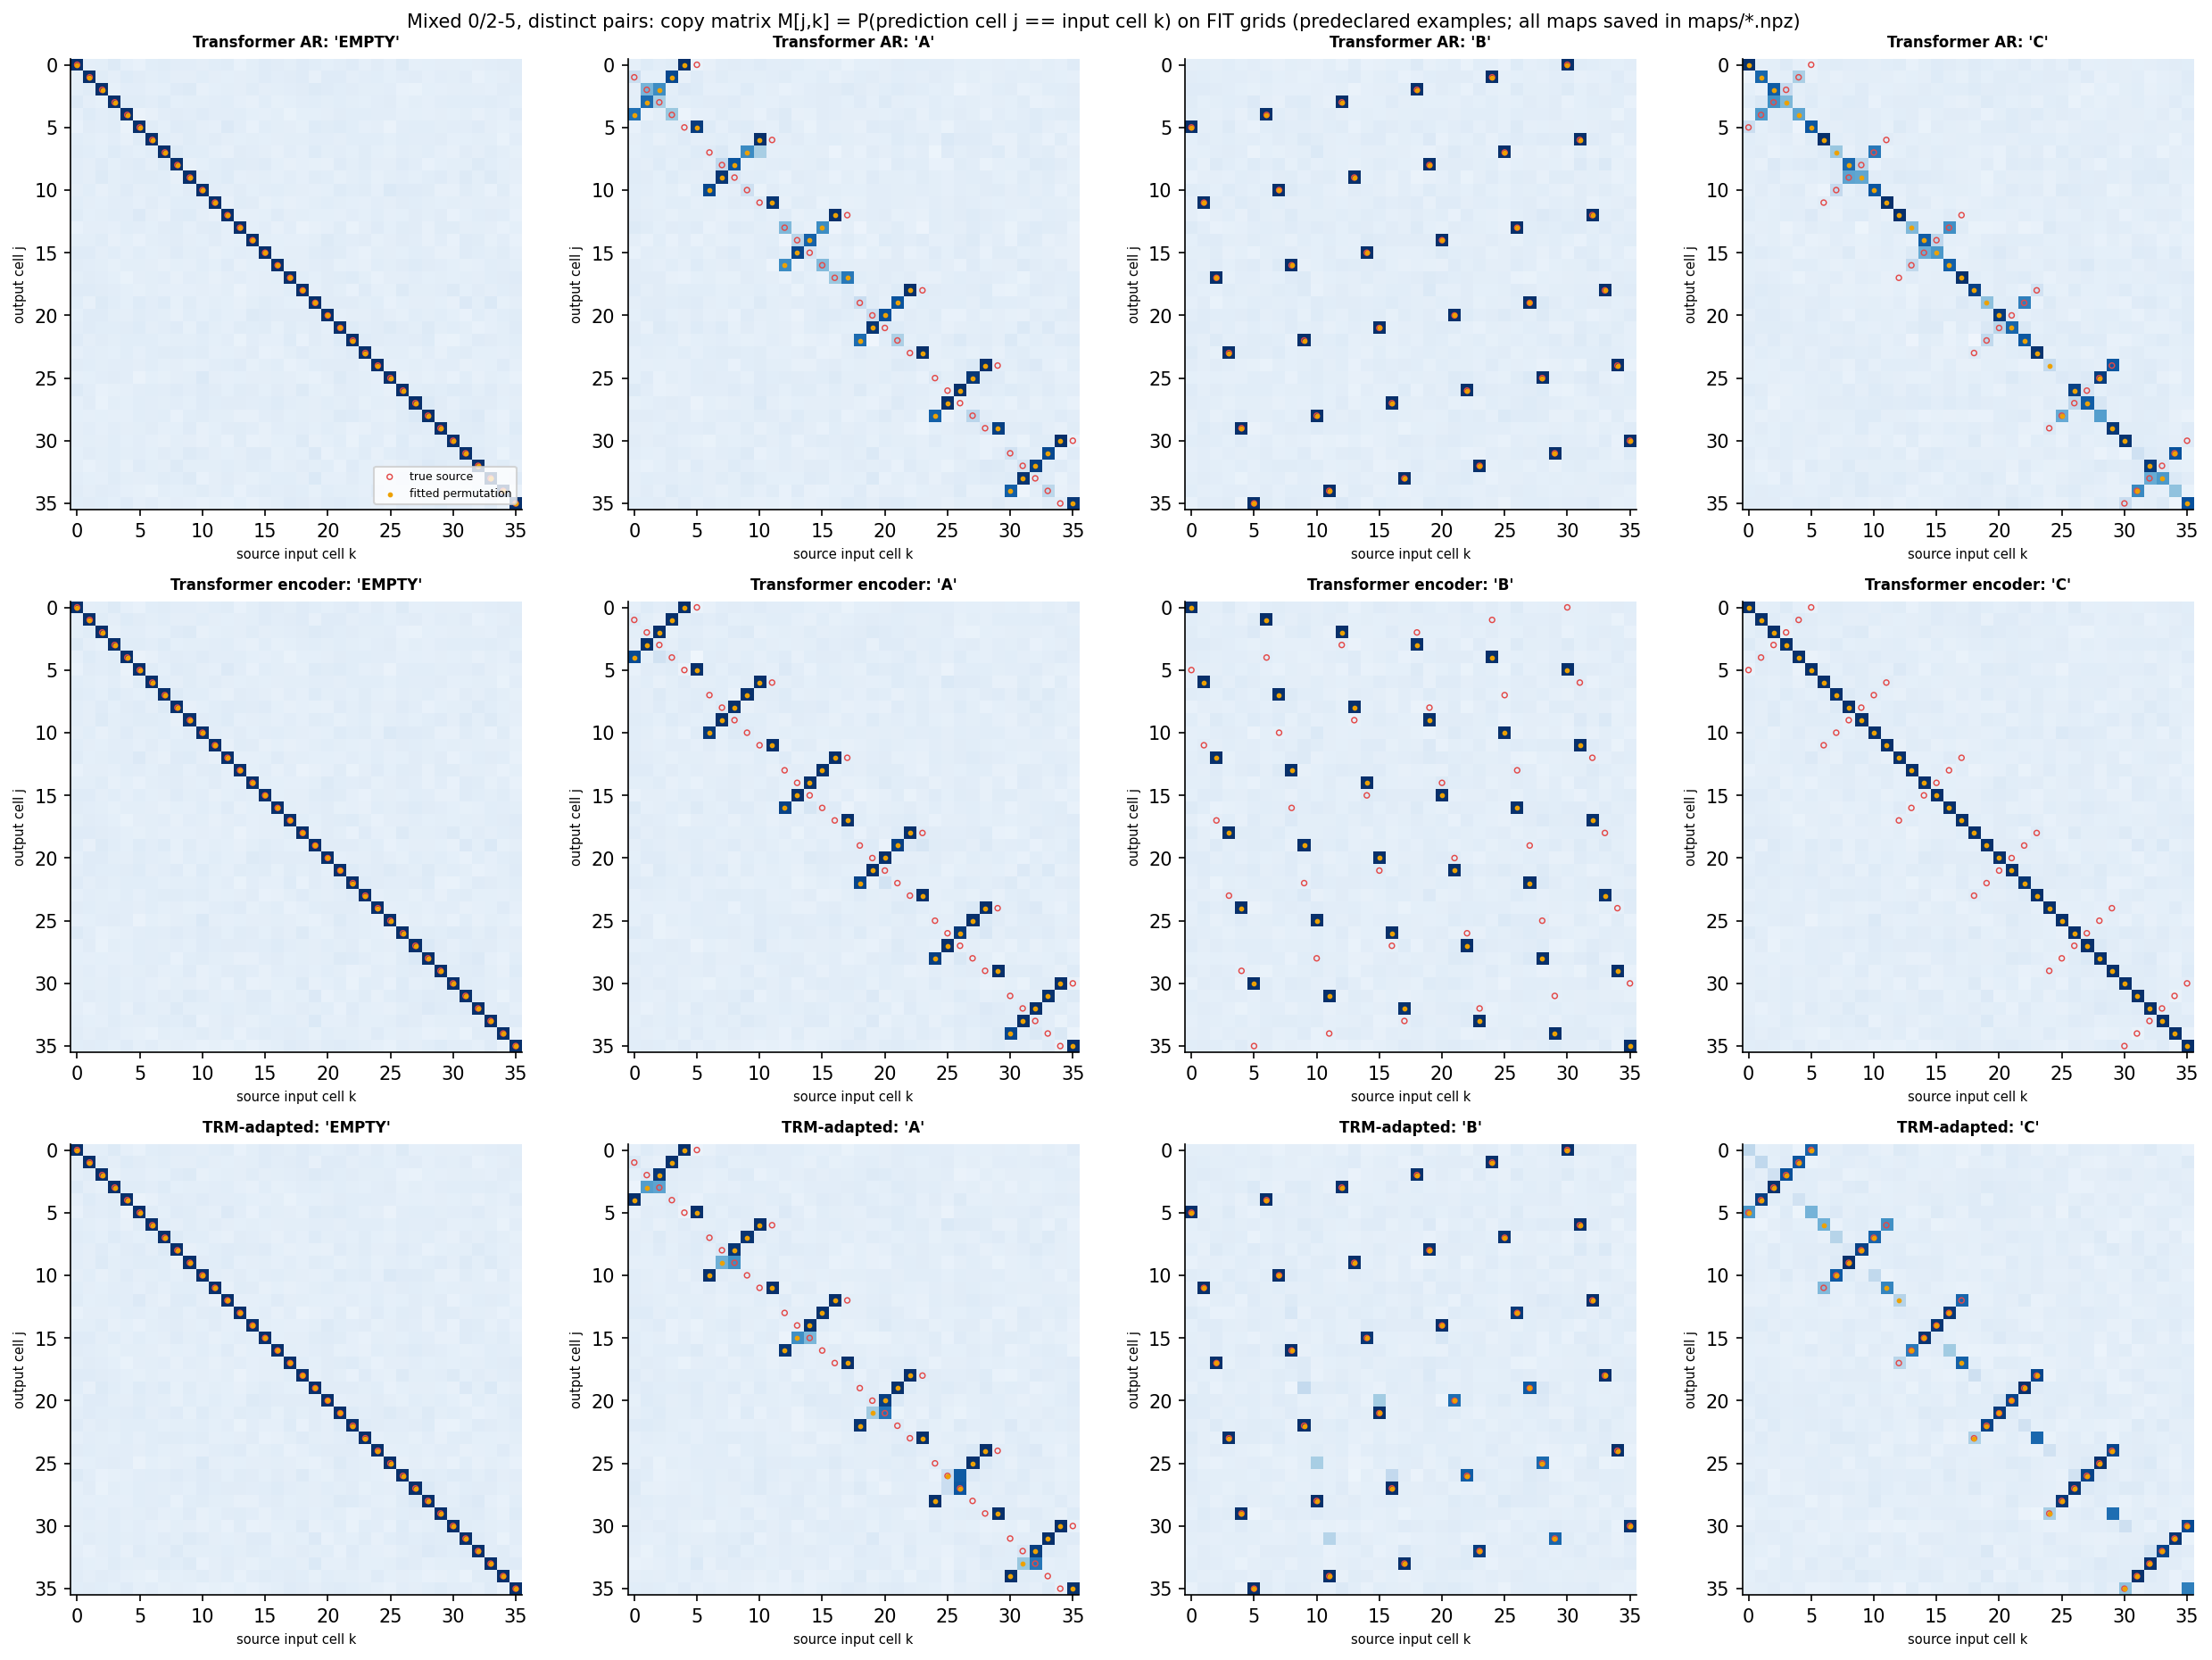

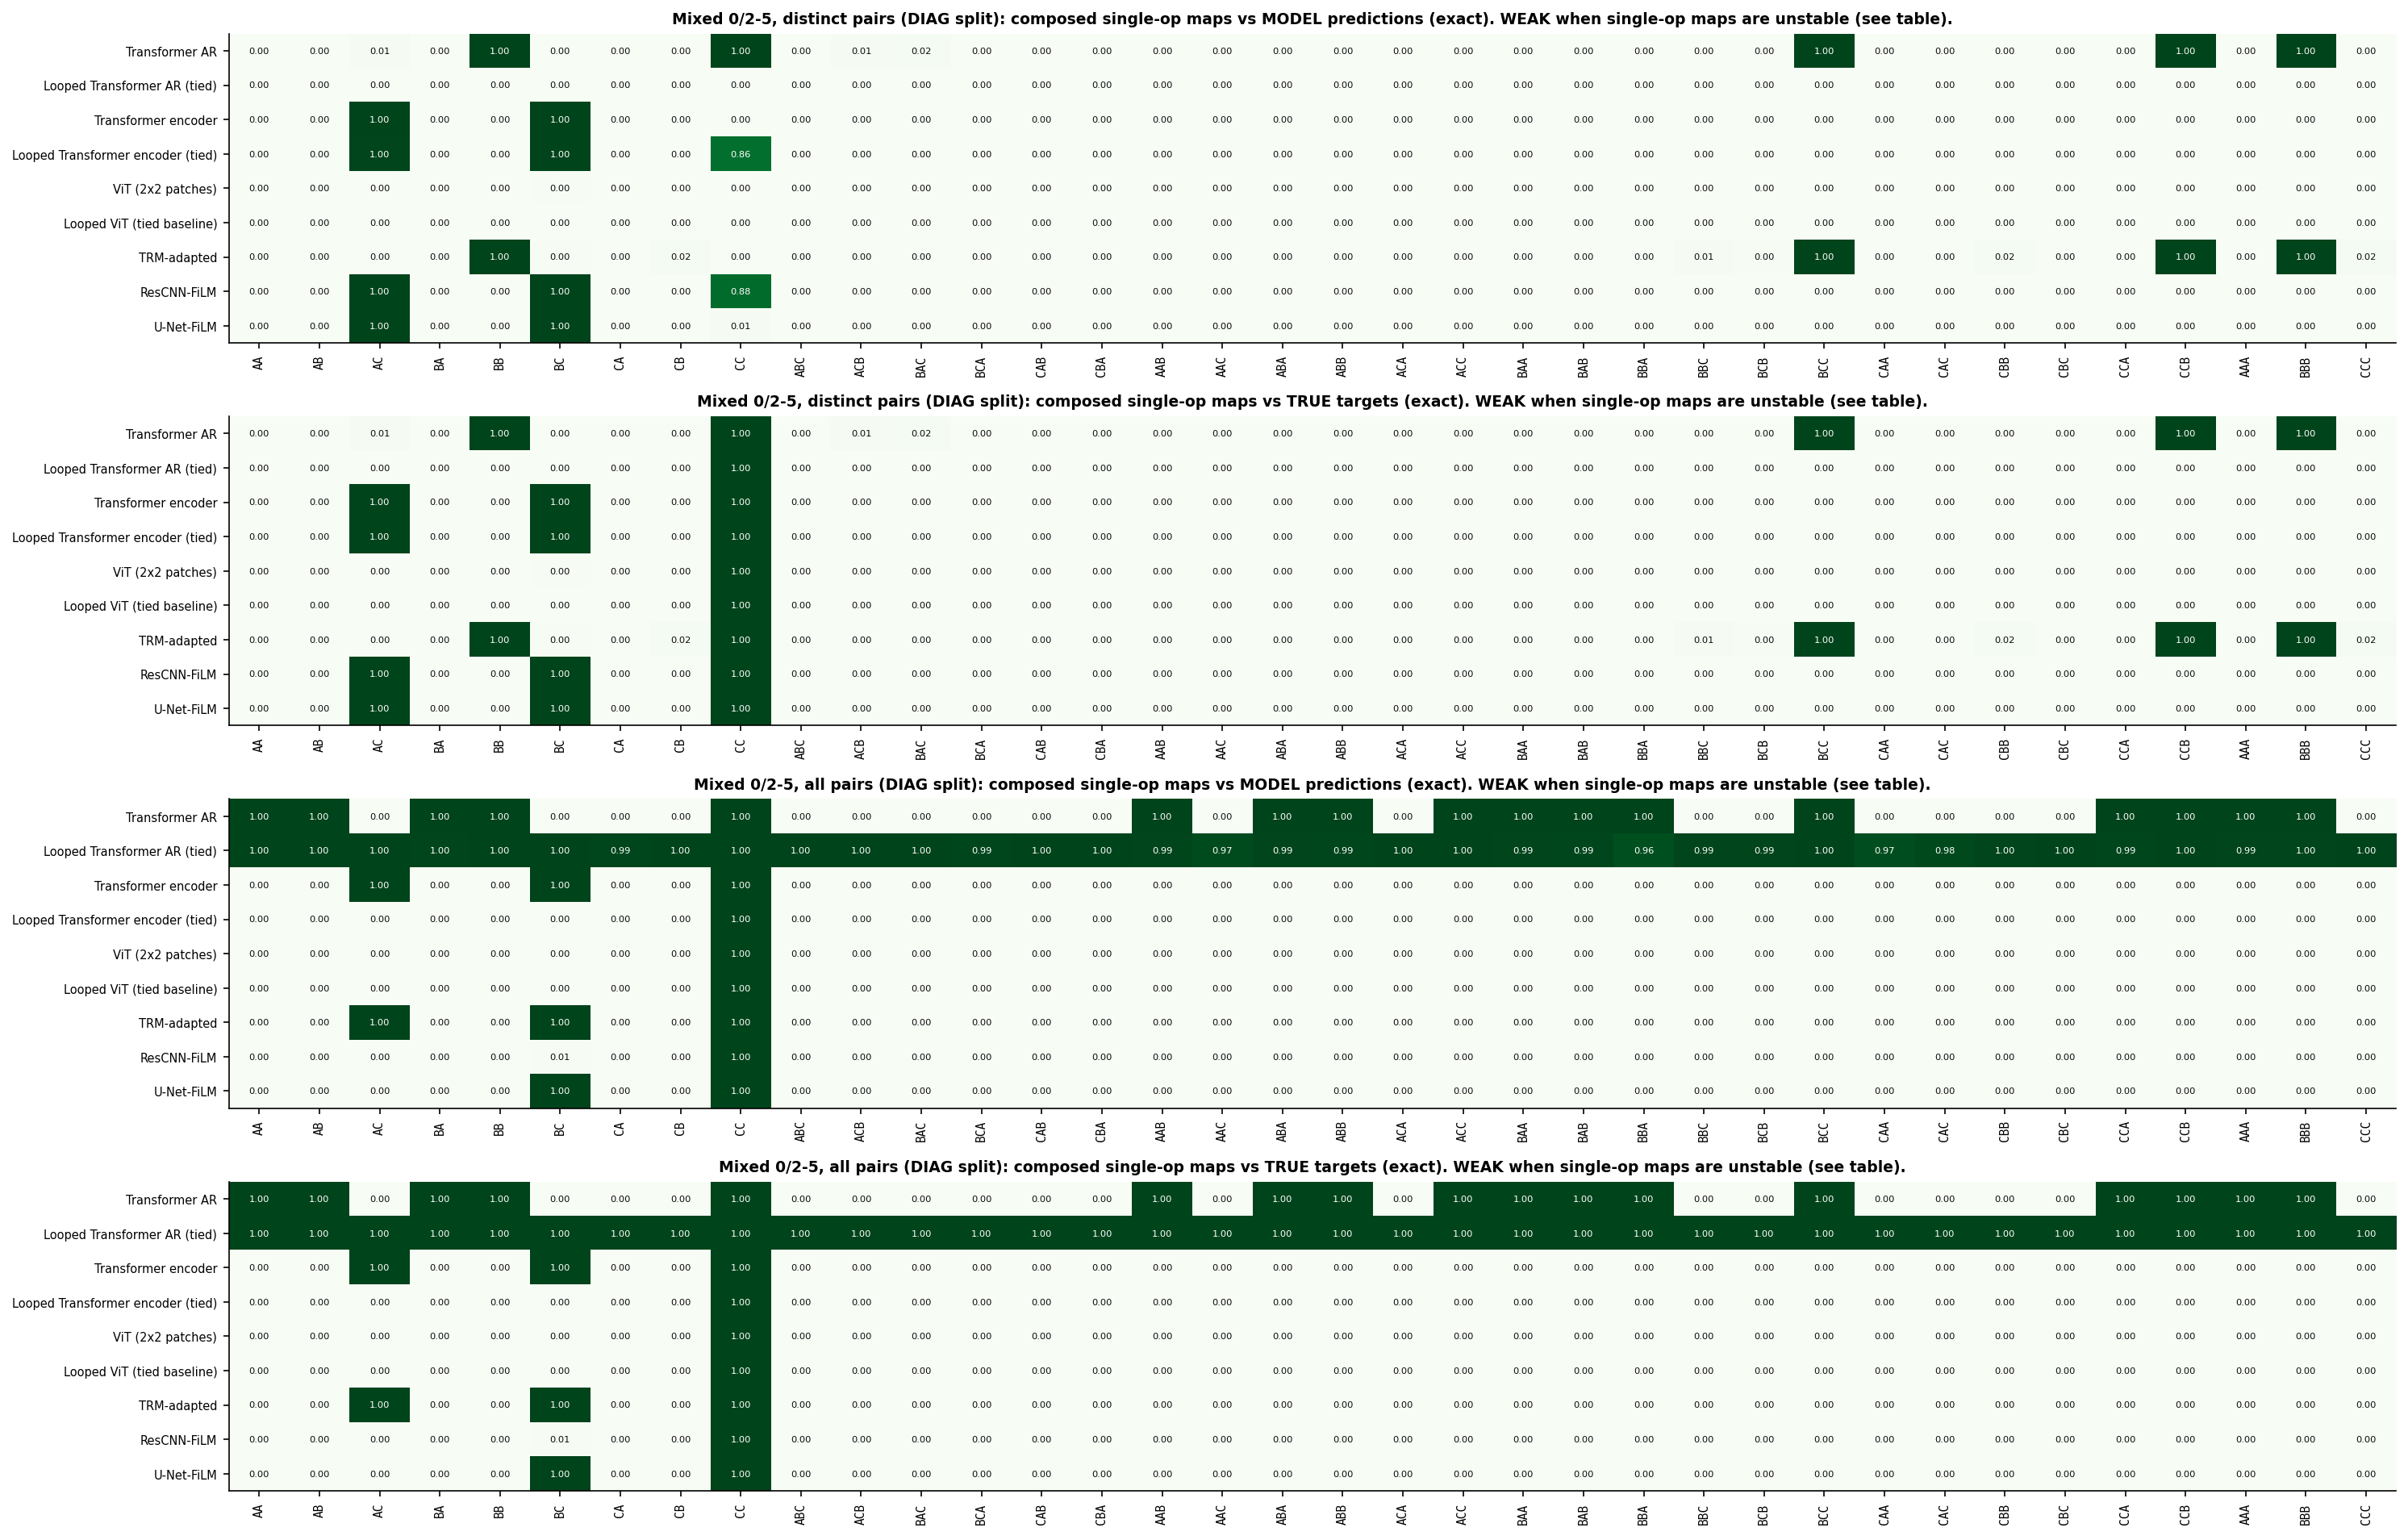

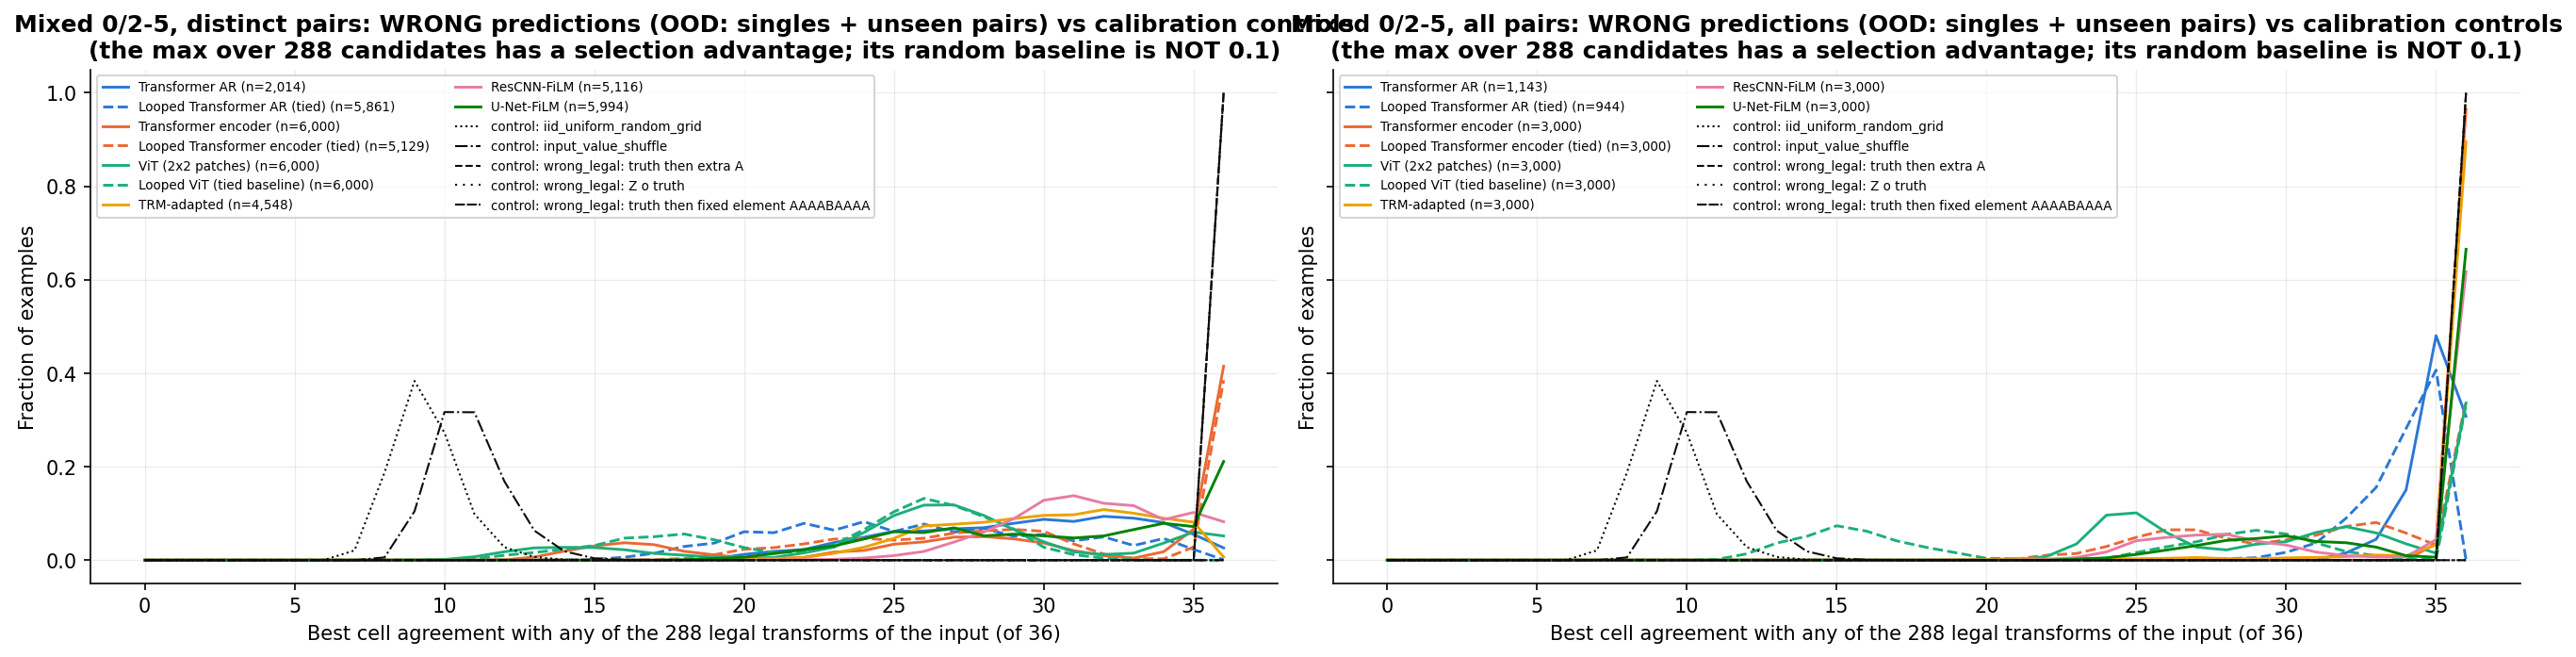

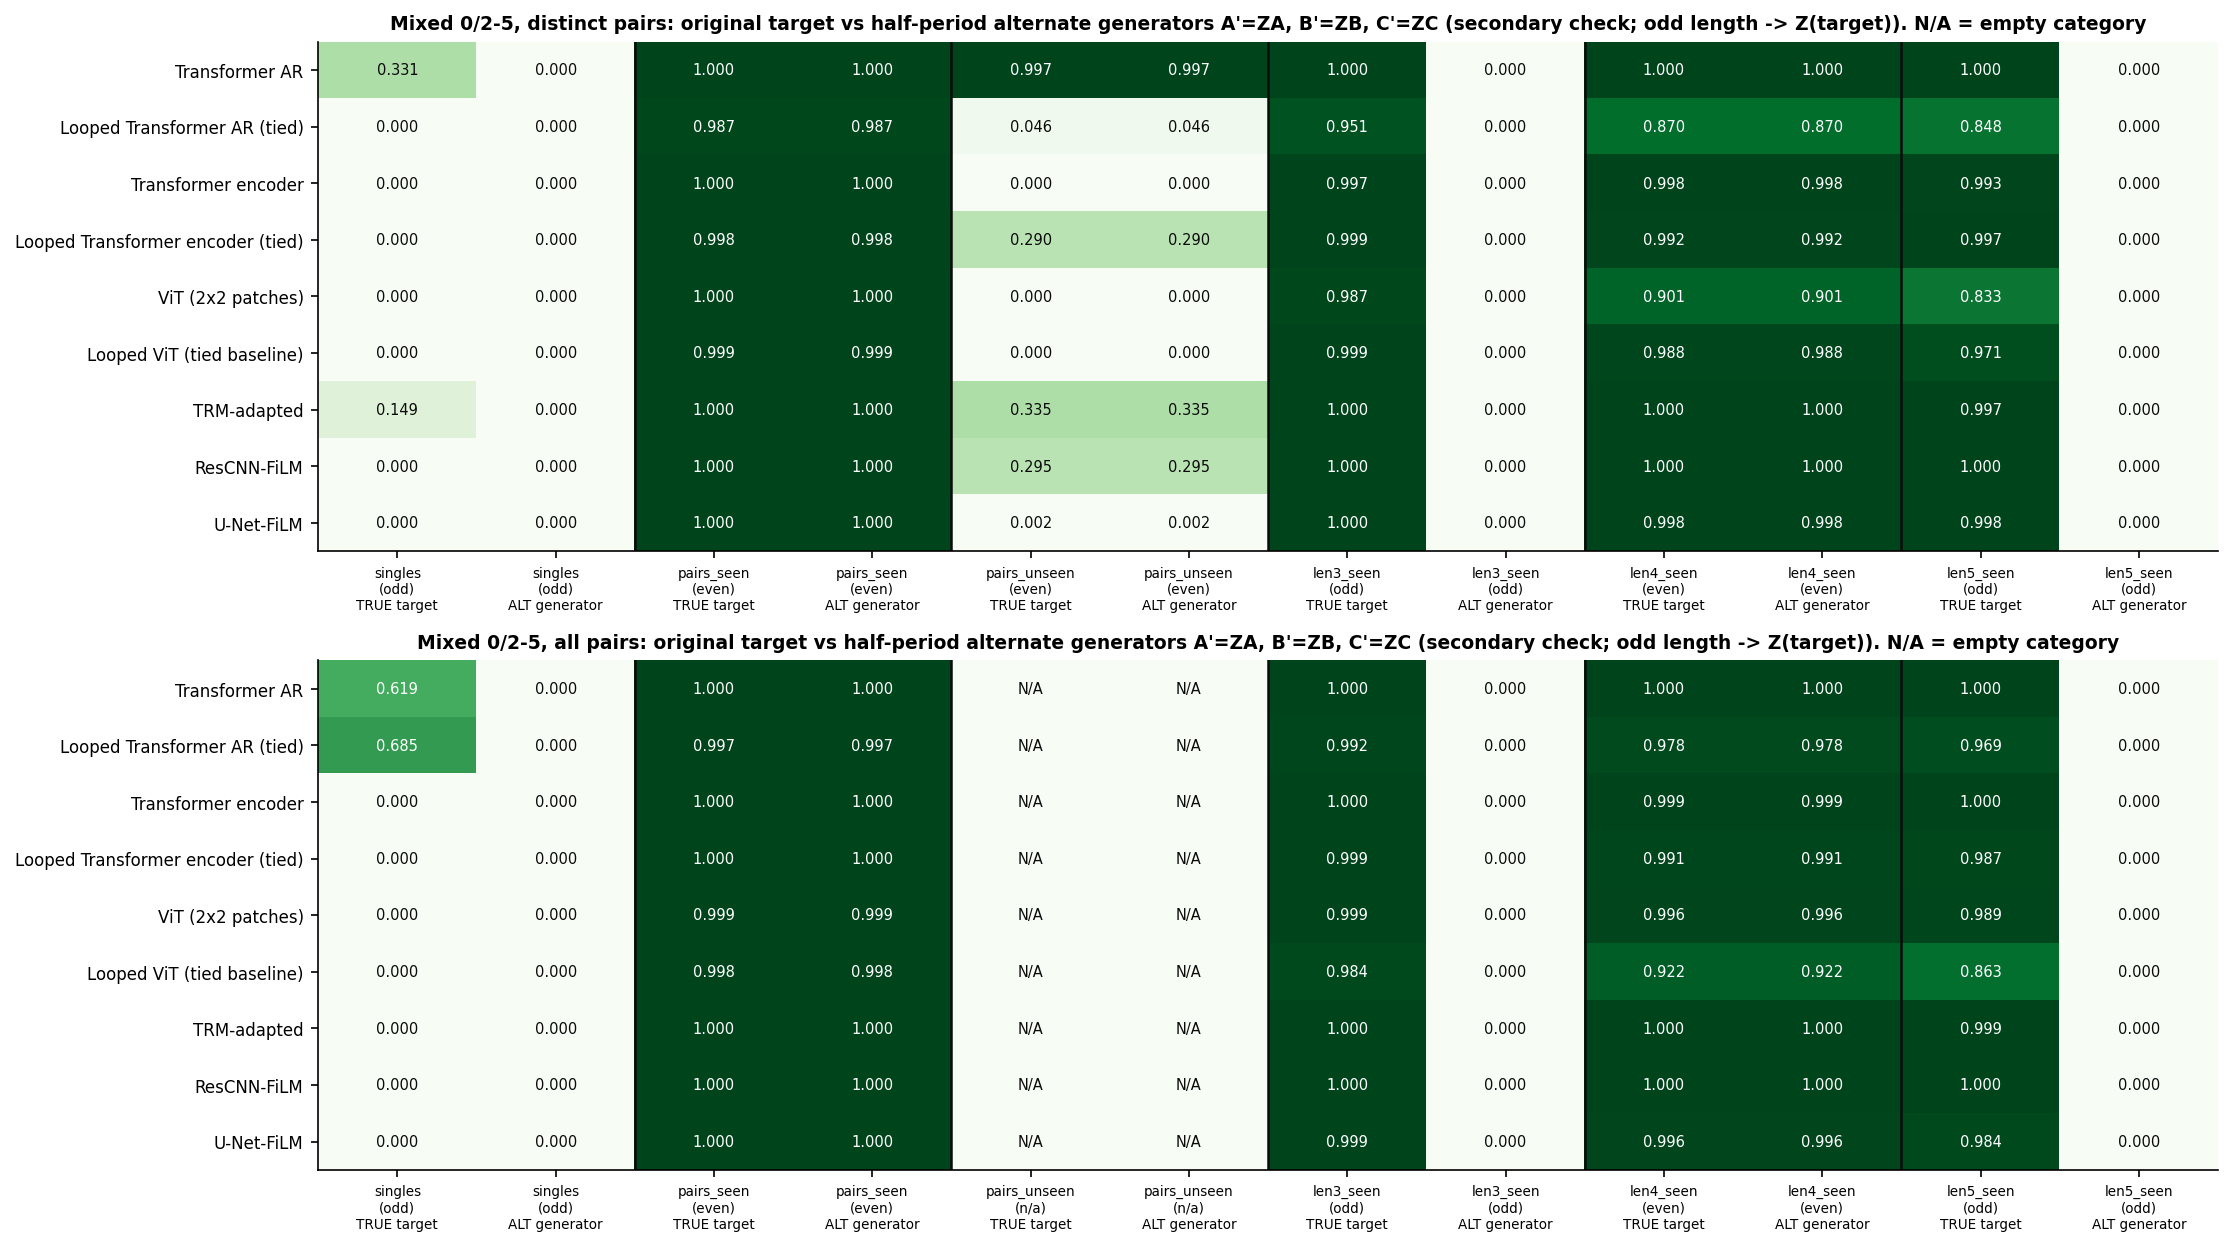

,control,n,exact_group_match_rate,ambiguous_exact_match_rate,mean_best_group_cell_agreement,p05_best,median_best,p95_best,cell_acc_vs_true_target
0,iid_uniform_random_grid,40000,0.0,0.0,0.259886,0.222222,0.250000,0.305556,0.100013
1,input_value_shuffle,40000,0.0,0.0,0.300845,0.250000,0.305556,0.361111,0.124969
2,wrong_legal: truth then extra A,40000,1.0,0.0,1.000000,1.000000,1.000000,1.000000,0.100363
3,wrong_legal: Z o truth,40000,1.0,0.0,1.000000,1.000000,1.000000,1.000000,0.096500
4,wrong_legal: truth then fixed element AAAABAAAA,40000,1.0,0.0,1.000000,1.000000,1.000000,1.000000,0.100591


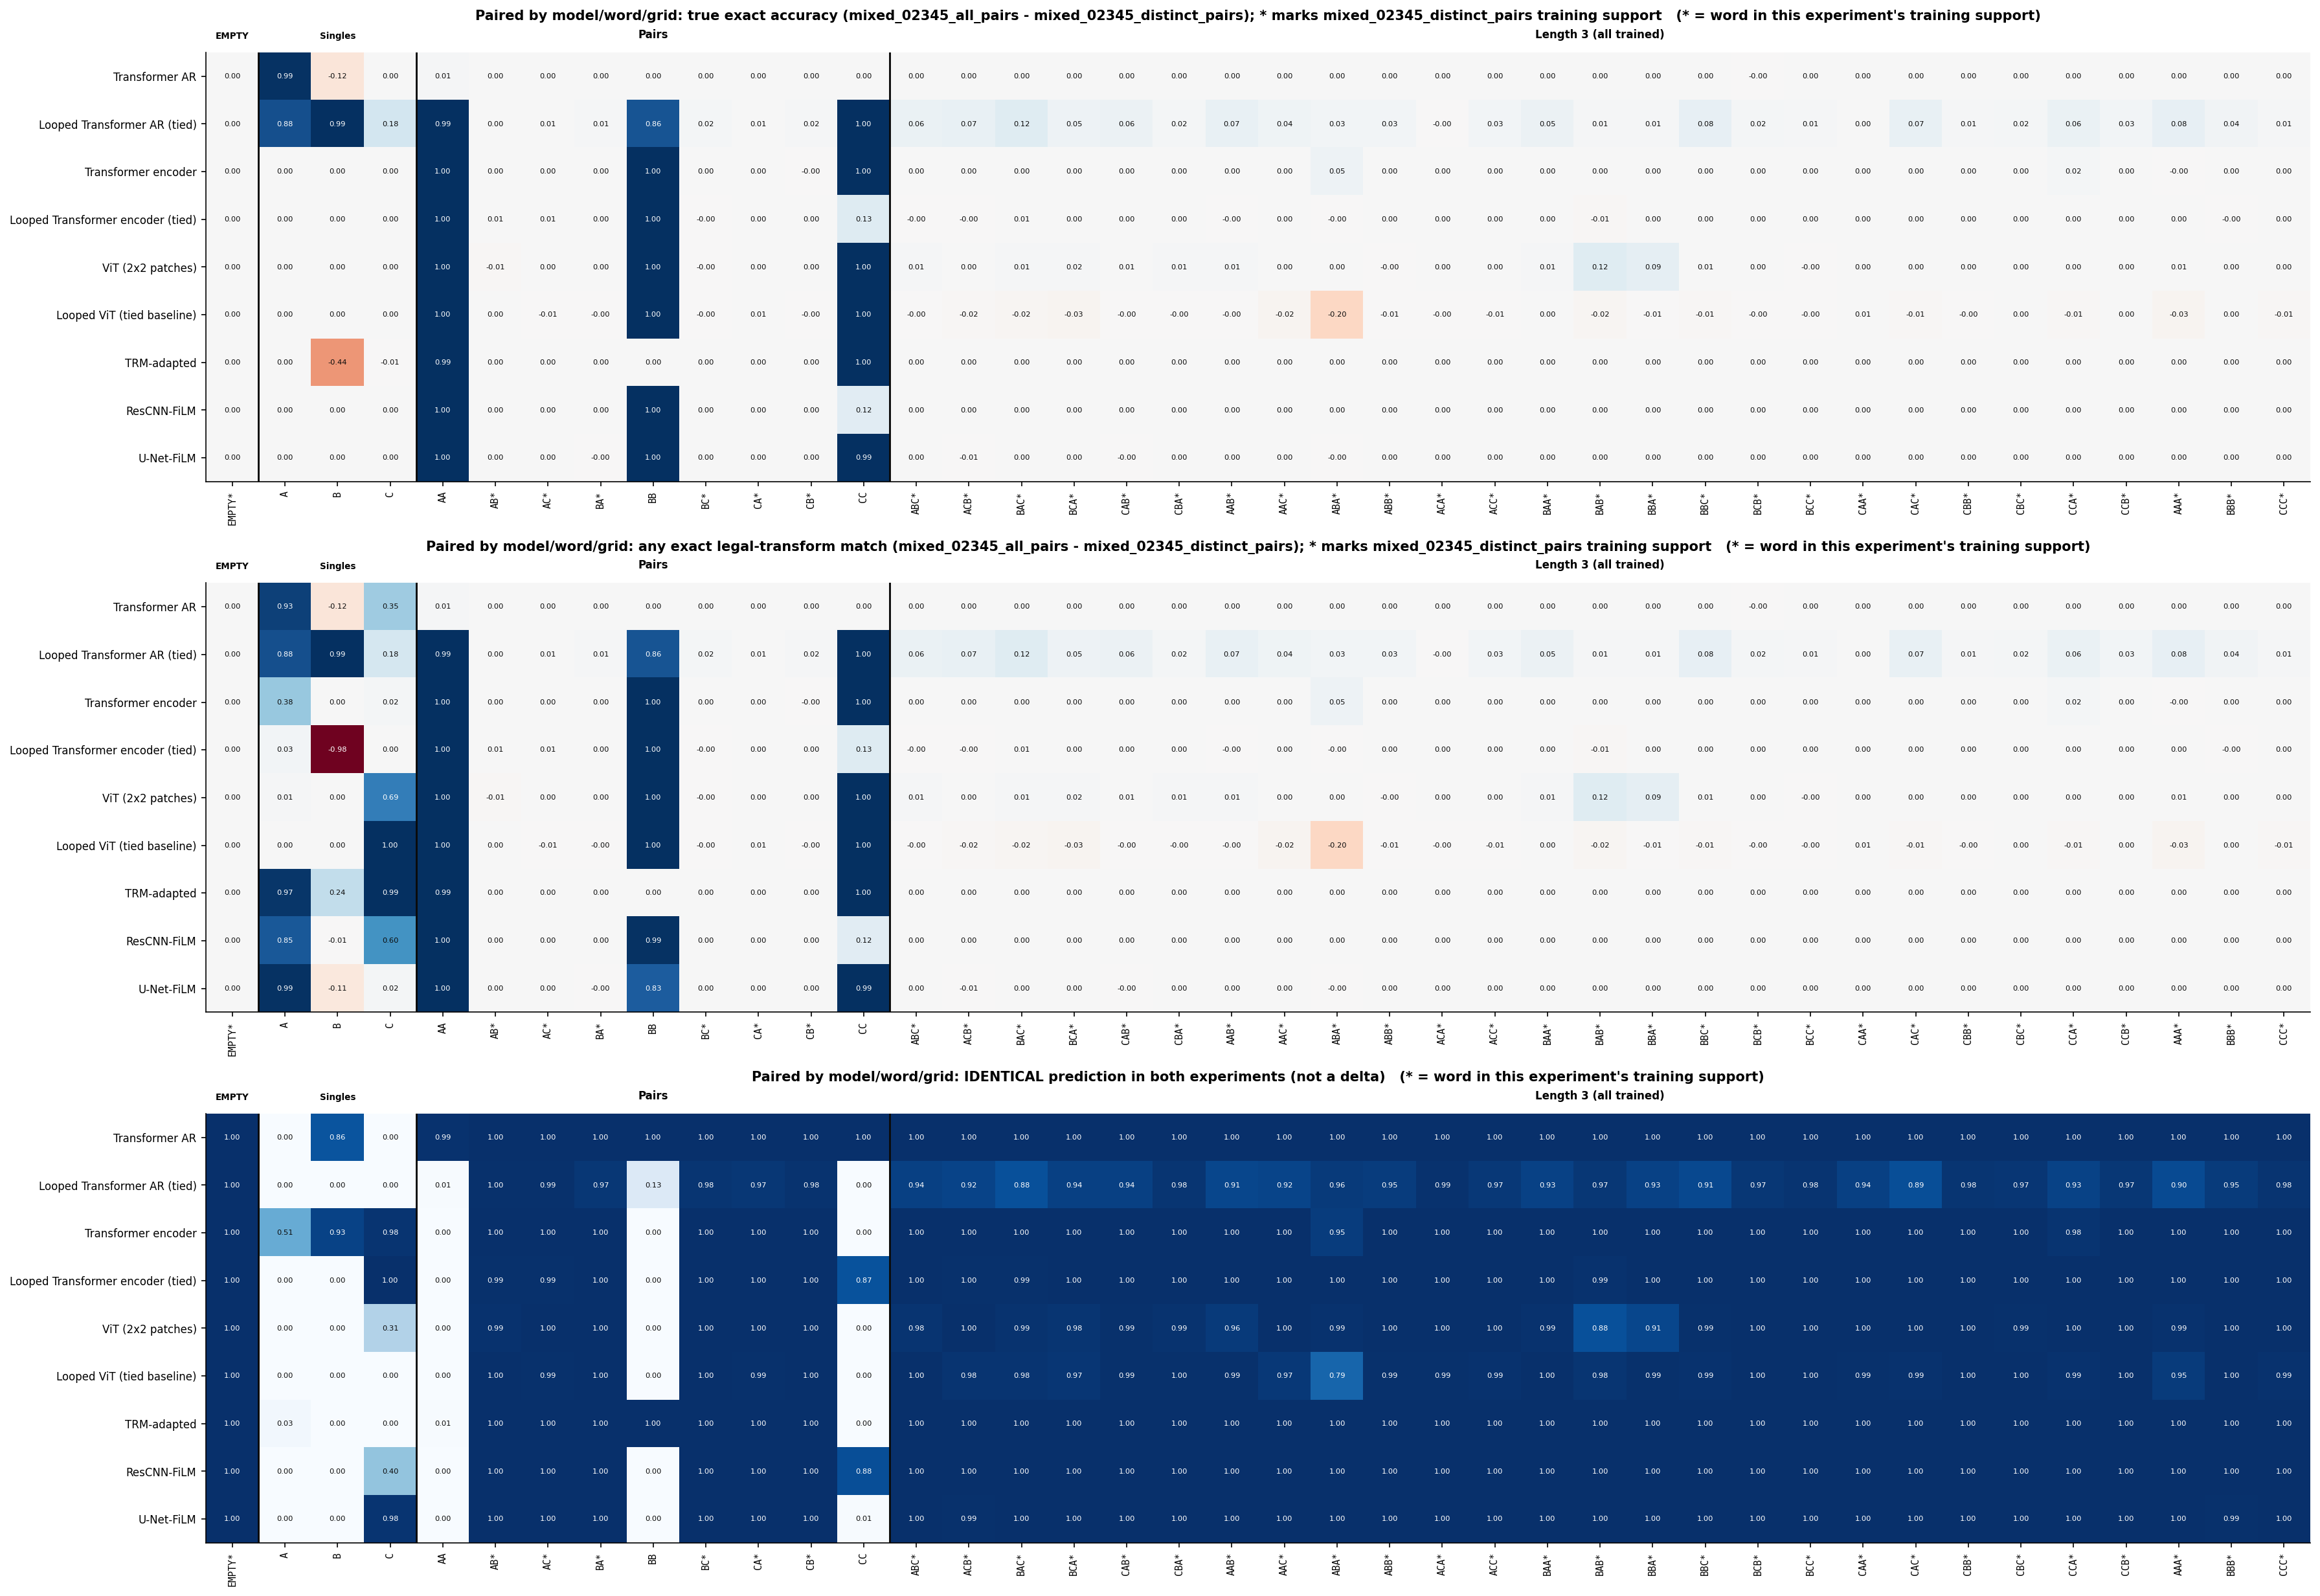

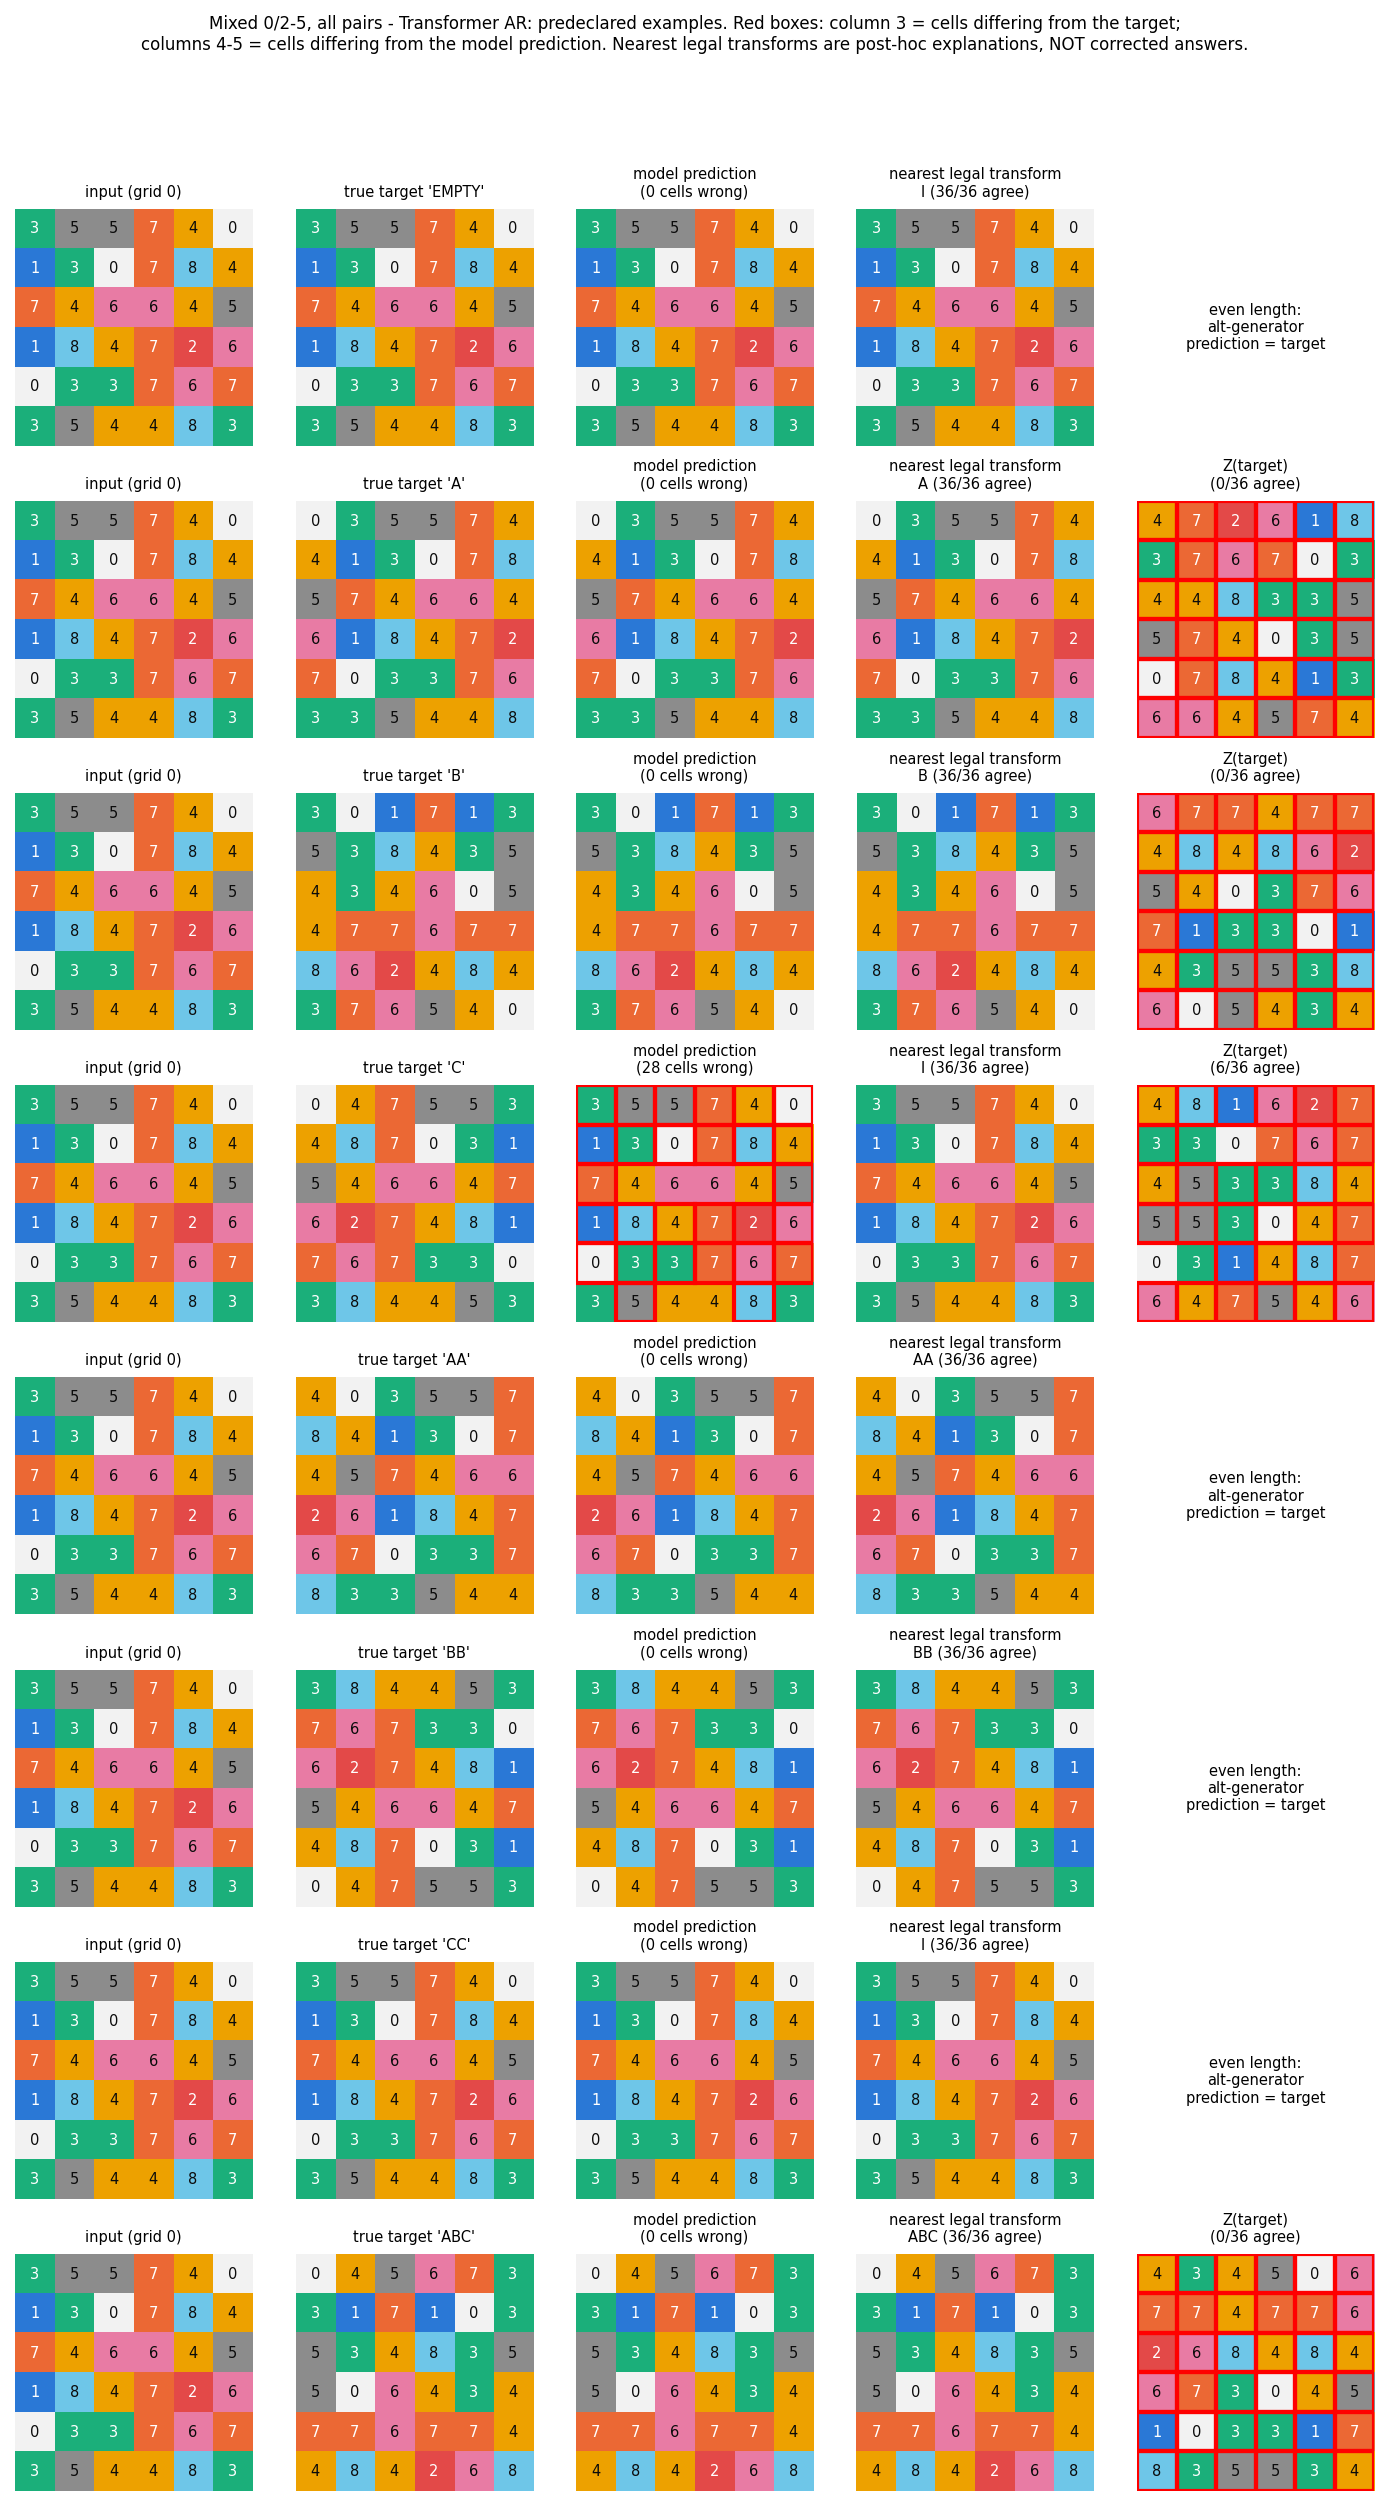

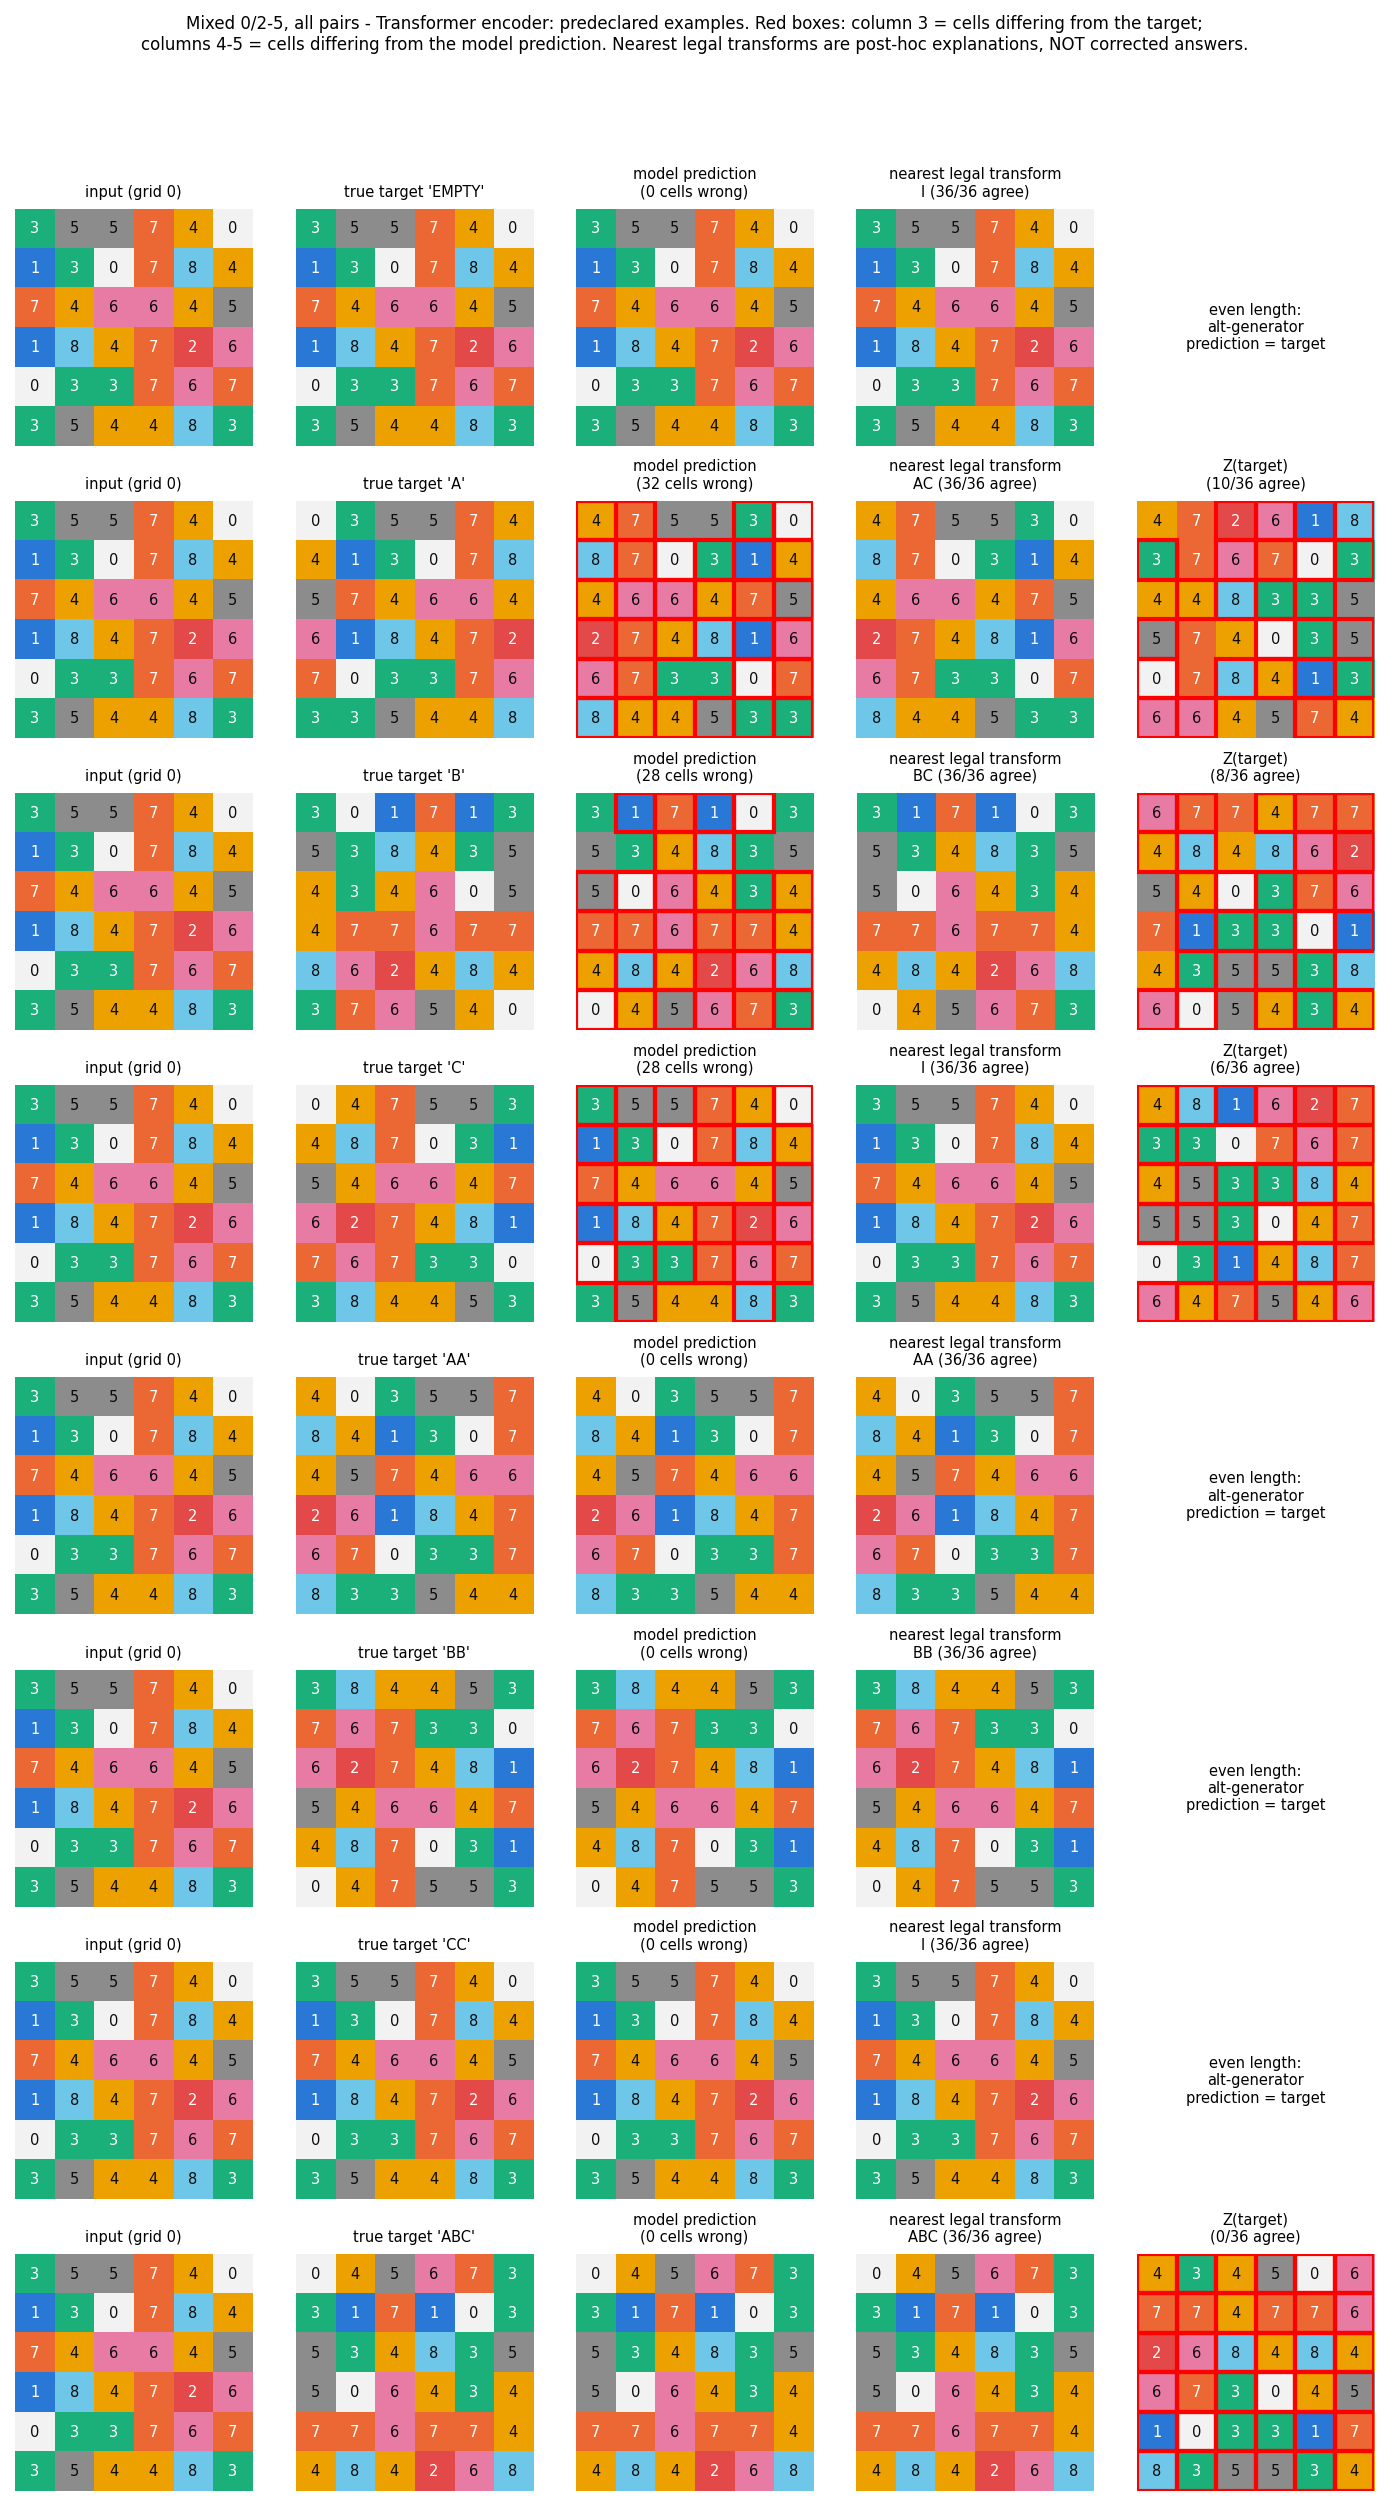

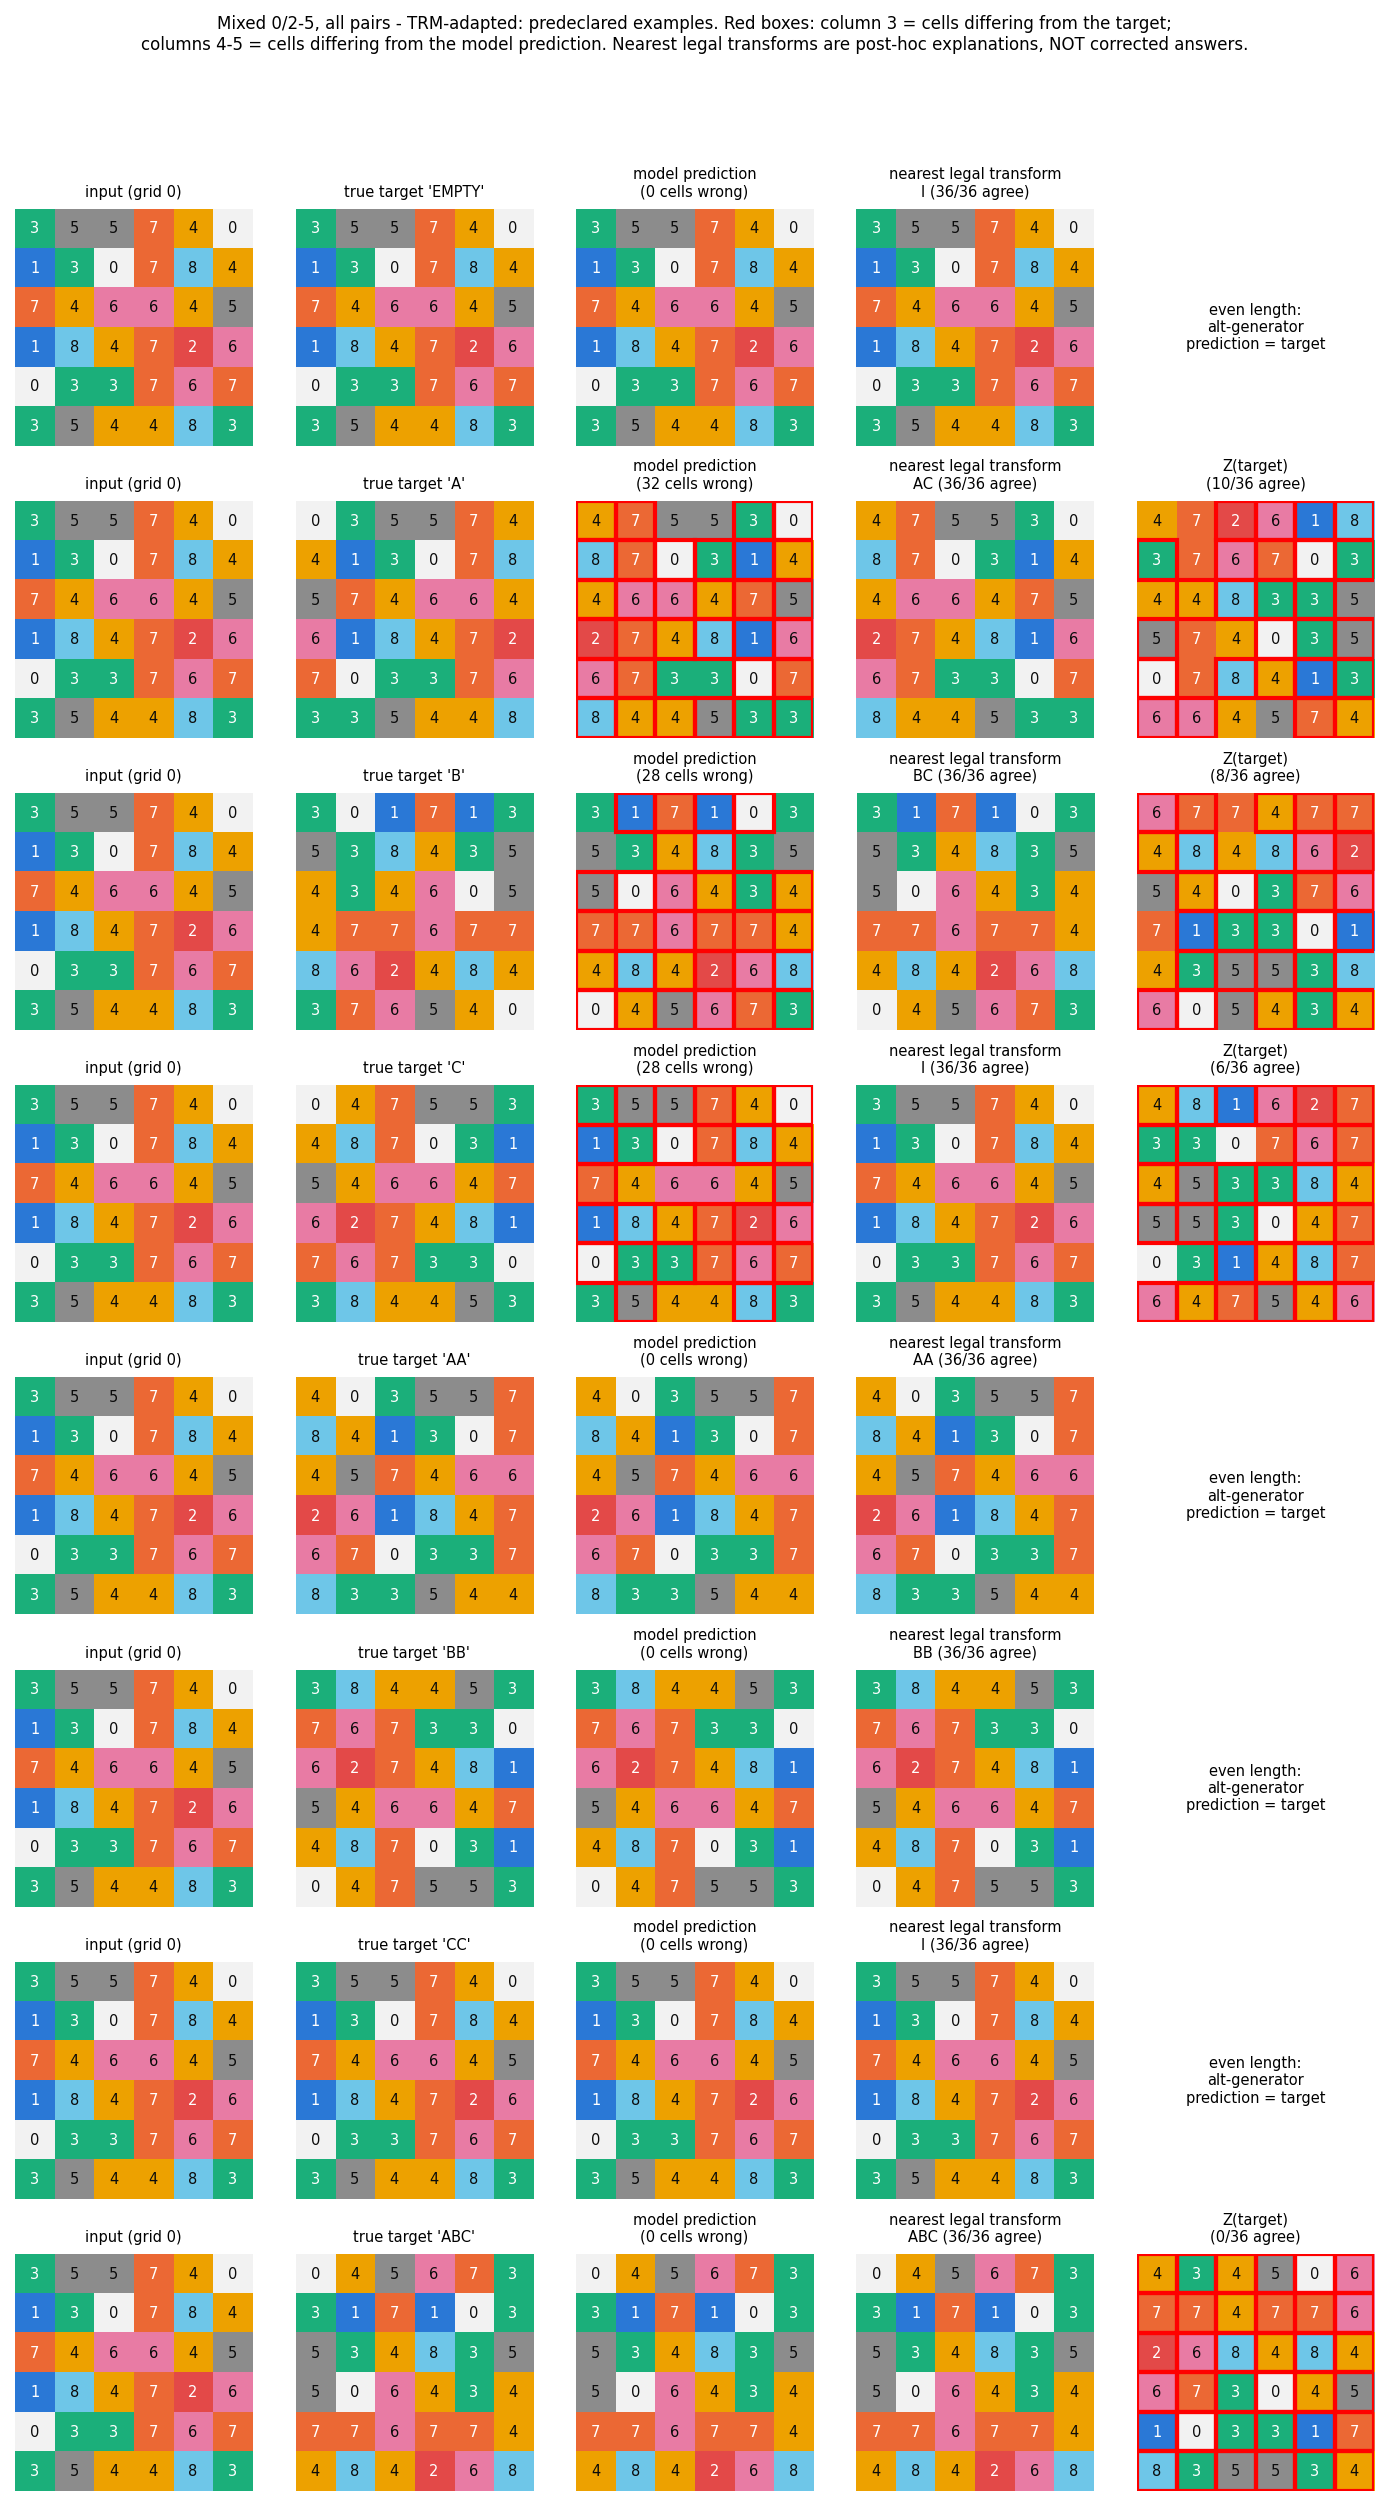

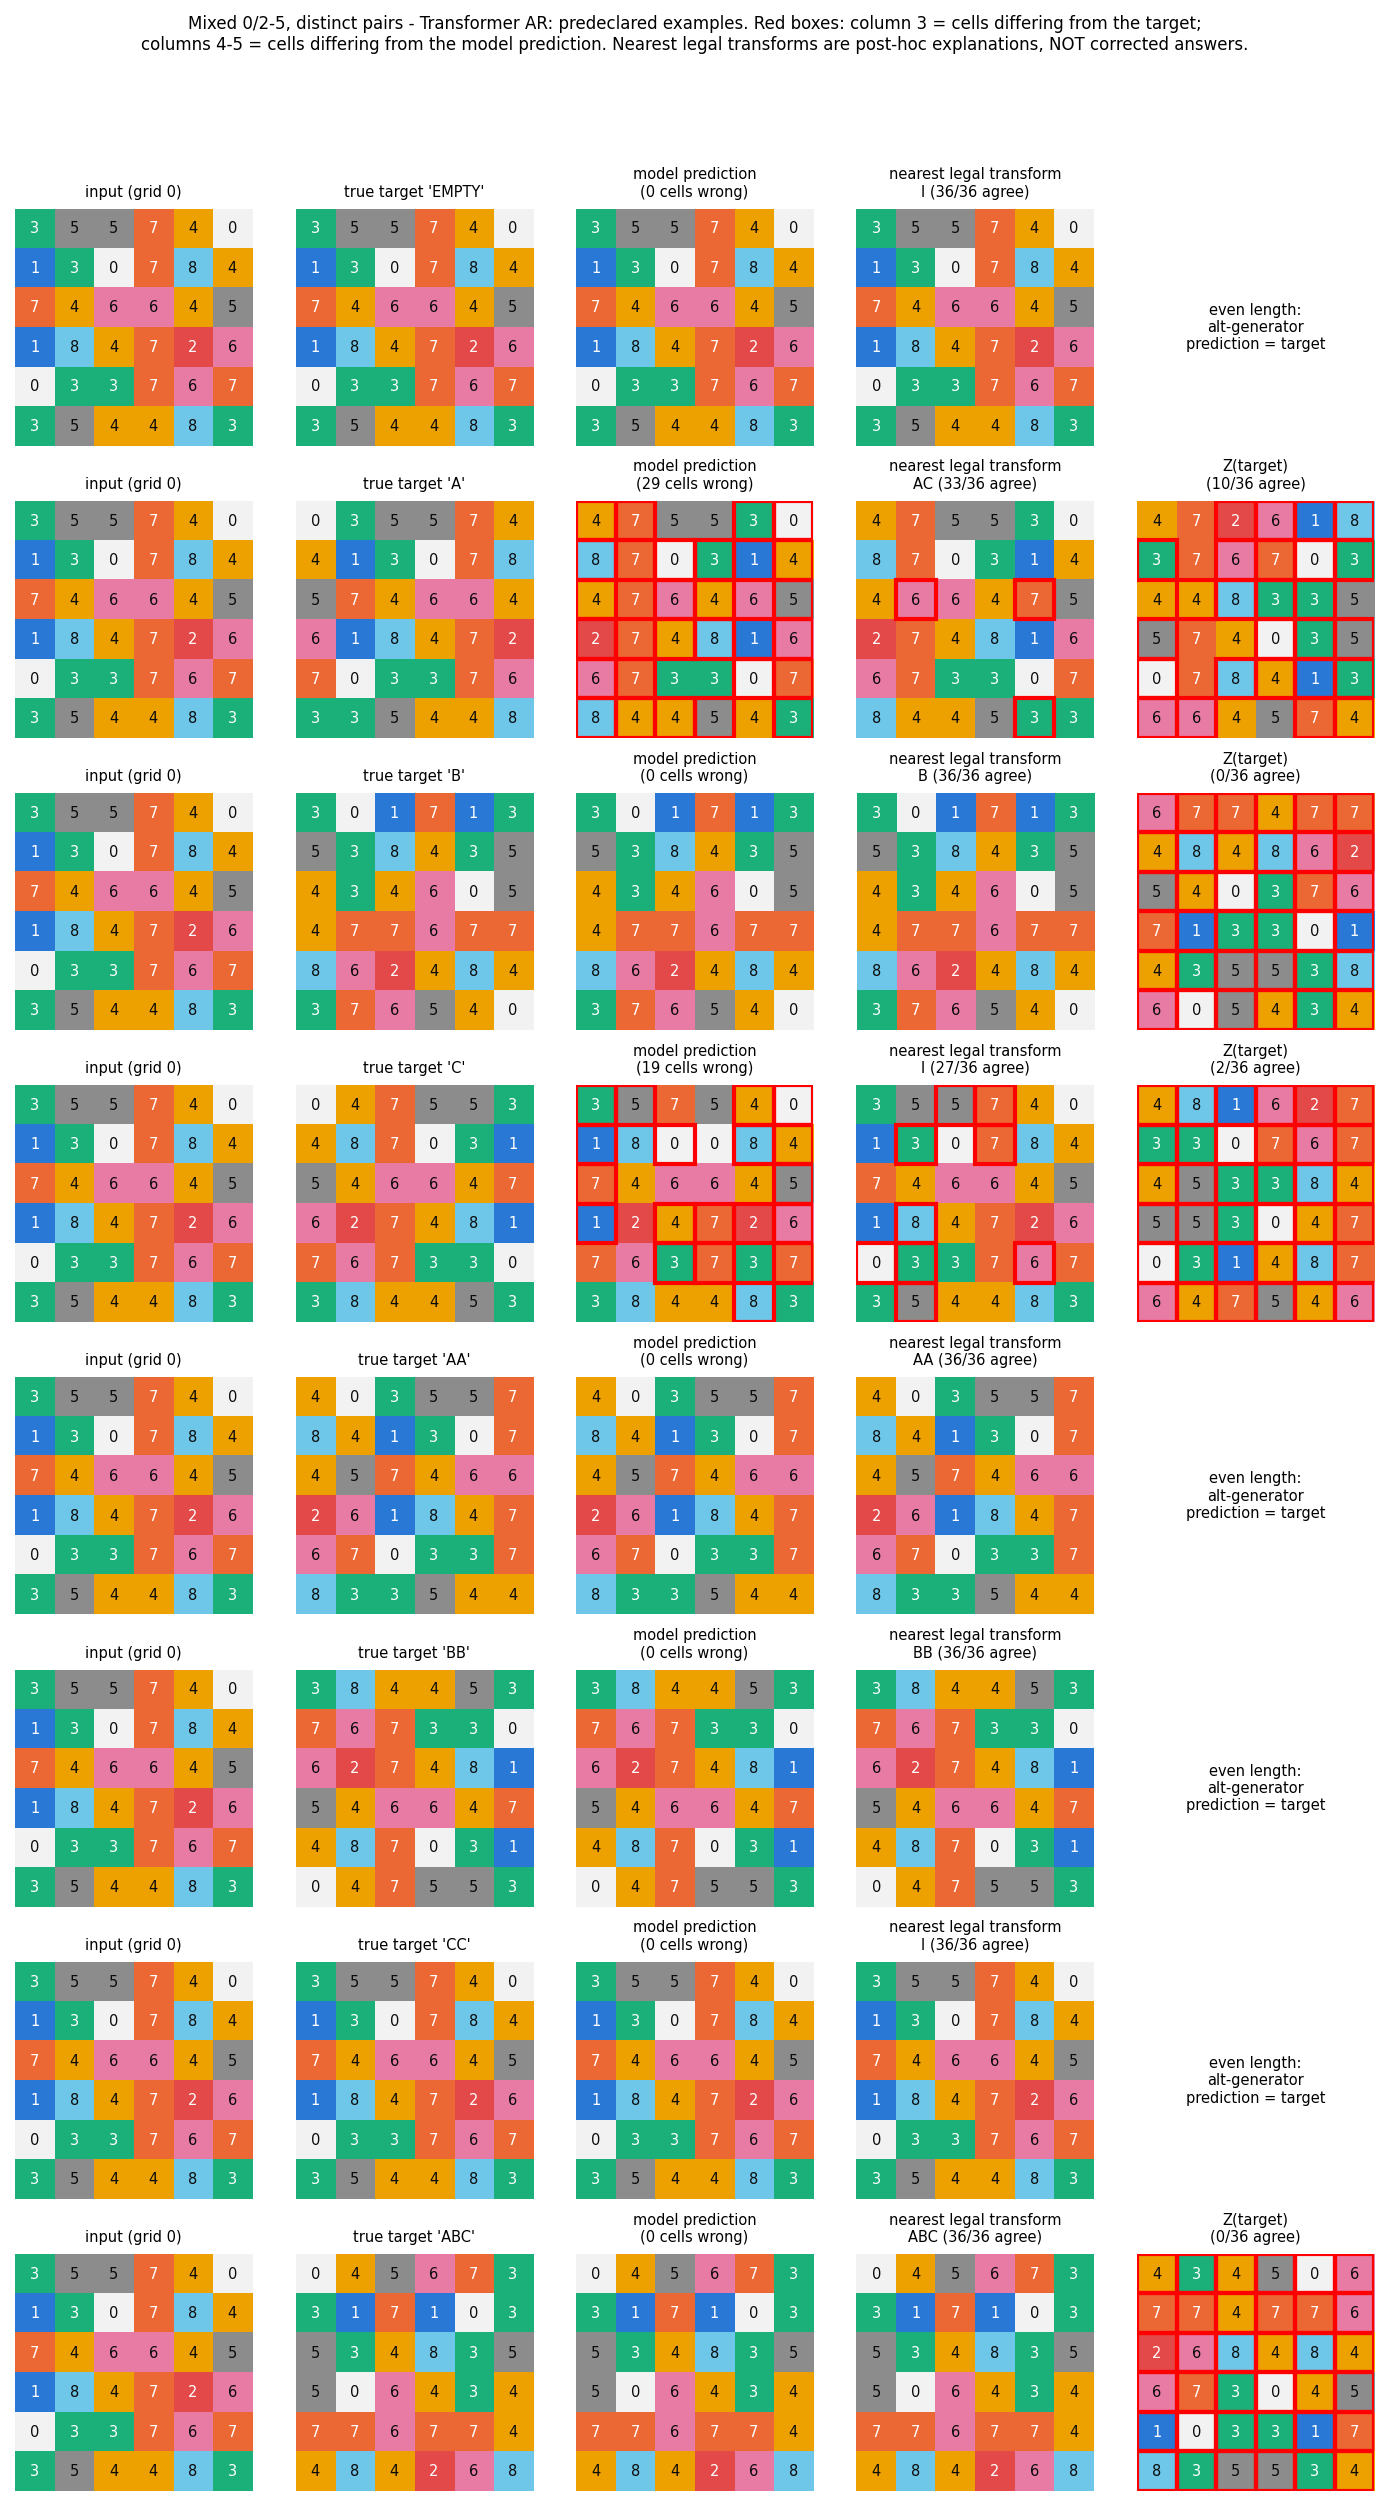

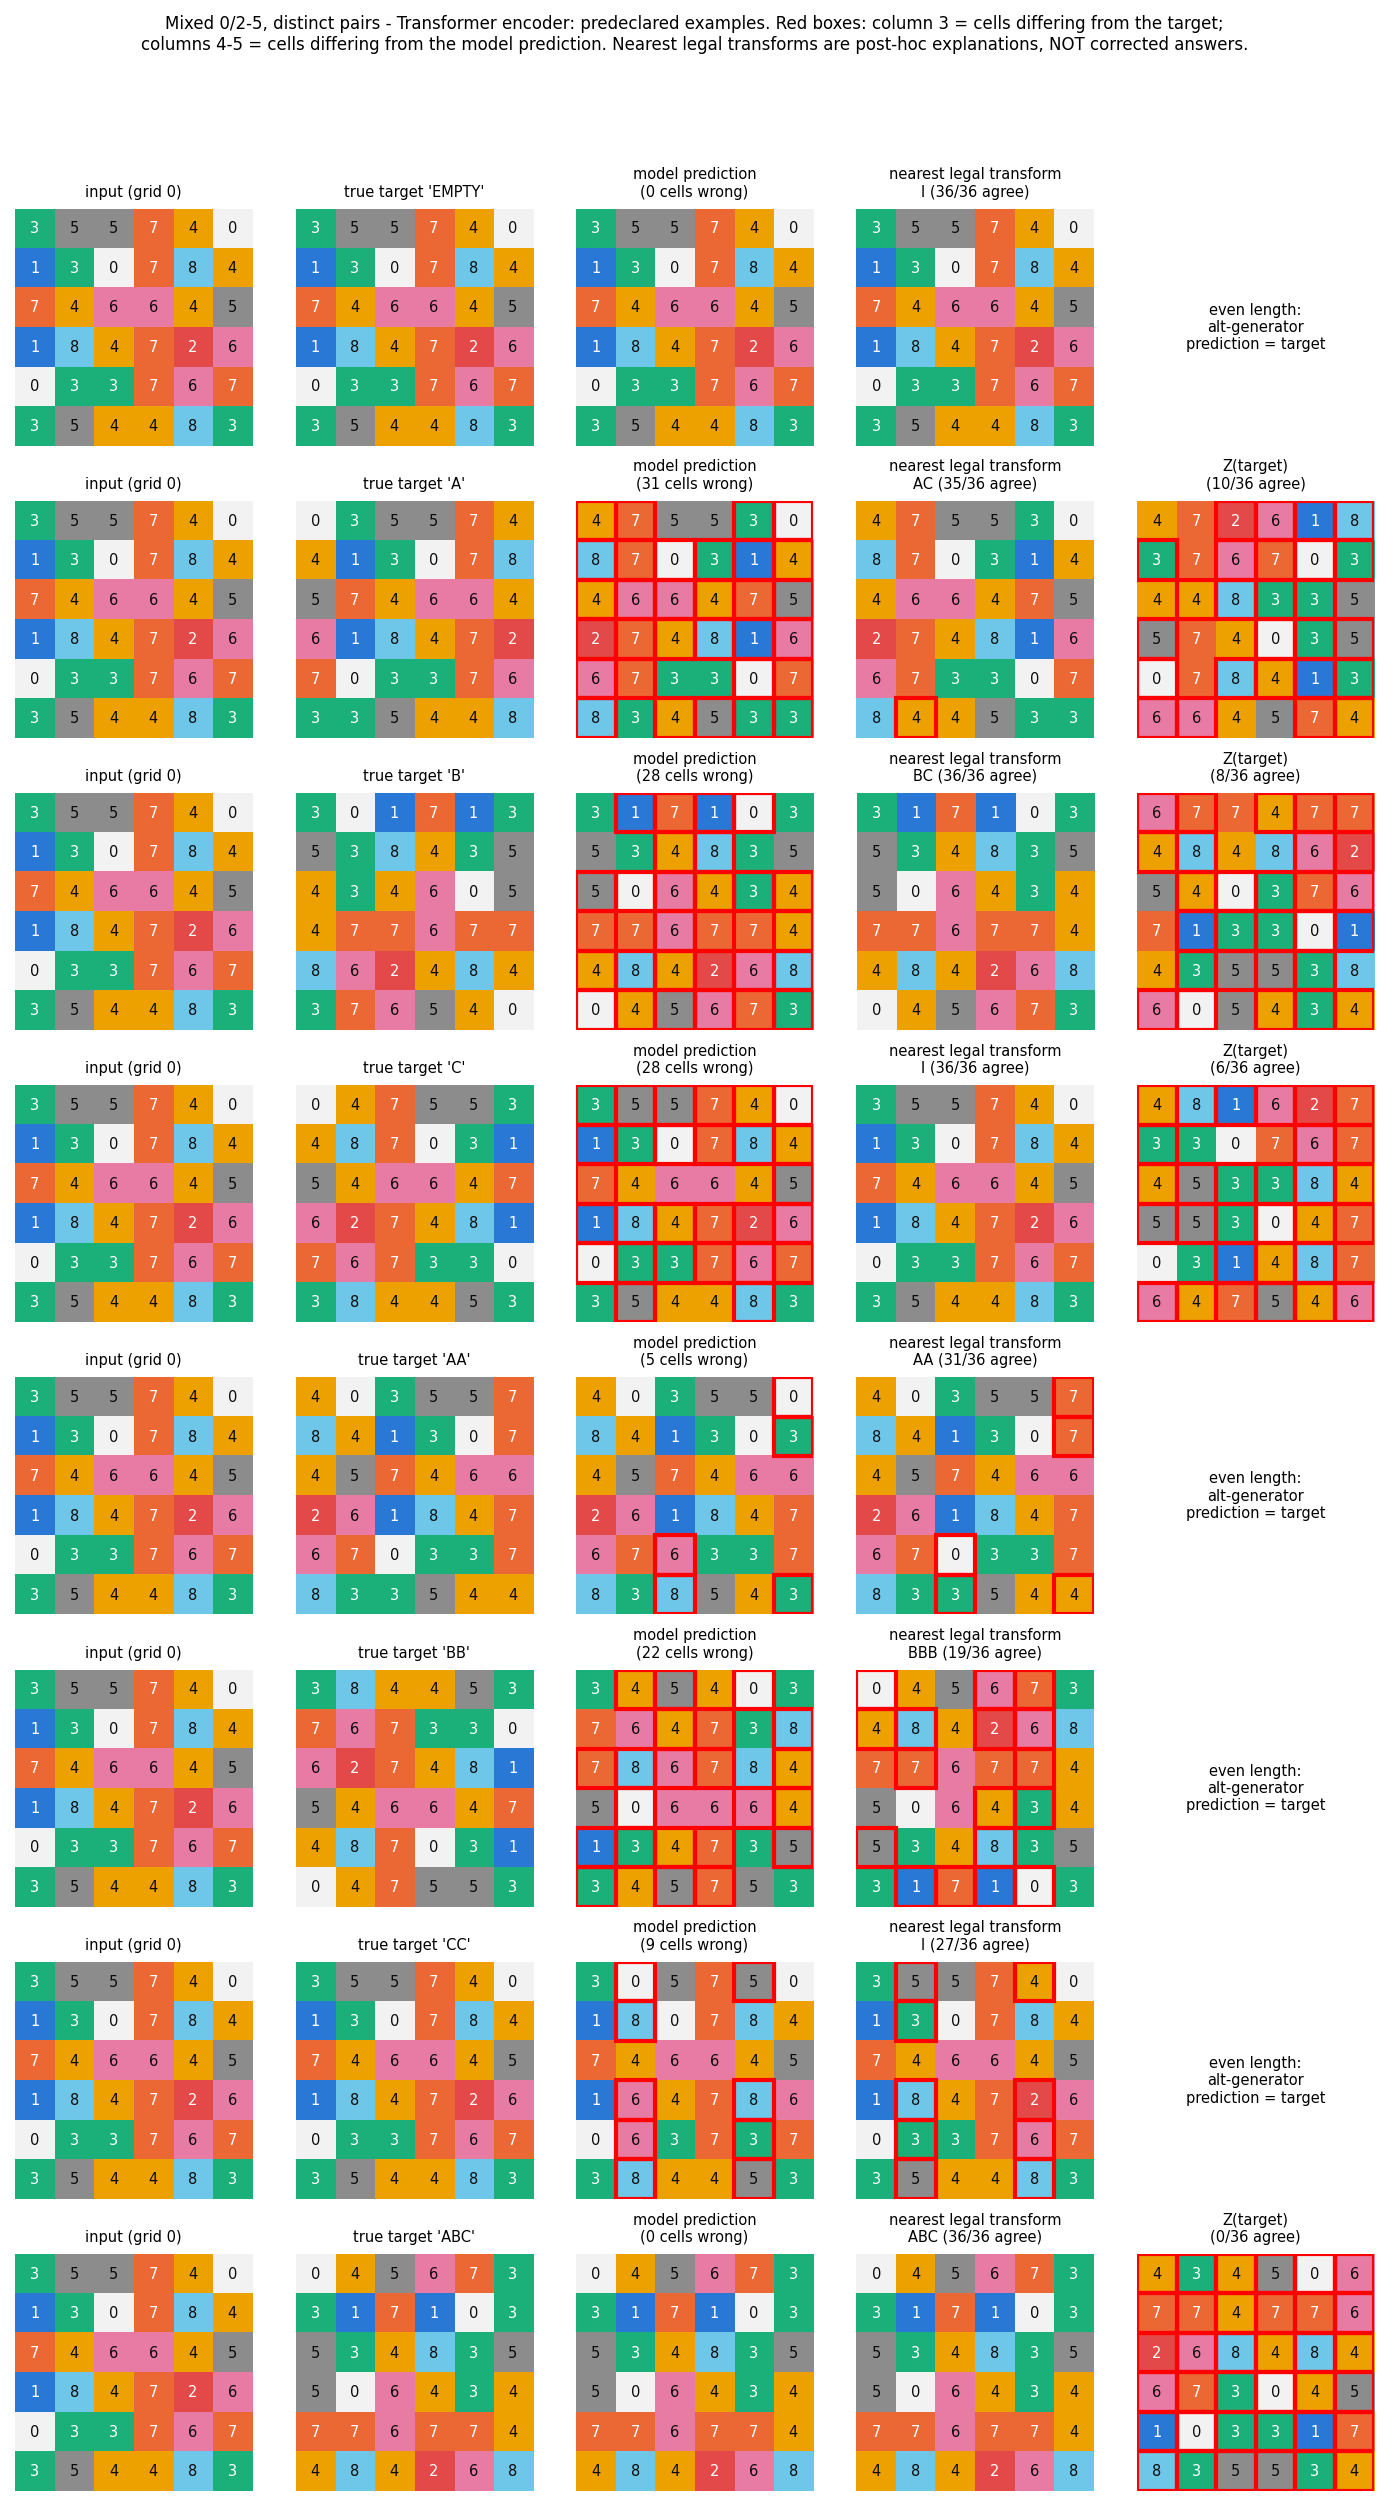

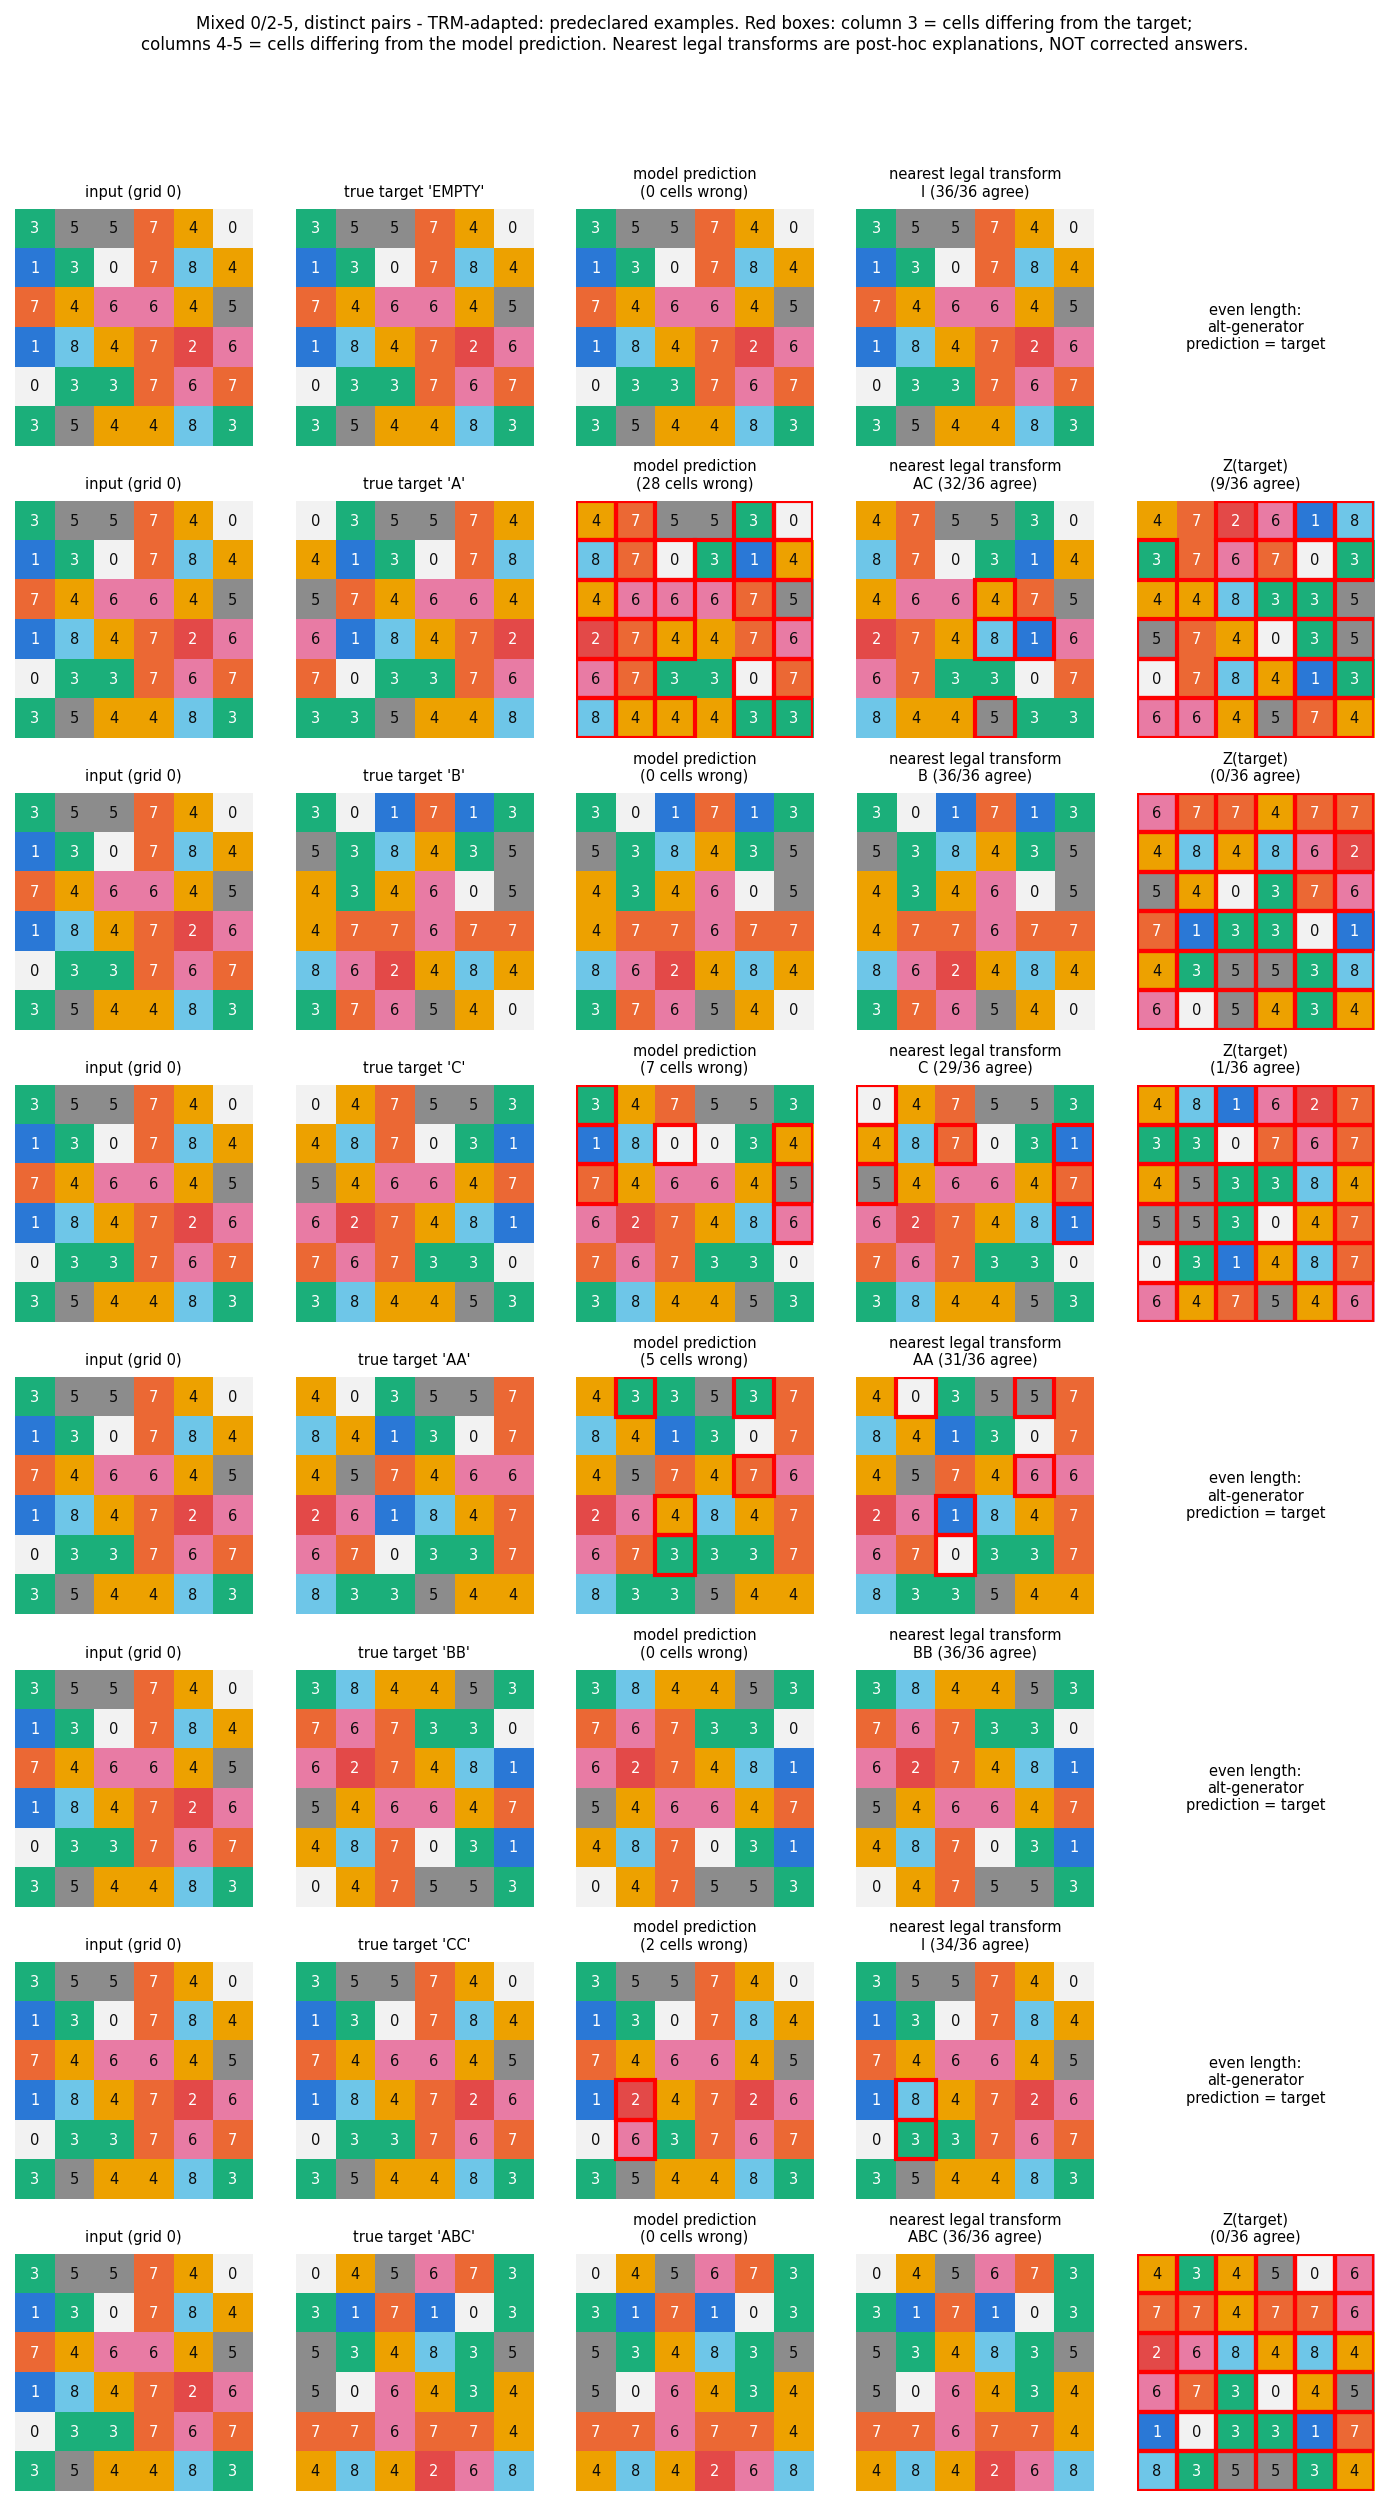

In [13]:
# Stable rules / source maps / composition / controls / paired comparison / examples
show("08_stable"); show("13_exact"); show("10_source"); show("09_composition"); show("06_nearest"); show("07_alternate")
display(R["controls"]["summary"])
show("11_paired"); show("12_examples")


In [14]:
# --- Export and concise summary of ACTUAL results --------------------------------------------------------
from decompositionality.mixed_reports import make_compact_archive
arch = make_compact_archive(cfg.experiment_dir)
display(Markdown((cfg.experiment_dir / "tables" / "f_summary.md").read_text()))
display(Markdown(pathlib.Path(R["report_path"]).read_text()))
if DOWNLOAD_ARCHIVE and IN_COLAB:
    from google.colab import files
    files.download(str(arch))


Compact archive: /content/drive/MyDrive/decompositionality_results/mixed_length_02345/mixed_02345_all_pairs/results_mixed_02345_all_pairs.zip (139.2 MiB)


# mixed_02345_all_pairs: singles (never trained) vs seen support

Integer exact successes / records on the held-out test grids. Lengths 3-5 are SEEN strings on NEW grids (not unseen-combination generalization). Overall micro = record-weighted over 364 words (dominated by length 5); length-macro = lengths 0..5 equally weighted. One seed; no error bars.

seen_support_fit = INADEQUATE if any seen category (pairs, len3, len4, len5) is below 0.9: single-operation failure of such a model is NOT a clean decomposition failure.

| model | selected_step | A | B | C | singles_macro_exact | EMPTY | seen_pairs | unseen_pairs | len3 | len4 | len5 | overall_micro | overall_length_macro | seen_support_fit |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Transformer AR | 4750 | 988/1000 | 869/1000 | 0/1000 | 0.6190 | 1000/1000 | 9000/9000 | N/A | 26999/27000 | 80995/81000 | 242934/243000 | 0.9967 | 0.9364 | adequate |
| Looped Transformer AR (tied) | 5000 | 879/1000 | 994/1000 | 183/1000 | 0.6853 | 1000/1000 | 8975/9000 | N/A | 26787/27000 | 79195/81000 | 235386/243000 | 0.9709 | 0.9368 | adequate |
| Transformer encoder | 4500 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 8998/9000 | N/A | 26999/27000 | 80953/81000 | 242888/243000 | 0.9913 | 0.8331 | adequate |
| Looped Transformer encoder (tied) | 4250 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 8998/9000 | N/A | 26979/27000 | 80251/81000 | 239872/243000 | 0.9810 | 0.8295 | adequate |
| ViT (2x2 patches) | 5000 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 8989/9000 | N/A | 26965/27000 | 80636/81000 | 240287/243000 | 0.9832 | 0.8303 | adequate |
| Looped ViT (tied baseline) | 5000 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 8982/9000 | N/A | 26566/27000 | 74642/81000 | 209744/243000 | 0.8817 | 0.7944 | INADEQUATE |
| TRM-adapted | 5000 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 9000/9000 | N/A | 27000/27000 | 80984/81000 | 242862/243000 | 0.9913 | 0.8332 | adequate |
| ResCNN-FiLM | 4750 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 9000/9000 | N/A | 26999/27000 | 80998/81000 | 242884/243000 | 0.9914 | 0.8332 | adequate |
| U-Net-FiLM | 5000 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 8999/9000 | N/A | 26986/27000 | 80676/81000 | 239027/243000 | 0.9799 | 0.8298 | adequate |


# Generalization-failure diagnostics (mixed family; analysis generalization-failure-diagnostics-v2)

Generated automatically from the saved prediction artifacts listed below. It describes model BEHAVIOUR on test inputs. Compatibility with an explanation does not establish internal representations or causality; one training seed only.

Definitions: a fitted fixed rule is **stable** if its DIAG exact fidelity >= 0.95; a source map is **adequate** if its DIAG cell fidelity >= 0.9. DIAG = disjoint half of the base grids not used for fitting.

## 1. Data coverage and provenance

| experiment | model | status |
|---|---|---|
| mixed_02345_all_pairs | transformer_ar | predictions available (original) |
| mixed_02345_all_pairs | looped_transformer_ar | predictions available (original) |
| mixed_02345_all_pairs | transformer_encoder | predictions available (original) |
| mixed_02345_all_pairs | looped_transformer_encoder | predictions available (original) |
| mixed_02345_all_pairs | vit | predictions available (original) |
| mixed_02345_all_pairs | looped_vit | predictions available (original) |
| mixed_02345_all_pairs | trm | predictions available (original) |
| mixed_02345_all_pairs | rescnn_film | predictions available (original) |
| mixed_02345_all_pairs | unet_film | predictions available (original) |
| mixed_02345_distinct_pairs | transformer_ar | predictions available (original) |
| mixed_02345_distinct_pairs | looped_transformer_ar | predictions available (original) |
| mixed_02345_distinct_pairs | transformer_encoder | predictions available (original) |
| mixed_02345_distinct_pairs | looped_transformer_encoder | predictions available (original) |
| mixed_02345_distinct_pairs | vit | predictions available (original) |
| mixed_02345_distinct_pairs | looped_vit | predictions available (original) |
| mixed_02345_distinct_pairs | trm | predictions available (original) |
| mixed_02345_distinct_pairs | rescnn_film | predictions available (original) |
| mixed_02345_distinct_pairs | unet_film | predictions available (original) |

### Audit

| experiment | model | source | n_records | n_strings | selected_step | code_commit_at_eval | decoding | duplicate_keys | invalid_records | target_oracle_mismatches | input_manifest_mismatches | attribution_blocked |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| mixed_02345_all_pairs | transformer_ar | original | 364000 | 364 | 4750 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| mixed_02345_all_pairs | looped_transformer_ar | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| mixed_02345_all_pairs | transformer_encoder | original | 364000 | 364 | 4500 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_all_pairs | looped_transformer_encoder | original | 364000 | 364 | 4250 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_all_pairs | vit | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_all_pairs | looped_vit | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_all_pairs | trm | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax of final refinement); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_all_pairs | rescnn_film | original | 364000 | 364 | 4750 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_all_pairs | unet_film | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | transformer_ar | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | looped_transformer_ar | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | transformer_encoder | original | 364000 | 364 | 4750 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | looped_transformer_encoder | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | vit | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | looped_vit | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | trm | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax of final refinement); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | rescnn_film | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| mixed_02345_distinct_pairs | unet_film | original | 364000 | 364 | 5000 | d1817bc16d90f7fbaf4f1b7b9ec30fa73ad29abc | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |


- Stored targets re-derived with the independent oracle for **6,552,000** records; mismatches: **0**.
- Test manifests identical across loaded experiments: **True**.
- A synthetic perfect-oracle predictor passed through the same loader/metric code scores 100% on all 364 words (checks the analysis path, not any checkpoint's forward pass).

## 2. Verified observations (recomputed from raw records)

Integer exact successes / records are shown; rates have 4 decimals (e.g. 8998/9000 = 0.9998 is NOT 1). Columns prefixed DIAG use only the diagnostic half of the base grids. N/A = empty category.

| experiment | model | group | exact_correct | n_records | true_exact_acc | true_cell_acc | any_legal_match_records | any_exact_legal_match | exact_set_includes_original_pair | DIAG stable_rule_exact_fidelity | DIAG argmax_map_cell_fidelity | DIAG bijective_perm_cell_fidelity |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| mixed_02345_all_pairs | Transformer AR | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Transformer AR | singles | 1857 | 3000 | 0.6190 | 0.7074 | 2209 | 0.7363 | 0.1173 | 0.7387 | 0.9920 | 0.9897 |
| mixed_02345_all_pairs | Transformer AR | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Transformer AR | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | Transformer AR | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Transformer AR | len4_seen | 80995 | 81000 | 0.9999 | 1.0000 | 80995 | 0.9999 | 0.4691 | 0.9999 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Transformer AR | len5_seen | 242934 | 243000 | 0.9997 | 1.0000 | 242934 | 0.9997 | 0.0000 | 0.9998 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Looped Transformer AR (tied) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Looped Transformer AR (tied) | singles | 2056 | 3000 | 0.6853 | 0.9810 | 2056 | 0.6853 | 0.0000 | 0.6827 | 0.9815 | 0.9810 |
| mixed_02345_all_pairs | Looped Transformer AR (tied) | pairs_seen | 8975 | 9000 | 0.9972 | 0.9999 | 8975 | 0.9972 | 0.9972 | 0.9984 | 0.9999 | 0.9999 |
| mixed_02345_all_pairs | Looped Transformer AR (tied) | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | Looped Transformer AR (tied) | len3_seen | 26787 | 27000 | 0.9921 | 0.9996 | 26787 | 0.9921 | 0.0000 | 0.9921 | 0.9996 | 0.9996 |
| mixed_02345_all_pairs | Looped Transformer AR (tied) | len4_seen | 79195 | 81000 | 0.9777 | 0.9989 | 79195 | 0.9777 | 0.4637 | 0.9788 | 0.9990 | 0.9990 |
| mixed_02345_all_pairs | Looped Transformer AR (tied) | len5_seen | 235386 | 243000 | 0.9687 | 0.9987 | 235386 | 0.9687 | 0.0000 | 0.9694 | 0.9987 | 0.9987 |
| mixed_02345_all_pairs | Transformer encoder | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Transformer encoder | singles | 0 | 3000 | 0.0000 | 0.1004 | 2892 | 0.9640 | 0.9640 | 0.9687 | 0.9991 | 0.9991 |
| mixed_02345_all_pairs | Transformer encoder | pairs_seen | 8998 | 9000 | 0.9998 | 1.0000 | 8998 | 0.9998 | 0.9998 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Transformer encoder | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | Transformer encoder | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Transformer encoder | len4_seen | 80953 | 81000 | 0.9994 | 1.0000 | 80953 | 0.9994 | 0.4686 | 0.9993 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Transformer encoder | len5_seen | 242888 | 243000 | 0.9995 | 1.0000 | 242888 | 0.9995 | 0.0000 | 0.9996 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Looped Transformer encoder (tied) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Looped Transformer encoder (tied) | singles | 0 | 3000 | 0.0000 | 0.1169 | 1026 | 0.3420 | 0.3420 | 0.3387 | 0.8995 | 0.8839 |
| mixed_02345_all_pairs | Looped Transformer encoder (tied) | pairs_seen | 8998 | 9000 | 0.9998 | 1.0000 | 8998 | 0.9998 | 0.9998 | 0.9998 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Looped Transformer encoder (tied) | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | Looped Transformer encoder (tied) | len3_seen | 26979 | 27000 | 0.9992 | 1.0000 | 26979 | 0.9992 | 0.0000 | 0.9992 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Looped Transformer encoder (tied) | len4_seen | 80251 | 81000 | 0.9908 | 0.9997 | 80251 | 0.9908 | 0.4658 | 0.9911 | 0.9997 | 0.9997 |
| mixed_02345_all_pairs | Looped Transformer encoder (tied) | len5_seen | 239872 | 243000 | 0.9871 | 0.9996 | 239872 | 0.9871 | 0.0000 | 0.9873 | 0.9996 | 0.9996 |
| mixed_02345_all_pairs | ViT (2x2 patches) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | ViT (2x2 patches) | singles | 0 | 3000 | 0.0000 | 0.0990 | 1009 | 0.3363 | 0.3363 | 0.3360 | 0.9573 | 0.9087 |
| mixed_02345_all_pairs | ViT (2x2 patches) | pairs_seen | 8989 | 9000 | 0.9988 | 1.0000 | 8989 | 0.9988 | 0.9988 | 0.9989 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | ViT (2x2 patches) | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | ViT (2x2 patches) | len3_seen | 26965 | 27000 | 0.9987 | 1.0000 | 26965 | 0.9987 | 0.0000 | 0.9988 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | ViT (2x2 patches) | len4_seen | 80636 | 81000 | 0.9955 | 0.9999 | 80636 | 0.9955 | 0.4681 | 0.9957 | 0.9999 | 0.9999 |
| mixed_02345_all_pairs | ViT (2x2 patches) | len5_seen | 240287 | 243000 | 0.9888 | 0.9997 | 240287 | 0.9888 | 0.0000 | 0.9886 | 0.9997 | 0.9997 |
| mixed_02345_all_pairs | Looped ViT (tied baseline) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | Looped ViT (tied baseline) | singles | 0 | 3000 | 0.0000 | 0.1041 | 1000 | 0.3333 | 0.3333 | 0.3333 | 0.8486 | 0.8046 |
| mixed_02345_all_pairs | Looped ViT (tied baseline) | pairs_seen | 8982 | 9000 | 0.9980 | 0.9999 | 8982 | 0.9980 | 0.9980 | 0.9980 | 0.9999 | 0.9999 |
| mixed_02345_all_pairs | Looped ViT (tied baseline) | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | Looped ViT (tied baseline) | len3_seen | 26566 | 27000 | 0.9839 | 0.9995 | 26566 | 0.9839 | 0.0000 | 0.9830 | 0.9995 | 0.9995 |
| mixed_02345_all_pairs | Looped ViT (tied baseline) | len4_seen | 74642 | 81000 | 0.9215 | 0.9970 | 74642 | 0.9215 | 0.4560 | 0.9204 | 0.9969 | 0.9969 |
| mixed_02345_all_pairs | Looped ViT (tied baseline) | len5_seen | 209744 | 243000 | 0.8631 | 0.9937 | 209744 | 0.8631 | 0.0000 | 0.8615 | 0.9936 | 0.9936 |
| mixed_02345_all_pairs | TRM-adapted | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | TRM-adapted | singles | 0 | 3000 | 0.0000 | 0.1181 | 2685 | 0.8950 | 0.8950 | 0.8973 | 0.9821 | 0.9821 |
| mixed_02345_all_pairs | TRM-adapted | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | TRM-adapted | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | TRM-adapted | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | TRM-adapted | len4_seen | 80984 | 81000 | 0.9998 | 1.0000 | 80984 | 0.9998 | 0.4690 | 0.9997 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | TRM-adapted | len5_seen | 242862 | 243000 | 0.9994 | 1.0000 | 242862 | 0.9994 | 0.0000 | 0.9995 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | ResCNN-FiLM | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | ResCNN-FiLM | singles | 0 | 3000 | 0.0000 | 0.1013 | 1851 | 0.6170 | 0.6170 | 0.6173 | 0.9214 | 0.9108 |
| mixed_02345_all_pairs | ResCNN-FiLM | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | ResCNN-FiLM | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | ResCNN-FiLM | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | ResCNN-FiLM | len4_seen | 80998 | 81000 | 1.0000 | 1.0000 | 80998 | 1.0000 | 0.4691 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | ResCNN-FiLM | len5_seen | 242884 | 243000 | 0.9995 | 1.0000 | 242884 | 0.9995 | 0.0000 | 0.9996 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | U-Net-FiLM | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | U-Net-FiLM | singles | 0 | 3000 | 0.0000 | 0.1030 | 1996 | 0.6653 | 0.6653 | 0.6667 | 0.9406 | 0.9391 |
| mixed_02345_all_pairs | U-Net-FiLM | pairs_seen | 8999 | 9000 | 0.9999 | 1.0000 | 8999 | 0.9999 | 0.9999 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | U-Net-FiLM | pairs_unseen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| mixed_02345_all_pairs | U-Net-FiLM | len3_seen | 26986 | 27000 | 0.9995 | 1.0000 | 26986 | 0.9995 | 0.0000 | 0.9996 | 1.0000 | 1.0000 |
| mixed_02345_all_pairs | U-Net-FiLM | len4_seen | 80676 | 81000 | 0.9960 | 0.9999 | 80676 | 0.9960 | 0.4690 | 0.9960 | 0.9999 | 0.9999 |
| mixed_02345_all_pairs | U-Net-FiLM | len5_seen | 239027 | 243000 | 0.9837 | 0.9965 | 239027 | 0.9837 | 0.0000 | 0.9834 | 0.9978 | 0.9978 |
| mixed_02345_distinct_pairs | Transformer AR | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Transformer AR | singles | 994 | 3000 | 0.3313 | 0.5223 | 1047 | 0.3490 | 0.0177 | 0.3547 | 0.9056 | 0.8883 |
| mixed_02345_distinct_pairs | Transformer AR | pairs_seen | 6000 | 6000 | 1.0000 | 1.0000 | 6000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Transformer AR | pairs_unseen | 2992 | 3000 | 0.9973 | 0.9999 | 2992 | 0.9973 | 0.0000 | 0.9960 | 0.9999 | 0.9999 |
| mixed_02345_distinct_pairs | Transformer AR | len3_seen | 26998 | 27000 | 0.9999 | 1.0000 | 26998 | 0.9999 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Transformer AR | len4_seen | 80995 | 81000 | 0.9999 | 1.0000 | 80995 | 0.9999 | 0.2963 | 0.9999 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Transformer AR | len5_seen | 242935 | 243000 | 0.9997 | 1.0000 | 242935 | 0.9997 | 0.0000 | 0.9997 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Looped Transformer AR (tied) | EMPTY | 998 | 1000 | 0.9980 | 0.9999 | 998 | 0.9980 | 0.0000 | 0.9960 | 0.9998 | 0.9998 |
| mixed_02345_distinct_pairs | Looped Transformer AR (tied) | singles | 0 | 3000 | 0.0000 | 0.3560 | 5 | 0.0017 | 0.0000 | 0.0007 | 0.7481 | 0.7309 |
| mixed_02345_distinct_pairs | Looped Transformer AR (tied) | pairs_seen | 5920 | 6000 | 0.9867 | 0.9994 | 5920 | 0.9867 | 0.9867 | 0.9873 | 0.9994 | 0.9994 |
| mixed_02345_distinct_pairs | Looped Transformer AR (tied) | pairs_unseen | 139 | 3000 | 0.0463 | 0.7618 | 139 | 0.0463 | 0.0000 | 0.0533 | 0.8369 | 0.8318 |
| mixed_02345_distinct_pairs | Looped Transformer AR (tied) | len3_seen | 25672 | 27000 | 0.9508 | 0.9973 | 25672 | 0.9508 | 0.0000 | 0.9539 | 0.9975 | 0.9975 |
| mixed_02345_distinct_pairs | Looped Transformer AR (tied) | len4_seen | 70490 | 81000 | 0.8702 | 0.9928 | 70490 | 0.8702 | 0.2645 | 0.8704 | 0.9929 | 0.9929 |
| mixed_02345_distinct_pairs | Looped Transformer AR (tied) | len5_seen | 205946 | 243000 | 0.8475 | 0.9918 | 205946 | 0.8475 | 0.0000 | 0.8500 | 0.9920 | 0.9920 |
| mixed_02345_distinct_pairs | Transformer encoder | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Transformer encoder | singles | 0 | 3000 | 0.0000 | 0.1005 | 2491 | 0.8303 | 0.5033 | 0.8347 | 0.9941 | 0.9941 |
| mixed_02345_distinct_pairs | Transformer encoder | pairs_seen | 5998 | 6000 | 0.9997 | 1.0000 | 5998 | 0.9997 | 0.9997 | 0.9997 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Transformer encoder | pairs_unseen | 0 | 3000 | 0.0000 | 0.6416 | 0 | 0.0000 | 0.0000 | 0.0000 | 0.8117 | 0.7448 |
| mixed_02345_distinct_pairs | Transformer encoder | len3_seen | 26930 | 27000 | 0.9974 | 0.9999 | 26930 | 0.9974 | 0.0000 | 0.9970 | 0.9999 | 0.9999 |
| mixed_02345_distinct_pairs | Transformer encoder | len4_seen | 80866 | 81000 | 0.9983 | 1.0000 | 80866 | 0.9983 | 0.2958 | 0.9981 | 0.9999 | 0.9999 |
| mixed_02345_distinct_pairs | Transformer encoder | len5_seen | 241394 | 243000 | 0.9934 | 0.9998 | 241394 | 0.9934 | 0.0000 | 0.9934 | 0.9998 | 0.9998 |
| mixed_02345_distinct_pairs | Looped Transformer encoder (tied) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Looped Transformer encoder (tied) | singles | 0 | 3000 | 0.0000 | 0.1006 | 1976 | 0.6587 | 0.3253 | 0.6567 | 0.9626 | 0.9371 |
| mixed_02345_distinct_pairs | Looped Transformer encoder (tied) | pairs_seen | 5989 | 6000 | 0.9982 | 0.9999 | 5989 | 0.9982 | 0.9982 | 0.9983 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Looped Transformer encoder (tied) | pairs_unseen | 871 | 3000 | 0.2903 | 0.6010 | 871 | 0.2903 | 0.0000 | 0.2873 | 0.8931 | 0.8198 |
| mixed_02345_distinct_pairs | Looped Transformer encoder (tied) | len3_seen | 26983 | 27000 | 0.9994 | 1.0000 | 26983 | 0.9994 | 0.0000 | 0.9993 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Looped Transformer encoder (tied) | len4_seen | 80391 | 81000 | 0.9925 | 0.9998 | 80391 | 0.9925 | 0.2939 | 0.9921 | 0.9998 | 0.9998 |
| mixed_02345_distinct_pairs | Looped Transformer encoder (tied) | len5_seen | 242277 | 243000 | 0.9970 | 0.9999 | 242277 | 0.9970 | 0.0000 | 0.9969 | 0.9999 | 0.9999 |
| mixed_02345_distinct_pairs | ViT (2x2 patches) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | ViT (2x2 patches) | singles | 0 | 3000 | 0.0000 | 0.1012 | 311 | 0.1037 | 0.0000 | 0.0987 | 0.8762 | 0.8683 |
| mixed_02345_distinct_pairs | ViT (2x2 patches) | pairs_seen | 5998 | 6000 | 0.9997 | 1.0000 | 5998 | 0.9997 | 0.9997 | 0.9993 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | ViT (2x2 patches) | pairs_unseen | 0 | 3000 | 0.0000 | 0.5508 | 0 | 0.0000 | 0.0000 | 0.0000 | 0.7750 | 0.7435 |
| mixed_02345_distinct_pairs | ViT (2x2 patches) | len3_seen | 26660 | 27000 | 0.9874 | 0.9996 | 26660 | 0.9874 | 0.0000 | 0.9879 | 0.9996 | 0.9996 |
| mixed_02345_distinct_pairs | ViT (2x2 patches) | len4_seen | 73009 | 81000 | 0.9013 | 0.9965 | 73009 | 0.9013 | 0.2831 | 0.9002 | 0.9965 | 0.9965 |
| mixed_02345_distinct_pairs | ViT (2x2 patches) | len5_seen | 202306 | 243000 | 0.8325 | 0.9930 | 202306 | 0.8325 | 0.0000 | 0.8304 | 0.9930 | 0.9929 |
| mixed_02345_distinct_pairs | Looped ViT (tied baseline) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Looped ViT (tied baseline) | singles | 0 | 3000 | 0.0000 | 0.1016 | 0 | 0.0000 | 0.0000 | 0.0000 | 0.8302 | 0.7807 |
| mixed_02345_distinct_pairs | Looped ViT (tied baseline) | pairs_seen | 5993 | 6000 | 0.9988 | 1.0000 | 5993 | 0.9988 | 0.9988 | 0.9993 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Looped ViT (tied baseline) | pairs_unseen | 0 | 3000 | 0.0000 | 0.3952 | 0 | 0.0000 | 0.0000 | 0.0000 | 0.8211 | 0.7404 |
| mixed_02345_distinct_pairs | Looped ViT (tied baseline) | len3_seen | 26966 | 27000 | 0.9987 | 1.0000 | 26966 | 0.9987 | 0.0000 | 0.9987 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | Looped ViT (tied baseline) | len4_seen | 80063 | 81000 | 0.9884 | 0.9997 | 80063 | 0.9884 | 0.2925 | 0.9880 | 0.9997 | 0.9997 |
| mixed_02345_distinct_pairs | Looped ViT (tied baseline) | len5_seen | 235888 | 243000 | 0.9707 | 0.9991 | 235888 | 0.9707 | 0.0000 | 0.9707 | 0.9991 | 0.9991 |
| mixed_02345_distinct_pairs | TRM-adapted | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | TRM-adapted | singles | 447 | 3000 | 0.1490 | 0.6645 | 478 | 0.1593 | 0.0103 | 0.1620 | 0.9265 | 0.8976 |
| mixed_02345_distinct_pairs | TRM-adapted | pairs_seen | 6000 | 6000 | 1.0000 | 1.0000 | 6000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | TRM-adapted | pairs_unseen | 1005 | 3000 | 0.3350 | 0.8498 | 1005 | 0.3350 | 0.0000 | 0.3340 | 0.9098 | 0.8479 |
| mixed_02345_distinct_pairs | TRM-adapted | len3_seen | 26998 | 27000 | 0.9999 | 1.0000 | 26998 | 0.9999 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | TRM-adapted | len4_seen | 80976 | 81000 | 0.9997 | 1.0000 | 80976 | 0.9997 | 0.2962 | 0.9997 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | TRM-adapted | len5_seen | 242384 | 243000 | 0.9975 | 0.9999 | 242384 | 0.9975 | 0.0000 | 0.9975 | 0.9999 | 0.9999 |
| mixed_02345_distinct_pairs | ResCNN-FiLM | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | ResCNN-FiLM | singles | 0 | 3000 | 0.0000 | 0.0981 | 408 | 0.1360 | 0.0027 | 0.1347 | 0.8934 | 0.8934 |
| mixed_02345_distinct_pairs | ResCNN-FiLM | pairs_seen | 6000 | 6000 | 1.0000 | 1.0000 | 6000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | ResCNN-FiLM | pairs_unseen | 884 | 3000 | 0.2947 | 0.4452 | 897 | 0.2990 | 0.0000 | 0.2973 | 0.8977 | 0.8977 |
| mixed_02345_distinct_pairs | ResCNN-FiLM | len3_seen | 26997 | 27000 | 0.9999 | 1.0000 | 26997 | 0.9999 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | ResCNN-FiLM | len4_seen | 80998 | 81000 | 1.0000 | 1.0000 | 80998 | 1.0000 | 0.2963 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | ResCNN-FiLM | len5_seen | 242944 | 243000 | 0.9998 | 1.0000 | 242944 | 0.9998 | 0.0000 | 0.9998 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | U-Net-FiLM | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | U-Net-FiLM | singles | 0 | 3000 | 0.0000 | 0.0983 | 1095 | 0.3650 | 0.0373 | 0.3640 | 0.8957 | 0.8873 |
| mixed_02345_distinct_pairs | U-Net-FiLM | pairs_seen | 6000 | 6000 | 1.0000 | 1.0000 | 6000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | U-Net-FiLM | pairs_unseen | 6 | 3000 | 0.0020 | 0.4445 | 177 | 0.0590 | 0.0000 | 0.0580 | 0.8156 | 0.7760 |
| mixed_02345_distinct_pairs | U-Net-FiLM | len3_seen | 26991 | 27000 | 0.9997 | 1.0000 | 26991 | 0.9997 | 0.0000 | 0.9996 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | U-Net-FiLM | len4_seen | 80878 | 81000 | 0.9985 | 1.0000 | 80878 | 0.9985 | 0.2963 | 0.9984 | 1.0000 | 1.0000 |
| mixed_02345_distinct_pairs | U-Net-FiLM | len5_seen | 242619 | 243000 | 0.9984 | 1.0000 | 242619 | 0.9984 | 0.0000 | 0.9984 | 1.0000 | 1.0000 |


### mixed_02345_distinct_pairs - population 'OOD: singles + unseen pairs'

- Exact-correct: 7,338 of 54,000 records (0.135889).
- Wrong predictions exactly equal to SOME legal transform of the input: 6,554 of 46,662 wrong records (0.1405).
- Wrong predictions whose exact-match set includes an ORIGINAL length-two pair transformation: 2,690 of 46,662.
- (model, word) cells with a STABLE fitted fixed rule: 10 of 54 (of which the rule is the truth in 5, an original pair transformation in 2, the Z-twisted alternative in 4).
  - most frequent stable WRONG rules (canonical words): I x3, BC x2
- Composition of fitted single-op maps (DIAG, all words of length >= 2): mean exact agreement with model predictions 0.0380, with true targets 0.0400; 2744 of 3240 rows WEAK (unstable single maps).

### mixed_02345_all_pairs - population 'OOD: singles + unseen pairs'

- Exact-correct: 3,913 of 27,000 records (0.144926).
- Wrong predictions exactly equal to SOME legal transform of the input: 12,811 of 23,087 wrong records (0.5549).
- Wrong predictions whose exact-match set includes an ORIGINAL length-two pair transformation: 12,811 of 23,087.
- (model, word) cells with a STABLE fitted fixed rule: 12 of 27 (of which the rule is the truth in 2, an original pair transformation in 10, the Z-twisted alternative in 0).
  - most frequent stable WRONG rules (canonical words): I x7, BC x1, AC x1, AA x1
- Composition of fitted single-op maps (DIAG, all words of length >= 2): mean exact agreement with model predictions 0.1665, with true targets 0.1695; 1612 of 3240 rows WEAK (unstable single maps).

### Hypothesis coverage with explicit denominators (population: OOD: singles + unseen pairs)

matched = UNIQUE records matched by ANY non-truth candidate of the rule (union within the rule; rules overlap with each other). conditional = matched / eligible; unconditional = matched / population. any-legal = records exactly equal to some legal transform (an upper bound for unconditional coverage).

(summed over models)

| experiment | hypothesis_type | population | any_legal | eligible | matched | conditional | unconditional |
|---|---|---|---|---|---|---|---|
| mixed_02345_all_pairs | identity | 27000 | 16724 | 27000 | 7361 | 0.2726 | 0.2726 |
| mixed_02345_all_pairs | first_op | 27000 | 16724 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_all_pairs | last_op | 27000 | 16724 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_all_pairs | first_and_last | 27000 | 16724 | 27000 | 9221 | 0.3415 | 0.3415 |
| mixed_02345_all_pairs | first_two | 27000 | 16724 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_all_pairs | last_two | 27000 | 16724 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_all_pairs | drop_one | 27000 | 16724 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_all_pairs | reverse | 27000 | 16724 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_all_pairs | collapse_adjacent | 27000 | 16724 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_all_pairs | dedupe_global | 27000 | 16724 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_all_pairs | duplicate_single | 27000 | 16724 | 27000 | 9221 | 0.3415 | 0.3415 |
| mixed_02345_all_pairs | original_pair | 27000 | 16724 | 27000 | 12811 | 0.4745 | 0.4745 |
| mixed_02345_distinct_pairs | identity | 54000 | 13892 | 45000 | 3680 | 0.0818 | 0.0681 |
| mixed_02345_distinct_pairs | first_op | 54000 | 13892 | 27000 | 0 | 0.0000 | 0.0000 |
| mixed_02345_distinct_pairs | last_op | 54000 | 13892 | 27000 | 0 | 0.0000 | 0.0000 |
| mixed_02345_distinct_pairs | first_and_last | 54000 | 13892 | 27000 | 3679 | 0.1363 | 0.0681 |
| mixed_02345_distinct_pairs | first_two | 54000 | 13892 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_distinct_pairs | last_two | 54000 | 13892 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_distinct_pairs | drop_one | 54000 | 13892 | 27000 | 0 | 0.0000 | 0.0000 |
| mixed_02345_distinct_pairs | reverse | 54000 | 13892 | 0 | 0 | N/A | 0.0000 |
| mixed_02345_distinct_pairs | collapse_adjacent | 54000 | 13892 | 27000 | 0 | 0.0000 | 0.0000 |
| mixed_02345_distinct_pairs | dedupe_global | 54000 | 13892 | 27000 | 0 | 0.0000 | 0.0000 |
| mixed_02345_distinct_pairs | duplicate_single | 54000 | 13892 | 27000 | 3679 | 0.1363 | 0.0681 |
| mixed_02345_distinct_pairs | original_pair | 54000 | 13892 | 54000 | 2690 | 0.0498 | 0.0498 |


### Paired comparison (mixed_02345_all_pairs vs mixed_02345_distinct_pairs; same model, word and base grid)

| model | identical_prediction_rate | delta_exact (mixed_02345_all_pairs - mixed_02345_distinct_pairs) | delta_any_legal (mixed_02345_all_pairs - mixed_02345_distinct_pairs) |
|---|---|---|---|
| looped_transformer_ar | 0.8300 | 0.1215 | 0.1215 |
| looped_transformer_encoder | 0.9743 | -0.0011 | -0.0037 |
| looped_vit | 0.8603 | -0.0796 | -0.0769 |
| rescnn_film | 0.9866 | 0.0057 | 0.0096 |
| transformer_ar | 0.9937 | 0.0024 | 0.0032 |
| transformer_encoder | 0.9847 | 0.0128 | 0.0139 |
| trm | 0.9842 | 0.0056 | 0.0129 |
| unet_film | 0.9731 | -0.0022 | -0.0002 |
| vit | 0.8434 | 0.1344 | 0.1363 |


## 3. Hypotheses compatible with the observations (behavioural, non-causal)

- mixed_02345_all_pairs: rule 'original_pair' exactly matches 12,811 of 27,000 records in 'OOD: singles + unseen pairs' (unconditional 0.4745; conditional 0.4745 of 27,000 eligible).
- mixed_02345_all_pairs: rule 'duplicate_single' exactly matches 9,221 of 27,000 records in 'OOD: singles + unseen pairs' (unconditional 0.3415; conditional 0.3415 of 27,000 eligible).
- mixed_02345_all_pairs: rule 'first_and_last' exactly matches 9,221 of 27,000 records in 'OOD: singles + unseen pairs' (unconditional 0.3415; conditional 0.3415 of 27,000 eligible).
- mixed_02345_all_pairs: rule 'identity' exactly matches 7,361 of 27,000 records in 'OOD: singles + unseen pairs' (unconditional 0.2726; conditional 0.2726 of 27,000 eligible).

## 4. Unresolved cases

(model, word) cells in 'OOD: singles + unseen pairs' that are mostly wrong (exact < 0.5) with no stable legal rule (DIAG exact < 0.5) AND no adequate source map (DIAG cell fidelity < 0.9): **38**. This only rules out these explanation families; it is not evidence of randomness.

| experiment | model | string |
|---|---|---|
| mixed_02345_all_pairs | looped_transformer_encoder | B |
| mixed_02345_all_pairs | looped_vit | A B |
| mixed_02345_all_pairs | rescnn_film | B |
| mixed_02345_all_pairs | unet_film | B |
| mixed_02345_all_pairs | vit | A |
| mixed_02345_distinct_pairs | looped_transformer_ar | A B C AA CC |
| mixed_02345_distinct_pairs | looped_transformer_encoder | A AA BB |
| mixed_02345_distinct_pairs | looped_vit | A B C AA BB |
| mixed_02345_distinct_pairs | rescnn_film | A B AA BB |
| mixed_02345_distinct_pairs | transformer_ar | A C |
| mixed_02345_distinct_pairs | transformer_encoder | AA BB CC |
| mixed_02345_distinct_pairs | trm | C AA |
| mixed_02345_distinct_pairs | unet_film | A AA CC |
| mixed_02345_distinct_pairs | vit | A B AA BB CC |


## 5. Limits

- Matching one of the 288 transformations does not identify which synonymous string was executed; ambiguous matches are kept ambiguous.
- DIAG fidelities describe frozen predictions with rules fitted to those predictions; not a benchmark.
- Behavioural compatibility is not a causal or mechanistic claim; one seed only.


## Outputs
`<RESULTS_ROOT>/mixed_length_02345/mixed_02345_all_pairs/`: `manifests/`, `runs/<model>/` (`state.pt` last, `best.pt` selected,
logs), `eval/<model>/` (`test_predictions.npz` with inputs/targets/predictions/slots/lengths for 364,000 records,
`test_per_word.csv`, `test_groups.csv`, `eval_summary.json`, `chunks/`), `figures/`, `tables/`, `diagnostics/`
(tables, figures, per-example diagnostics, fitted maps, `REPORT.md`, `provenance.json`) and
`results_mixed_02345_all_pairs.zip` (no checkpoints, chunks or caches). Smoke runs go to `.../mixed_length_02345/smoke/`.
